In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

# Update this path if Legumin_MD is inside another folder
PDB_PATH = "/content/drive/MyDrive/Legumin_MD/legumin_hexamer.pdb"

if os.path.exists(PDB_PATH):
    print("PDB found!")
    print("File size:", round(os.path.getsize(PDB_PATH) / 1024, 2), "KB")
else:
    print("PDB not found. Check the folder path.")

Mounted at /content/drive
PDB not found. Check the folder path.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PDB_PATH = "/content/drive/MyDrive/Legumin MD/legumin_hexamer.pdb"

if os.path.isfile(PDB_PATH):
    print("PDB found!")
    print("Path:", PDB_PATH)
    print("File size:", round(os.path.getsize(PDB_PATH) / 1024, 2), "KB")
else:
    print("Still not found. Folders in MyDrive:")
    for item in os.listdir("/content/drive/MyDrive"):
        print(item)

Still not found. Folders in MyDrive:
Dhruv
Legumin MD 
Colab Notebooks


In [ ]:
import os

FOLDER = "/content/drive/MyDrive/Legumin MD "
PDB_PATH = os.path.join(FOLDER, "legumin_hexamer.pdb")

print("Folder exists:", os.path.isdir(FOLDER))

if os.path.isdir(FOLDER):
    print("\nFiles in the folder:")
    for item in os.listdir(FOLDER):
        print(repr(item))

    if os.path.isfile(PDB_PATH):
        print("\nPDB FOUND:", PDB_PATH)
        print("File size:", round(os.path.getsize(PDB_PATH) / 1024, 2), "KB")
    else:
        print("\nThe folder exists, but legumin_hexamer.pdb is not directly inside it.")

Folder exists: True

Files in the folder:
'legumin_hexamer.pdb'

PDB FOUND: /content/drive/MyDrive/Legumin MD /legumin_hexamer.pdb
File size: 1846.5 KB


In [ ]:
from collections import defaultdict

PDB_PATH = "/content/drive/MyDrive/Legumin MD /legumin_hexamer.pdb"

chains = defaultdict(set)
atom_counts = defaultdict(int)

with open(PDB_PATH, "r") as f:
    for line in f:
        if line.startswith("ATOM  "):
            chain = line[21].strip() or "_"
            residue_number = line[22:27].strip()
            residue_name = line[17:20].strip()

            chains[chain].add((residue_number, residue_name))
            atom_counts[chain] += 1

print("Number of chains:", len(chains))
print("Chain IDs:", sorted(chains.keys()))

for chain in sorted(chains):
    print(
        f"Chain {chain}: "
        f"{len(chains[chain])} residues, "
        f"{atom_counts[chain]} atoms"
    )

print("Total protein atoms:", sum(atom_counts.values()))

Number of chains: 6
Chain IDs: ['A', 'B', 'C', 'D', 'E', 'F']
Chain A: 496 residues, 3989 atoms
Chain B: 496 residues, 3989 atoms
Chain C: 496 residues, 3989 atoms
Chain D: 496 residues, 3989 atoms
Chain E: 496 residues, 3989 atoms
Chain F: 496 residues, 3989 atoms
Total protein atoms: 23934


In [ ]:
from collections import Counter, defaultdict

PDB_PATH = "/content/drive/MyDrive/Legumin MD /legumin_hexamer.pdb"

residues = defaultdict(dict)
record_counts = Counter()
atom_names = defaultdict(Counter)
other_residues = Counter()

with open(PDB_PATH) as f:
    for line in f:
        record = line[:6].strip()

        if record:
            record_counts[record] += 1

        if record == "ATOM":
            chain = line[21].strip() or "_"
            resid = (line[22:27].strip(), line[17:20].strip())
            atom_name = line[12:16].strip()

            residues[chain][resid] = True
            atom_names[chain][atom_name] += 1

        elif record == "HETATM":
            other_residues[line[17:20].strip()] += 1

print("PDB record types:", record_counts)
print("\nResidue numbering by chain:")

for chain in sorted(residues):
    numbers = [int(r[0].split()[0]) for r in residues[chain]]
    print(
        f"Chain {chain}: first={min(numbers)}, "
        f"last={max(numbers)}, unique residues={len(numbers)}"
    )

print("\nHETATM residue types:", other_residues or "None")
print("\nUnique atom names in chain A:")
print(sorted(atom_names["A"].keys()))

PDB record types: Counter({'ATOM': 23934, 'TER': 6, 'END': 1})

Residue numbering by chain:
Chain A: first=22, last=517, unique residues=496
Chain B: first=22, last=517, unique residues=496
Chain C: first=22, last=517, unique residues=496
Chain D: first=22, last=517, unique residues=496
Chain E: first=22, last=517, unique residues=496
Chain F: first=22, last=517, unique residues=496

HETATM residue types: None

Unique atom names in chain A:
['C', 'CA', 'CB', 'CD', 'CD1', 'CD2', 'CE', 'CE1', 'CE2', 'CE3', 'CG', 'CG1', 'CG2', 'CH2', 'CZ', 'CZ2', 'CZ3', 'N', 'ND1', 'ND2', 'NE', 'NE1', 'NE2', 'NH1', 'NH2', 'NZ', 'O', 'OD1', 'OD2', 'OE1', 'OE2', 'OG', 'OG1', 'OH', 'OXT', 'SD', 'SG']


In [ ]:
%pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 48.3 MB/s eta 0:00:00


In [ ]:
from Bio.PDB import PDBParser
from Bio.SeqUtils import seq1

PDB_PATH = "/content/drive/MyDrive/Legumin MD /legumin_hexamer.pdb"

parser = PDBParser(QUIET=True)
structure = parser.get_structure("legumin", PDB_PATH)

sequences = {}

for chain in structure[0]:
    residues = [
        r for r in chain
        if r.id[0] == " " and r.resname in {
            "ALA","ARG","ASN","ASP","CYS","GLN","GLU","GLY",
            "HIS","ILE","LEU","LYS","MET","PHE","PRO","SER",
            "THR","TRP","TYR","VAL"
        }
    ]

    sequence = "".join(seq1(r.resname) for r in residues)
    numbers = [r.id[1] for r in residues]

    sequences[chain.id] = sequence
    gaps = [
        (numbers[i], numbers[i+1])
        for i in range(len(numbers)-1)
        if numbers[i+1] != numbers[i] + 1
    ]

    print(f"Chain {chain.id}: {len(sequence)} amino acids")
    print(f"  Numbering gaps: {gaps if gaps else 'None'}")
    print(f"  First 10 residues: {sequence[:10]}")
    print(f"  Last 10 residues:  {sequence[-10:]}")

print("\nAll six chain sequences identical:",
      len(set(sequences.values())) == 1)

Chain A: 496 amino acids
  Numbering gaps: None
  First 10 residues: LREQPQQNEC
  Last 10 residues:  ARESENRASA
Chain B: 496 amino acids
  Numbering gaps: None
  First 10 residues: LREQPQQNEC
  Last 10 residues:  ARESENRASA
Chain C: 496 amino acids
  Numbering gaps: None
  First 10 residues: LREQPQQNEC
  Last 10 residues:  ARESENRASA
Chain D: 496 amino acids
  Numbering gaps: None
  First 10 residues: LREQPQQNEC
  Last 10 residues:  ARESENRASA
Chain E: 496 amino acids
  Numbering gaps: None
  First 10 residues: LREQPQQNEC
  Last 10 residues:  ARESENRASA
Chain F: 496 amino acids
  Numbering gaps: None
  First 10 residues: LREQPQQNEC
  Last 10 residues:  ARESENRASA

All six chain sequences identical: True


In [ ]:
import os
import shutil

print("gmx found:", shutil.which("gmx"))
print("gmx_mpi found:", shutil.which("gmx_mpi"))
print("Conda:", os.environ.get("CONDA_PREFIX", "Not set"))

!which conda
!ls /usr/local/bin/gmx*
!ls /usr/local/envs/

gmx found: None
gmx_mpi found: None
Conda: Not set
ls: cannot access '/usr/local/bin/gmx*': No such file or directory
ls: cannot access '/usr/local/envs/': No such file or directory


In [ ]:
import shutil
import os

for cmd in ["conda", "mamba", "micromamba", "apt-get", "bash"]:
    print(f"{cmd}: {shutil.which(cmd)}")

print("Python:", os.sys.version)
print("Platform:", os.uname().machine)

conda: None
mamba: None
micromamba: None
apt-get: /usr/bin/apt-get
bash: /usr/bin/bash
Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: x86_64


In [ ]:
!nvidia-smi
!nvcc --version

Fri Oct  9 09:06:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
%pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:07
🔁 Restarting kernel...


In [ ]:
import condacolab
condacolab.check()

!nvidia-smi
!conda --version


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

✨🍰✨ Everything looks OK!
Wed Oct 14 15:07:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Com

In [1]:
!CONDA_OVERRIDE_CUDA=12.9 conda create -y \
    -n gmx_cuda \
    -c conda-forge \
    "gromacs=2026.3=nompi_cuda*"

Streaming output truncated to the last 5000 lines.



libnpp-12.4.1.87     | 167.4 MB  | :  48% 0.47926031128110147/1 [00:02<00:02,  4.38s/it]

libcusparse-12.5.10. | 199.2 MB  | :  41% 0.4074700238014582/1 [00:02<00:03,  5.15s/it]


libcusolver-11.7.5.8 | 195.6 MB  | :  43% 0.43014605069905965/1 [00:02<00:02,  5.06s/it]
nsight-compute-2025. | 319.1 MB  | :  27% 0.27389503304818963/1 [00:02<00:05,  7.52s/it]



libcublas-12.9.2.10  | 446.0 MB  | :  19% 0.19040479819106135/1 [00:02<00:09, 11.66s/it]

libcusparse-12.5.10. | 199.2 MB  | :  43% 0.42708255863980327/1 [00:02<00:02,  5.13s/it]


libcusolver-11.7.5.8 | 195.6 MB  | :  45% 0.45202871276581463/1 [00:02<00:02,  4.92s/it]
nsight-compute-2025. | 319.1 MB  | :  29% 0.2873130983182064/1 [00:02<00:05,  7.56s/it] 



libcublas-12.9.2.10  | 446.0 MB  | :  20% 0.19902293625085918/1 [00:02<00:09, 12.05s/it]

libcusparse-12.5.10. | 199.2 MB  | :  45% 0.4466950934781484/1 [00:02<00:02,  5.30s/it] 


libcusolver-11.7.5.8 | 195.6 MB  | :  47% 

In [ ]:
!conda run -n gmx_cuda gmx --version

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/build_artifacts/gromacs_1785262689

In [ ]:
!conda run -n gmx_cuda gmx mdrun -version

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content
Command line:
  gmx mdrun -version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/build_artifacts/gromacs_17

In [ ]:
!conda run -n gmx_cuda python -c "import shutil; print('GROMACS executable:', shutil.which('gmx'))"
!nvidia-smi

GROMACS executable: /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Fri Oct  9 09:12:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |          

In [ ]:
import os
import shutil

SOURCE = "/content/drive/MyDrive/Legumin MD /legumin_hexamer.pdb"
PROJECT = "/content/drive/MyDrive/Plant Protein Extrusion MD"
STRUCTURES = os.path.join(PROJECT, "structures")
ANALYSIS = os.path.join(PROJECT, "analysis")
SIMULATIONS = os.path.join(PROJECT, "simulations")

for folder in [STRUCTURES, ANALYSIS, SIMULATIONS]:
    os.makedirs(folder, exist_ok=True)

DEST = os.path.join(STRUCTURES, "legumin_hexamer_original.pdb")

if not os.path.isfile(SOURCE):
    raise FileNotFoundError(f"Source PDB not found: {SOURCE}")

if not os.path.exists(DEST):
    shutil.copy2(SOURCE, DEST)

print("Project folder:", PROJECT)
print("Original PDB preserved:", os.path.isfile(SOURCE))
print("Working copy:", DEST)
print("Working copy size:", round(os.path.getsize(DEST) / 1024, 2), "KB")
print("GROMACS environment: /usr/local/envs/gmx_cuda")

Project folder: /content/drive/MyDrive/Plant Protein Extrusion MD
Original PDB preserved: True
Working copy: /content/drive/MyDrive/Plant Protein Extrusion MD/structures/legumin_hexamer_original.pdb
Working copy size: 1846.5 KB
GROMACS environment: /usr/local/envs/gmx_cuda


In [ ]:
!conda run -n gmx_cuda gmx pdb2gmx -h

SYNOPSIS

gmx pdb2gmx [-f [<.gro/.g96/...>]] [-o [<.gro/.g96/...>]] [-p [<.top>]]
            [-i [<.itp>]] [-n [<.ndx>]] [-q [<.gro/.g96/...>]]
            [-chainsep <enum>] [-merge <enum>] [-ff <string>] [-water <enum>]
            [-[no]inter] [-[no]ss] [-[no]ter] [-[no]lys] [-[no]arg]
            [-[no]asp] [-[no]glu] [-[no]gln] [-[no]his] [-angle <real>]
            [-dist <real>] [-[no]una] [-[no]ignh] [-[no]missing] [-[no]v]
            [-posrefc <real>] [-vsite <enum>] [-[no]heavyh] [-[no]deuterate]
            [-[no]cmap] [-[no]renum] [-rtpres <enum>]

DESCRIPTION

gmx pdb2gmx reads a .pdb (or .gro) file, reads some database files, adds
hydrogens to the molecules and generates coordinates in GROMACS (GROMOS), or
optionally .pdb, format and a topology in GROMACS format. These files can
subsequently be processed to generate a run input file.

gmx pdb2gmx will search for force fields by looking for a forcefield.itp file
in subdirectories <forcefield>.ff of the current working di

In [ ]:
from pathlib import Path

GMX_DATA = Path("/usr/local/envs/gmx_cuda/share/gromacs/top")

print("Topology directory exists:", GMX_DATA.is_dir())

if GMX_DATA.is_dir():
    print("\nInstalled Amber force fields:")
    for item in sorted(GMX_DATA.glob("*amber*.ff")):
        print(item.name)

    print("\nAll force-field directories:")
    for item in sorted(GMX_DATA.glob("*.ff")):
        print(item.name)
else:
    print("Directory not found; checking the environment:")
    !conda run -n gmx_cuda gmx --version

Topology directory exists: True

Installed Amber force fields:
amber03.ff
amber14sb.ff
amber19sb.ff
amber94.ff
amber96.ff
amber99.ff
amber99sb-ildn.ff
amber99sb.ff
amberGS.ff

All force-field directories:
amber03.ff
amber14sb.ff
amber19sb.ff
amber94.ff
amber96.ff
amber99.ff
amber99sb-ildn.ff
amber99sb.ff
amberGS.ff
charmm27.ff
gromos43a1.ff
gromos43a2.ff
gromos45a3.ff
gromos53a5.ff
gromos53a6.ff
gromos54a7.ff
oplsaa.ff


In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx pdb2gmx \
    -f structures/legumin_hexamer_original.pdb \
    -o structures/legumin_hexamer_processed.gro \
    -p topol.top \
    -i posre.itp \
    -ff amber99sb-ildn \
    -water spce \
    -chainsep id_or_ter \
    -merge no

/content/drive/MyDrive/Plant Protein Extrusion MD
Using the Amber99sb-ildn force field in directory amber99sb-ildn.ff

going to rename amber99sb-ildn.ff/aminoacids.r2b

going to rename amber99sb-ildn.ff/dna.r2b

going to rename amber99sb-ildn.ff/rna.r2b
Reading structures/legumin_hexamer_original.pdb...
Read '', 23934 atoms

Analyzing pdb file
Splitting chemical chains based on TER records or chain id changing.

There are 6 chains and 0 blocks of water and 2976 residues with 23934 atoms

  chain  #res #atoms

  1 'A'   496   3989  

  2 'B'   496   3989  

  3 'C'   496   3989  

  4 'D'   496   3989  

  5 'E'   496   3989  

  6 'F'   496   3989  

All occupancies are one

Reading residue database... (Amber99sb-ildn)

Preserving residues names by default

Preserving residues names by default

Preserving residues names by default

Processing chain 1 'A' (3989 atoms, 496 residues)

Identified residue LEU22 as a starting terminus.

Identified residue ALA517 as a ending terminus.

Checki

In [ ]:
import os

PROJECT = "/content/drive/MyDrive/Plant Protein Extrusion MD"

files = [
    "structures/legumin_hexamer_processed.gro",
    "topol.top",
    "posre.itp",
]

for name in files:
    path = os.path.join(PROJECT, name)
    print(f"{name}: {'FOUND' if os.path.isfile(path) else 'MISSING'}")
    if os.path.isfile(path):
        print(f"  Size: {os.path.getsize(path) / 1024:.1f} KB")

print("\nTopology molecule definitions:")
with open(os.path.join(PROJECT, "topol.top")) as f:
    show = False
    for line in f:
        if line.strip() == "[ molecules ]":
            show = True
        if show:
            print(line.rstrip())

structures/legumin_hexamer_processed.gro: FOUND
  Size: 2064.4 KB
topol.top: FOUND
  Size: 1.5 KB
posre.itp: MISSING

Topology molecule definitions:
[ molecules ]
; Compound        #mols
Protein_chain_A     1
Protein_chain_B     1
Protein_chain_C     1
Protein_chain_D     1
Protein_chain_E     1
Protein_chain_F     1


In [ ]:
import os

PROJECT = "/content/drive/MyDrive/Plant Protein Extrusion MD"

print("Checking possible position-restraint files:\n")

for root, dirs, files in os.walk(PROJECT):
    for name in files:
        if name == "posre.itp" or name.startswith("posre_"):
            path = os.path.join(root, name)
            print(path, f"({os.path.getsize(path) / 1024:.1f} KB)")

print("\nChecking topology includes:")
with open(os.path.join(PROJECT, "topol.top")) as f:
    for line in f:
        if "#include" in line or "[ molecules ]" in line:
            print(line.rstrip())

Checking possible position-restraint files:

/content/drive/MyDrive/Plant Protein Extrusion MD/posre_Protein_chain_A.itp (121.0 KB)
/content/drive/MyDrive/Plant Protein Extrusion MD/posre_Protein_chain_B.itp (121.0 KB)
/content/drive/MyDrive/Plant Protein Extrusion MD/posre_Protein_chain_C.itp (121.0 KB)
/content/drive/MyDrive/Plant Protein Extrusion MD/posre_Protein_chain_D.itp (121.0 KB)
/content/drive/MyDrive/Plant Protein Extrusion MD/posre_Protein_chain_E.itp (121.0 KB)
/content/drive/MyDrive/Plant Protein Extrusion MD/posre_Protein_chain_F.itp (121.0 KB)

Checking topology includes:
#include "amber99sb-ildn.ff/forcefield.itp"
#include "topol_Protein_chain_A.itp"
#include "topol_Protein_chain_B.itp"
#include "topol_Protein_chain_C.itp"
#include "topol_Protein_chain_D.itp"
#include "topol_Protein_chain_E.itp"
#include "topol_Protein_chain_F.itp"
#include "amber99sb-ildn.ff/spce.itp"
#include "amber99sb-ildn.ff/ions.itp"
[ molecules ]


In [ ]:
import os

PROJECT = "/content/drive/MyDrive/Plant Protein Extrusion MD"

for chain in "ABCDEF":
    filename = f"topol_Protein_chain_{chain}.itp"
    path = os.path.join(PROJECT, filename)

    print(f"\n--- Chain {chain}: {filename} ---")

    if not os.path.isfile(path):
        print("MISSING")
        continue

    with open(path) as f:
        for line in f:
            if "posre" in line.lower() or line.strip() == "[ moleculetype ]":
                print(line.rstrip())


--- Chain A: topol_Protein_chain_A.itp ---
;	  gmx pdb2gmx -f structures/legumin_hexamer_original.pdb -o structures/legumin_hexamer_processed.gro -p topol.top -i posre.itp -ff amber99sb-ildn -water spce -chainsep id_or_ter -merge no
[ moleculetype ]
#ifdef POSRES
#include "posre_Protein_chain_A.itp"

--- Chain B: topol_Protein_chain_B.itp ---
;	  gmx pdb2gmx -f structures/legumin_hexamer_original.pdb -o structures/legumin_hexamer_processed.gro -p topol.top -i posre.itp -ff amber99sb-ildn -water spce -chainsep id_or_ter -merge no
[ moleculetype ]
#ifdef POSRES
#include "posre_Protein_chain_B.itp"

--- Chain C: topol_Protein_chain_C.itp ---
;	  gmx pdb2gmx -f structures/legumin_hexamer_original.pdb -o structures/legumin_hexamer_processed.gro -p topol.top -i posre.itp -ff amber99sb-ildn -water spce -chainsep id_or_ter -merge no
[ moleculetype ]
#ifdef POSRES
#include "posre_Protein_chain_C.itp"

--- Chain D: topol_Protein_chain_D.itp ---
;	  gmx pdb2gmx -f structures/legumin_hexamer_orig

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx editconf \
    -f structures/legumin_hexamer_processed.gro \
    -o structures/legumin_hexamer_box.gro \
    -c \
    -d 1.2 \
    -bt dodecahedron

/content/drive/MyDrive/Plant Protein Extrusion MD
Note that major changes are planned in future for editconf, to improve usability and utility.
Read 46974 atoms
Volume: 1250.7 nm^3, corresponds to roughly 562800 electrons
No velocities found
    system size : 10.496 10.758 11.076 (nm)
    diameter    : 12.104               (nm)
    center      :  0.088  0.074  0.071 (nm)
    box vectors : 10.496 10.758 11.076 (nm)
    box angles  :  90.00  90.00  90.00 (degrees)
    box volume  :1250.70               (nm^3)
    shift       : 10.790 10.804  5.057 (nm)
new center      : 10.878 10.878  5.128 (nm)
new box vectors : 14.504 14.504 14.504 (nm)
new box angles  :  60.00  60.00  90.00 (degrees)
new box volume  :2157.47               (nm^3)
               :-) GROMACS - gmx editconf, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx editconf -f st

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx solvate \
    -cp structures/legumin_hexamer_box.gro \
    -cs spc216.gro \
    -o structures/legumin_hexamer_solv.gro \
    -p topol.top

/content/drive/MyDrive/Plant Protein Extrusion MD

         based on residue and atom names, since they could not be
         definitively assigned from the information in your input
         files. These guessed numbers might deviate from the mass
         and radius of the atom type. Please check the output
         files if necessary. Note, that this functionality may
         be removed in a future GROMACS version. Please, consider
         using another file format for your input.

         The atomic radii are set according to:

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
A. Bondi
van der Waals Volumes and Radii
J. Phys. Chem. (1964)
https://doi.org/10.1021/j100785a001
-------- -------- --- Thank You --- -------- --------

Adding line for 57108 solvent molecules with resname (SOL) to topology file (topol.top)
               :-) GROMACS - gmx solvate, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
W

In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/Plant Protein Extrusion MD")
mdp = project / "em.mdp"

mdp.write_text("""; Energy minimization
integrator      = steep
emtol           = 1000.0
emstep          = 0.01
nsteps          = 50000

cutoff-scheme   = Verlet
nstlist         = 20
coulombtype     = PME
rcoulomb        = 1.0
rvdw            = 1.0
pbc             = xyz

constraints     = h-bonds
""")

print(f"Created: {mdp}")
print(mdp.read_text())

Created: /content/drive/MyDrive/Plant Protein Extrusion MD/em.mdp
; Energy minimization
integrator      = steep
emtol           = 1000.0
emstep          = 0.01
nsteps          = 50000

cutoff-scheme   = Verlet
nstlist         = 20
coulombtype     = PME
rcoulomb        = 1.0
rvdw            = 1.0
pbc             = xyz

constraints     = h-bonds



In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/Plant Protein Extrusion MD")
mdp = project / "em.mdp"

mdp.write_text("""; Energy minimization
integrator      = steep
emtol           = 1000.0
emstep          = 0.01
nsteps          = 50000

cutoff-scheme   = Verlet
nstlist         = 20
coulombtype     = PME
rcoulomb        = 1.0
rvdw            = 1.0
pbc             = xyz

constraints     = h-bonds
""")

print(f"Created: {mdp}")
print(mdp.read_text())

/content/drive/MyDrive/Plant Protein Extrusion MD
Setting the LD random seed to -851452962

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmüller, G. Gro

In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/Plant Protein Extrusion MD")
top = project / "topol.top"

print("Topology solvent and ion entries:")
for line in top.read_text().splitlines():
    if "spce.itp" in line or "ions.itp" in line or line.strip().startswith("SOL"):
        print(line)

ions = Path("/usr/local/envs/gmx_cuda/share/gromacs/top/amber99sb-ildn.ff/ions.itp")
print("\nIon definitions file exists:", ions.exists())

if ions.exists():
    for line in ions.read_text().splitlines():
        if line.strip().startswith("[ ") or line.strip().startswith("NA") or line.strip().startswith("CL"):
            print(line)

Topology solvent and ion entries:
#include "amber99sb-ildn.ff/spce.itp"
#include "amber99sb-ildn.ff/ions.itp"
SOL             57108

Ion definitions file exists: True
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
CL              1
[ atoms ]
[ moleculetype ]
NA              1
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]


In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx grompp \
    -f em.mdp \
    -c structures/legumin_hexamer_solv.gro \
    -p topol.top \
    -o ions.tpr \
    -maxwarn 1

/content/drive/MyDrive/Plant Protein Extrusion MD
Setting the LD random seed to 2075224527

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmüller, G. Gro

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!printf "SOL\n" | conda run -n gmx_cuda gmx genion \
    -s ions.tpr \
    -o structures/legumin_hexamer_ions.gro \
    -p topol.top \
    -pname NA \
    -nname CL \
    -neutral

/content/drive/MyDrive/Plant Protein Extrusion MD
Will try to add 36 NA ions and 0 CL ions.
Select a continuous group of solvent molecules
                :-) GROMACS - gmx genion, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx genion -s ions.tpr -o structures/legumin_hexamer_ions.gro -p topol.top -pname NA -nname CL -neutral

Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Group     0 (         System) has 218298 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx genion \
    -s ions.tpr \
    -o structures/legumin_hexamer_ions.gro \
    -p topol.top \
    -pname NA \
    -nname CL \
    -neutral \
    --select 'group "SOL"'

/content/drive/MyDrive/Plant Protein Extrusion MD
                :-) GROMACS - gmx genion, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx genion -s ions.tpr -o structures/legumin_hexamer_ions.gro -p topol.top -pname NA -nname CL -neutral --select 'group "SOL"'


-------------------------------------------------------
Program:     gmx genion, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
    Unknown command-line option --select

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------
ERROR conda.cli.main_run:execute(148): `c

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!bash -c 'printf "13\n" | conda run -n gmx_cuda gmx genion \
    -s ions.tpr \
    -o structures/legumin_hexamer_ions.gro \
    -p topol.top \
    -pname NA \
    -nname CL \
    -neutral'

/content/drive/MyDrive/Plant Protein Extrusion MD
Will try to add 36 NA ions and 0 CL ions.
Select a continuous group of solvent molecules
                :-) GROMACS - gmx genion, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx genion -s ions.tpr -o structures/legumin_hexamer_ions.gro -p topol.top -pname NA -nname CL -neutral

Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Group     0 (         System) has 218298 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!printf '13\n' | /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx genion \
    -s ions.tpr \
    -o structures/legumin_hexamer_ions.gro \
    -p topol.top \
    -pname NA \
    -nname CL \
    -neutral

/content/drive/MyDrive/Plant Protein Extrusion MD
                :-) GROMACS - gmx genion, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx genion -s ions.tpr -o structures/legumin_hexamer_ions.gro -p topol.top -pname NA -nname CL -neutral

Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Will try to add 36 NA ions and 0 CL ions.
Select a continuous group of solvent molecules
Group     0 (         System) has 218298 elements
Group     1 (        Protein) has 46974 elements
Group     2 (      Protein-H) has 23934 elements
Group     3 (        C-alpha) has  2976 elements
Group     4 (       Backbone) has  8928 elements
Group     5 (      MainChain) has 11910 elements
Group     6 (   MainChain+Cb) has 14664 elements
Group     7 (    MainChain+H) has

In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/Plant Protein Extrusion MD")
gro = project / "structures/legumin_hexamer_ions.gro"
top = project / "topol.top"

print("Ionized structure exists:", gro.exists())

if gro.exists():
    with gro.open() as f:
        f.readline()
        atom_count = int(f.readline().strip())
    print("Total atoms in ionized structure:", atom_count)

print("\nUpdated topology:")
for line in top.read_text().splitlines():
    if line.strip().startswith(("SOL", "NA", "CL")):
        print(line)

Ionized structure exists: True
Total atoms in ionized structure: 218226

Updated topology:
SOL         57072
NA               36


In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx grompp \
    -f em.mdp \
    -c structures/legumin_hexamer_ions.gro \
    -p topol.top \
    -o em.tpr \
    -maxwarn 0

/content/drive/MyDrive/Plant Protein Extrusion MD
Setting the LD random seed to 1576763374

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx mdrun \
    -deffnm em \
    -ntmpi 1 \
    -ntomp 4 \
    -pin off

/content/drive/MyDrive/Plant Protein Extrusion MD
                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm em -ntmpi 1 -ntomp 4 -pin off

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file em.tpr, VERSION 2026.3-conda_forge (single precision)

1 GPU selected for this run.
Mapping of GPU IDs to the 1 GPU task in the 1 rank on this node:
  PP:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
Using 1 MPI thread
Using 4 O

In [ ]:
import os

PROJECT = "/content/drive/MyDrive/Plant Protein Extrusion MD"

for name in ["em.gro", "em.edr", "em.log", "em.tpr"]:
    path = os.path.join(PROJECT, name)
    print(
        f"{name}: {'FOUND' if os.path.exists(path) else 'MISSING'}"
        + (f" | {os.path.getsize(path)/1024:.1f} KB"
           if os.path.exists(path) else "")
    )

em.gro: FOUND | 9590.1 KB
em.edr: FOUND | 580.8 KB
em.log: FOUND | 1375.7 KB
em.tpr: FOUND | 13291.0 KB


In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!grep -c "LINCS WARNING" em.log
!tail -n 60 em.log

/content/drive/MyDrive/Plant Protein Extrusion MD
0
    1.01679e+04    4.26474e+04    1.22660e+05    3.72328e+03    4.19721e+04
     Coulomb-14        LJ (SR)   Coulomb (SR)   Coul. recip.      Potential
    3.11719e+05    4.80373e+05   -4.69230e+06    2.99504e+04   -3.64908e+06
 Pressure (bar)   Constr. rmsd
   -3.21197e+03    3.98963e-06

           Step           Time
           3746     3746.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    1.01841e+04    4.26439e+04    1.22661e+05    3.72309e+03    4.19727e+04
     Coulomb-14        LJ (SR)   Coulomb (SR)   Coul. recip.      Potential
    3.11720e+05    4.80383e+05   -4.69233e+06    2.99495e+04   -3.64910e+06
 Pressure (bar)   Constr. rmsd
   -3.21231e+03    4.00601e-06

           Step           Time
           3747     3747.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    1.01865e+04    4.26458e+04    1.22659e+05 

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx check -f em.gro

/content/drive/MyDrive/Plant Protein Extrusion MD
Checking file em.gro
                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f em.gro

Reading frames from gro file 'Protein in water', 218226 atoms.

Reading frame       0 time    0.000   
# Atoms  218226
Precision 0.001 (nm)

Last frame          0 time    0.000   


Item        #frames Timestep (ps)
Step             0
Time             0
Lambda           0
Coords           1
Velocities       0
Forces           0
Box              1

GROMACS reminds you: "Science is a wonderful thing if one does not have to earn one's living at it." (Albert Einstein)



In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
!ls

Mounted at /content/drive
/content/drive/MyDrive/Plant Protein Extrusion MD
 analysis		  md300_r1.mdp		   nvt_300_r2.gro
 condacolab_install.log   md_300_r1_prev.cpt	   nvt_300_r2.log
 em2_check.tpr		  md_300_r1.tpr		   nvt_300_r2.mdp
 em2.edr		  md_300_r1.xtc		   nvt_300_r2_prev.cpt
 em2.gro		  md_300_r2.cpt		   nvt_300_r2.tpr
 em2.log		  md_300_r2.edr		   nvt_300_r2.xtc
'#em2.log.1#'		  md_300_r2.gro		   nvt_373_r1.cpt
 em2.mdp		  md_300_r2.log		   nvt_373_r1.edr
 em2_processed.top	  md_300_r2.mdp		   nvt_373_r1.gro
 em2_resolved.mdp	  md_300_r2_prev.cpt	   nvt_373_r1.log
 em2.tpr		  md_300_r2.tpr		   nvt_373_r1.mdp
 em2.trr		  md_300_r2.xtc		   nvt_373_r1_prev.cpt
 em3.edr		  mdout.mdp		   nvt_373_r1.tpr
 em3.gro		  npt_300_r1.cpt	   nvt_373_r1.xtc
 em3.log		  npt_300_r1_density.xvg   old_npt_300_r2_partial
 em3.mdp		  npt_300_r1.edr	   posre_Protein_chain_A.itp
 em3_potential.xvg	  npt_300_r1.gro	   posre_Protein_chain_B.itp
 em3_resolved.mdp	 '#npt_300_r1.gro.1#'	   posre_Protein_

In [ ]:
%pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:10
🔁 Restarting kernel...


In [ ]:
!CONDA_OVERRIDE_CUDA=12.9 conda create -y \
    -n gmx_cuda \
    -c conda-forge \
    "gromacs=2026.3=nompi_cuda*"

Streaming output truncated to the last 5000 lines.
libcufft-11.4.1.4    | 154.6 MB  | :   3% 0.032246243846486194/1 [00:10<00:23, 24.59s/it]






libcublas-12.9.2.10  | 446.0 MB  | :  60% 0.603830193490549/1 [00:10<00:33, 84.04s/it]  





cuda-nsight-12.9.79  | 113.2 MB  | :   5% 0.048864679000337606/1 [00:10<00:22, 23.68s/it]
nsight-compute-2025. | 319.1 MB  | :  87% 0.8656610940806093/1 [00:10<00:07, 56.71s/it]




libcufft-11.4.1.4    | 154.6 MB  | :   5% 0.05226115382016728/1 [00:10<00:11, 11.78s/it] 






libcublas-12.9.2.10  | 446.0 MB  | :  61% 0.6104864789838887/1 [00:10<00:26, 66.90s/it]





cuda-nsight-12.9.79  | 113.2 MB  | :   7% 0.0720546961530402/1 [00:10<00:12, 13.73s/it]  
nsight-compute-2025. | 319.1 MB  | :  87% 0.8747207366899272/1 [00:10<00:05, 44.88s/it]




libcufft-11.4.1.4    | 154.6 MB  | :   8% 0.07530862591107276/1 [00:10<00:07,  7.93s/it]






libcublas-12.9.2.10  | 446.0 MB  | :  62% 0.6172478637218601/1 [00:10<00:20, 53.12s/it]





cuda-nsight-12.9.7

In [ ]:
import os
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin.AVX2_256:/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

/content/drive/MyDrive/Plant Protein Extrusion MD


In [ ]:
%%bash
SEED=111; T=300; TAG=nvt_${T}_r1

cat > ${TAG}.mdp << EOF
define        = -DPOSRES
integrator    = md
dt            = 0.002
nsteps        = 50000          ; 100 ps
continuation  = no
constraints   = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype   = PME
rcoulomb      = 1.0
rvdw          = 1.0
DispCorr      = EnerPres
tcoupl        = V-rescale
tc-grps       = Protein Non-Protein
tau-t         = 0.1 0.1
ref-t         = ${T} ${T}
pcoupl        = no
gen-vel       = yes
gen-temp      = ${T}
gen-seed      = ${SEED}
nstenergy     = 500
nstlog        = 500
nstxout-compressed = 5000
EOF

gmx grompp -f ${TAG}.mdp -c em.gro -r em.gro -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off

Setting the LD random seed to -1358988361

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Velocities were taken from a Maxwell distribution at 300 K
Analys

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f nvt_300_r1.mdp -c em.gro -r em.gro -p topol.top -o nvt_300_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 117881.23
Number of degrees of freedom in T-Coupling group non-Protein is 342537.78

NOTE 1 [file nvt_300_r1.mdp]:
  Removing center of mass motion in the presence of position restraints
  might cause artifacts. When you are using position restraints to
  equilibrate a macro-molecule, the artifacts are usually negligible.


There was 1 NOTE

GROMACS reminds you: "There is no reason for any individual to have a computer in his home." (Ken Olsen, head of Digital Equipment Corp.)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs

In [ ]:
!tail -n 8 topol.top

Protein_chain_A     1
Protein_chain_B     1
Protein_chain_C     1
Protein_chain_D     1
Protein_chain_E     1
Protein_chain_F     1
SOL         57072
NA               36


In [ ]:
%%bash
set -e
cp topol.top topol_wrong_ions.bak
sed -i '/^NA /d' topol.top
sed -i 's/^SOL .*/SOL         57108/' topol.top

cat > ions.mdp << EOF
integrator = steep
nsteps     = 0
cutoff-scheme = Verlet
coulombtype = cutoff
rcoulomb   = 1.0
rvdw       = 1.0
pbc        = xyz
continuation = yes
EOF

gmx grompp -f ions.mdp -c structures/legumin_hexamer_solv.gro -p topol.top -o ions.tpr -maxwarn 1
echo SOL | gmx genion -s ions.tpr -o structures/legumin_hexamer_ions.gro -p topol.top -pname NA -nname CL -neutral -conc 0.15
tail -n 8 topol.top
sed -n 2p structures/legumin_hexamer_ions.gro

Setting the LD random seed to -353108353

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

Excluding 2 bonded neighbours molecule type 'SOL'
Analysing residue names:
There are:  2976    Protein residues
There are: 57108      Water residues
Analysing Protein...

This run will generate roughly 17 Mb of data
Will try to add 231 NA ions and 195 CL ions.
Select a continuous group of solvent molecules
Selected 13: 'SOL'

Processing topology
Replacing 426 solute molecules in topology file (topol.top)  by 231 NA and 195 CL ions.
Protein_chain_B     1
Prote

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f ions.mdp -c structures/legumin_hexamer_solv.gro -p topol.top -o ions.tpr -maxwarn 1

Generating 1-4 interactions: fudge = 0.5

NOTE 1 [file topol.top, line 56]:
  System has non-zero total charge: -36.000000
  Total charge should normally be an integer. See
  https://manual.gromacs.org/current/user-guide/floating-point.html
  for discussion on how close it should be to an integer.




NOTE 2 [file topol.top, line 56]:
  Zero-step energy minimization will alter the coordinates before
  calculating the energy. If you just want the energy of a single point,
  try zero-step MD (with unconstrained_start = yes). To do multiple
  single-point energy evaluations of different configurations of the same
  topology, use mdrun -rerun.

Number of d

In [ ]:
%%bash
set -e
T=300; R=1; SEED=111
GRO=$(ls structures/*_ions.gro | head -n 1)
echo "Using $GRO"

# EM
gmx grompp -f em.mdp -c $GRO -p topol.top -o em.tpr
gmx mdrun -deffnm em -ntmpi 1 -ntomp 2 -pin off
grep "converged to Fmax" em.log

# NVT (100 ps)
TAG=nvt_${T}_r${R}
cat > ${TAG}.mdp << EOF
define = -DPOSRES
integrator = md
dt = 0.002
nsteps = 50000
continuation = no
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = ${T} ${T}
pcoupl = no
gen-vel = yes
gen-temp = ${T}
gen-seed = ${SEED}
nstenergy = 500
nstlog = 500
nstxout-compressed = 5000
EOF
gmx grompp -f ${TAG}.mdp -c em.gro -r em.gro -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off

# NPT (500 ps)
PREV=${TAG}; TAG=npt_${T}_r${R}
sed -e 's/^nsteps.*/nsteps = 250000/' \
    -e 's/^continuation.*/continuation = yes/' \
    -e 's/^pcoupl .*/pcoupl = C-rescale\npcoupltype = isotropic\ntau-p = 2.0\ncompressibility = 4.5e-5\nref-p = 1.0/' \
    -e 's/^gen-vel.*/gen-vel = no/' \
    -e '/^gen-temp/d' -e '/^gen-seed/d' ${PREV}.mdp > ${TAG}.mdp
gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -r ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off

Using structures/legumin_hexamer_ions.gro
Setting the LD random seed to -167838748

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neigh

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f em.mdp -c structures/legumin_hexamer_ions.gro -p topol.top -o em.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group rest is 459249.00
The integrator does not provide a ensemble temperature, there is no system ensemble temperature

Back Off! I just backed up em.tpr to ./#em.tpr.1#

GROMACS reminds you: "It's Because Of the Metric System" (Pulp Fiction)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm em -ntmpi 1 -ntomp 2 -pin off


Back Off! I just backed up em.log to ./#em.log.1#
Compil

CalledProcessError: Command 'b'set -e\nT=300; R=1; SEED=111\nGRO=$(ls structures/*_ions.gro | head -n 1)\necho "Using $GRO"\n\n# EM\ngmx grompp -f em.mdp -c $GRO -p topol.top -o em.tpr\ngmx mdrun -deffnm em -ntmpi 1 -ntomp 2 -pin off\ngrep "converged to Fmax" em.log\n\n# NVT (100 ps)\nTAG=nvt_${T}_r${R}\ncat > ${TAG}.mdp << EOF\ndefine = -DPOSRES\nintegrator = md\ndt = 0.002\nnsteps = 50000\ncontinuation = no\nconstraints = h-bonds\nconstraint-algorithm = lincs\ncutoff-scheme = Verlet\ncoulombtype = PME\nrcoulomb = 1.0\nrvdw = 1.0\nDispCorr = EnerPres\ntcoupl = V-rescale\ntc-grps = Protein Non-Protein\ntau-t = 0.1 0.1\nref-t = ${T} ${T}\npcoupl = no\ngen-vel = yes\ngen-temp = ${T}\ngen-seed = ${SEED}\nnstenergy = 500\nnstlog = 500\nnstxout-compressed = 5000\nEOF\ngmx grompp -f ${TAG}.mdp -c em.gro -r em.gro -p topol.top -o ${TAG}.tpr\ngmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off\n\n# NPT (500 ps)\nPREV=${TAG}; TAG=npt_${T}_r${R}\nsed -e \'s/^nsteps.*/nsteps = 250000/\' \\\n    -

In [ ]:
%%bash
set -e
T=300; R=1
PREV=nvt_${T}_r${R}; TAG=npt_${T}_r${R}

grep -q refcoord ${TAG}.mdp || echo "refcoord-scaling = com" >> ${TAG}.mdp

gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -r ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off

Setting the LD random seed to -77890593

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds i

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f npt_300_r1.mdp -c nvt_300_r1.gro -r nvt_300_r1.gro -t nvt_300_r1.cpt -p topol.top -o npt_300_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 117881.23
Number of degrees of freedom in T-Coupling group non-Protein is 341367.78

NOTE 1 [file npt_300_r1.mdp]:
  Removing center of mass motion in the presence of position restraints
  might cause artifacts. When you are using position restraints to
  equilibrate a macro-molecule, the artifacts are usually negligible.

Last frame         -1 time  100.000   

There was 1 NOTE

GROMACS reminds you: "You still have to climb to the shoulders of the giants" (Vedran Miletic)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:


In [ ]:
%%bash
tail -n 6 npt_300_r1.log
awk '/Step           Time/{getline; s=$1} END{printf "last step: %d / 250000\n", s}' npt_300_r1.log
tail -n 1 npt_300_r1.gro

               Core t (s)   Wall t (s)        (%)
       Time:        1.628        0.818      199.1
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:        0.211      113.611      817.996            0.266 
Finished mdrun on rank 0 Sat Oct 10 17:39:43 2026

last step: 250000 / 250000
  14.37506  14.37506  10.16469   0.00000   0.00000   0.00000   0.00000   7.18752   7.18752


In [ ]:
%%bash
echo "Density" | gmx energy -f npt_300_r1.edr -o npt_300_r1_density.xvg | tail -n 4
echo "Temperature" | gmx energy -f npt_300_r1.edr | tail -n 4
echo "Potential" | gmx energy -f npt_300_r1.edr | tail -n 4
echo "Pressure" | gmx energy -f npt_300_r1.edr | tail -n 4


Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Density                     1086.81        0.2     1.8484    1.21773  (kg/m^3)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Temperature                 300.029      0.024   0.708919  -0.113826  (K)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                -3.28702e+06        370     2167.9    -2563.7  (kJ/mol)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Pressure                    -5.0651        3.7    128.482    7.15594  (bar)


                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx energy -f npt_300_r1.edr -o npt_300_r1_density.xvg

Opened npt_300_r1.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Position-Rest.  12  Potential     
 13  Kinetic-En.     14  Total-Energy    15  Conserved-En.   16  Temperature   
 17  Pres.-DC        18  Pressure        19  Constr.-rmsd    20  Box-X         
 21  Box-Y

In [ ]:
%%bash
set -e
T=300; R=1; SEED=111
PREV=npt_${T}_r${R}; TAG=md_${T}_r${R}

cat > ${TAG}.mdp << EOF
integrator = md
dt = 0.002
nsteps = 500000
continuation = yes
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = ${T} ${T}
pcoupl = no
gen-vel = no
ld-seed = ${SEED}
nstenergy = 500
nstlog = 5000
nstxout-compressed = 500
compressed-x-grps = Protein
EOF

gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Taking velocities fro

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f md_300_r1.mdp -c npt_300_r1.gro -t npt_300_r1.cpt -p topol.top -o md_300_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 117881.23
Number of degrees of freedom in T-Coupling group non-Protein is 341367.78
Last frame         -1 time  500.000   

GROMACS reminds you: "She's Not Bad, She's Just Genetically Mean" (Captain Beefheart)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm md_300_r1 -cpt 5 -ntmpi 1 -ntomp 2 -pin off

Compiled SIMD is AVX2_256, but CPU also supports 

In [ ]:
%%bash
tail -n 6 md_300_r1.log
awk '/Step           Time/{getline; s=$1} END{printf "last step: %d / 500000\n", s}' md_300_r1.log
grep -c "LINCS WARNING" md_300_r1.log || true
echo "Temperature" | gmx energy -f md_300_r1.edr 2>/dev/null | grep -E "^Temperature"
echo "Potential" | gmx energy -f md_300_r1.edr 2>/dev/null | grep -E "^Potential"
echo "Pressure" | gmx energy -f md_300_r1.edr 2>/dev/null | grep -E "^Pressure"

       Time:     8026.428     4013.223      200.0
                         1h06:53
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       21.529        1.115        8.026           27.091 
Finished mdrun on rank 0 Sat Oct 10 18:54:19 2026

last step: 500000 / 500000
0
Temperature                 300.016      0.017   0.745455 0.00864847  (K)
Potential                -3.34076e+06       1600    4319.25   -10821.8  (kJ/mol)
Pressure                    293.957        8.1     79.777   -58.2795  (bar)


In [ ]:
%%bash
set -e
T=300; R=2
SEED=$((R*111))
echo "T=$T rep=$R seed=$SEED"

COMMON="integrator = md
dt = 0.002
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = ${T} ${T}"

# NVT 100 ps
TAG=nvt_${T}_r${R}
cat > ${TAG}.mdp << EOF
define = -DPOSRES
${COMMON}
nsteps = 50000
continuation = no
pcoupl = no
gen-vel = yes
gen-temp = ${T}
gen-seed = ${SEED}
nstenergy = 500
nstlog = 500
nstxout-compressed = 5000
EOF
gmx grompp -f ${TAG}.mdp -c em.gro -r em.gro -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

# NPT 500 ps
PREV=${TAG}; TAG=npt_${T}_r${R}
cat > ${TAG}.mdp << EOF
define = -DPOSRES
${COMMON}
nsteps = 250000
continuation = yes
pcoupl = C-rescale
pcoupltype = isotropic
tau-p = 2.0
compressibility = 4.5e-5
ref-p = 1.0
refcoord-scaling = com
gen-vel = no
nstenergy = 500
nstlog = 500
nstxout-compressed = 5000
EOF
gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -r ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

# Production 1 ns (NVT, no restraints)
PREV=${TAG}; TAG=md_${T}_r${R}
cat > ${TAG}.mdp << EOF
${COMMON}
nsteps = 500000
continuation = yes
pcoupl = no
gen-vel = no
ld-seed = ${SEED}
nstenergy = 500
nstlog = 5000
nstxout-compressed = 500
compressed-x-grps = Protein
EOF
gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

In [ ]:
%%bash
set -e
T=300; R=2
mkdir -p old_npt_${T}_r${R}_partial
for f in log xtc cpt edr gro; do
  if [ -f npt_${T}_r${R}.$f ]; then mv npt_${T}_r${R}.$f old_npt_${T}_r${R}_partial/; fi
done
if [ -f npt_${T}_r${R}_prev.cpt ]; then mv npt_${T}_r${R}_prev.cpt old_npt_${T}_r${R}_partial/; fi

gmx grompp -f npt_${T}_r${R}.mdp -c nvt_${T}_r${R}.gro -r nvt_${T}_r${R}.gro -t nvt_${T}_r${R}.cpt -p topol.top -o npt_${T}_r${R}.tpr
gmx mdrun -deffnm npt_${T}_r${R} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

Setting the LD random seed to 2127799039

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds 

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f npt_300_r2.mdp -c nvt_300_r2.gro -r nvt_300_r2.gro -t nvt_300_r2.cpt -p topol.top -o npt_300_r2.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 117881.23
Number of degrees of freedom in T-Coupling group non-Protein is 341367.78

NOTE 1 [file npt_300_r2.mdp]:
  Removing center of mass motion in the presence of position restraints
  might cause artifacts. When you are using position restraints to
  equilibrate a macro-molecule, the artifacts are usually negligible.

Last frame         -1 time  100.000   

There was 1 NOTE

Back Off! I just backed up npt_300_r2.tpr to ./#npt_300_r2.tpr.1#

GROMACS reminds you: "In physics, you don't have to go around making trouble for yourself. Na

In [ ]:
%%bash
awk '/Step           Time/{getline; s=$1} END{print "last step:", s, "/ 250000"}' npt_300_r2.log
tail -n 2 npt_300_r2.log
for term in Density Temperature Potential Pressure; do
  echo $term | gmx energy -f npt_300_r2.edr 2>/dev/null | grep -E "^$term"
done
tail -n 1 npt_300_r2.gro

last step: 250000 / 250000
Finished mdrun on rank 0 Sun Oct 11 10:16:42 2026

Density                     1086.97       0.24    1.79062     1.6451  (kg/m^3)
Temperature                 299.986      0.029   0.724645  0.0643833  (K)
Potential                -3.2868e+06        200    2039.54   -1197.11  (kJ/mol)
Pressure                   -1.63542        5.2    126.937    30.2124  (bar)
  14.36829  14.36829  10.15991   0.00000   0.00000   0.00000   0.00000   7.18414   7.18414


In [ ]:
%%bash
set -e
T=300; R=2; SEED=222
PREV=npt_${T}_r${R}; TAG=md_${T}_r${R}

cat > ${TAG}.mdp << EOF
integrator = md
dt = 0.002
nsteps = 500000
continuation = yes
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = ${T} ${T}
pcoupl = no
gen-vel = no
ld-seed = ${SEED}
nstenergy = 500
nstlog = 5000
nstxout-compressed = 500
compressed-x-grps = Protein
EOF

gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Taking velocities fro

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f md_300_r2.mdp -c npt_300_r2.gro -t npt_300_r2.cpt -p topol.top -o md_300_r2.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 117881.23
Number of degrees of freedom in T-Coupling group non-Protein is 341367.78
Last frame         -1 time  500.000   

GROMACS reminds you: "Praise those of your critics for whom nothing is up to standard." (Dag Hammarskjold)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm md_300_r2 -cpt 5 -ntmpi 1 -ntomp 2 -pin off

Compiled SIMD is AVX2_256, b

In [ ]:
%%bash
tail -n 6 md_300_r2.log
awk '/Step           Time/{getline; s=$1} END{printf "last step: %d / 500000\n", s}' md_300_r2.log
grep -c "LINCS WARNING" md_300_r2.log || true
for term in Temperature Potential Pressure; do
  echo $term | gmx energy -f md_300_r2.edr 2>/dev/null | grep -E "^$term"
done
ls -l md_300_r2.*

       Time:     8184.443     4092.228      200.0
                         1h08:12
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       21.113        1.137        8.184           26.568 
Finished mdrun on rank 0 Sun Oct 11 11:26:41 2026

last step: 500000 / 500000
0
Temperature                 299.998     0.0056   0.730316 -0.0221693  (K)
Potential                -3.34246e+06       1600    4262.69   -10679.5  (kJ/mol)
Pressure                    344.001        9.6    78.9439   -62.8422  (bar)
-rw------- 1 root root   5220664 Oct 11 11:26 md_300_r2.cpt
-rw------- 1 root root    565240 Oct 11 11:26 md_300_r2.edr
-rw------- 1 root root  15003889 Oct 11 11:26 md_300_r2.gro
-rw------- 1 root root     90769 Oct 11 11:26 md_300_r2.log
-rw------- 1 root root       403 Oct 11 10:18 md_300_r2.mdp
-rw------- 1 root root  16645796 Oct 11 10:18 md_300_r2.tpr
-rw------- 1 root root 178965508 Oct 11 11:26 md_300_r2.xtc


In [ ]:
import os
os.environ["PATH"] = "/usr/local/envs/gmx_cpu/bin.AVX2_256:/usr/local/envs/gmx_cpu/bin:" + os.environ["PATH"]
from google.colab import drive
drive.mount('/content/drive')
!gmx --version | head -n 4
!find /content/drive/MyDrive -name "md_300_r1.xtc" 2>/dev/null

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.xtc


In [ ]:
os.environ["BASE"] = "/content/drive/MyDrive/Plant Protein Extrusion MD"
os.environ["RUN"]  = "md_300_r1"
!mkdir -p "$BASE/analysis/$RUN"
!ls -l "$BASE"/$RUN.* "$BASE"/structures/*processed.grov

ls: cannot access '/content/drive/MyDrive/Plant Protein Extrusion MD/structures/*processed.grov': No such file or directory
-rw------- 1 root root   5220664 Oct 10 18:54 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.cpt'
-rw------- 1 root root    565240 Oct 10 17:47 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.edr'
-rw------- 1 root root  15003889 Oct 10 18:54 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.gro'
-rw------- 1 root root     91342 Oct 10 18:54 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.log'
-rw------- 1 root root       403 Oct 10 17:47 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.mdp'
-rw------- 1 root root  16645796 Oct 10 17:47 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.tpr'
-rw------- 1 root root 179005304 Oct 10 17:47 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.xtc'


In [ ]:
%%bash
cd "$BASE/analysis/$RUN"
echo Protein | gmx convert-tpr -s "$BASE/$RUN.tpr" -o protein.tpr 2>&1 | tail -n 3
echo System | gmx mindist -s protein.tpr -f "$BASE/$RUN.xtc" -pi -od mindist_pi.xvg -tu ps 2>&1 | tail -n 5

Process is interrupted.


In [ ]:
BASE = "/content/drive/MyDrive/Plant Protein Extrusion MD"
RUN  = "md_300_r1"          # change to md_300_r2 for replicate 2
os.environ["BASE"], os.environ["RUN"] = BASE, RUN
!mkdir -p "$BASE/analysis/$RUN"
!ls -l "$BASE"/$RUN.* "$BASE"/structures/legumin_hexamer_processed.gro

-rw------- 1 root root   5220664 Oct 10 18:54 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.cpt'
-rw------- 1 root root    565240 Oct 10 17:47 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.edr'
-rw------- 1 root root  15003889 Oct 10 18:54 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.gro'
-rw------- 1 root root     91342 Oct 10 18:54 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.log'
-rw------- 1 root root       403 Oct 10 17:47 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.mdp'
-rw------- 1 root root  16645796 Oct 10 17:47 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.tpr'
-rw------- 1 root root 179005304 Oct 10 17:47 '/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.xtc'
-rw------- 1 root root   2113914 Oct  9 09:16 '/content/drive/MyDrive/Plant Protein Extrusion MD/structures/legumin_hexamer_processed.gro'


In [ ]:
%%bash
cd "$BASE/analysis/$RUN"
echo Protein | gmx convert-tpr -s "$BASE/$RUN.tpr" -o protein.tpr > tpr.log 2>&1
echo System | gmx mindist -s protein.tpr -f "$BASE/$RUN.xtc" -pi -od mindist_pi.xvg -tu ps > mindist.log 2>&1
tail -n 4 mindist.log; ls -l protein.tpr mindist_pi.xvg

In [ ]:
%%bash
cd "$BASE/analysis/$RUN"
echo System | gmx trjconv -s protein.tpr -f "$BASE/$RUN.xtc" -o whole.xtc -pbc whole > t1.log 2>&1
printf "System\nSystem\n" | gmx trjconv -s protein.tpr -f whole.xtc -o cluster.xtc -pbc cluster > t2.log 2>&1
printf "System\nSystem\n" | gmx trjconv -s protein.tpr -f cluster.xtc -o centered.xtc -center -pbc mol -ur compact > t3.log 2>&1
printf "Backbone\nSystem\n" | gmx trjconv -s protein.tpr -f centered.xtc -o fit.xtc -fit rot+trans > t4.log 2>&1
ls -l *.xtc

In [ ]:
!gmx --version
!grep -n 'ld-seed' md_300_r1.mdp

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstoc

In [ ]:
%%bash
cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

gmx grompp \
  -f md_300_r1.mdp \
  -c md_300_r1.gro \
  -t md_300_r1.cpt \
  -p topol.top \
  -o /tmp/test_300_r1.tpr

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Taking velocities fro

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f md_300_r1.mdp -c md_300_r1.gro -t md_300_r1.cpt -p topol.top -o /tmp/test_300_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 117881.23
Number of degrees of freedom in T-Coupling group non-Protein is 341367.78
Last frame         -1 time 1000.000   

GROMACS reminds you: "I Am a Poor Lonesome Cowboy" (Lucky Luke)



In [ ]:
%%bash
set -e
T=373; R=1
SEED=$((R*111))
echo "T=$T rep=$R seed=$SEED"

COMMON="integrator = md
dt = 0.002
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = ${T} ${T}"

# NVT 100 ps
TAG=nvt_${T}_r${R}
cat > ${TAG}.mdp << EOF
define = -DPOSRES
${COMMON}
nsteps = 50000
continuation = no
pcoupl = no
gen-vel = yes
gen-temp = ${T}
gen-seed = ${SEED}
nstenergy = 500
nstlog = 500
nstxout-compressed = 5000
EOF
gmx grompp -f ${TAG}.mdp -c em.gro -r em.gro -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

# NPT 500 ps
PREV=${TAG}; TAG=npt_${T}_r${R}
cat > ${TAG}.mdp << EOF
define = -DPOSRES
${COMMON}
nsteps = 250000
continuation = yes
pcoupl = C-rescale
pcoupltype = isotropic
tau-p = 2.0
compressibility = 4.5e-5
ref-p = 1.0
refcoord-scaling = com
gen-vel = no
nstenergy = 500
nstlog = 500
nstxout-compressed = 5000
EOF
gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -r ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

# Production 1 ns (NVT, no restraints)
PREV=${TAG}; TAG=md_${T}_r${R}
cat > ${TAG}.mdp << EOF
${COMMON}
nsteps = 500000
continuation = yes
pcoupl = no
gen-vel = no
ld-seed = ${SEED}
nstenergy = 500
nstlog = 5000
nstxout-compressed = 500
compressed-x-grps = Protein
EOF
gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
!ls -lh npt_373_r1.*
!tail -n 25 npt_373_r1.log

/content/drive/MyDrive/Plant Protein Extrusion MD
-rw------- 1 root root 5.0M Oct 12 16:10 npt_373_r1.cpt
-rw------- 1 root root  481 Oct 12 15:35 npt_373_r1.mdp
-rw------- 1 root root  19M Oct 12 15:35 npt_373_r1.tpr
-rw------- 1 root root  30M Oct 12 16:10 npt_373_r1.xtc
tail: cannot open 'npt_373_r1.log' for reading: No such file or directory


In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!ls -lh npt_373_r1*
!gmx check -f npt_373_r1.edr

/content/drive/MyDrive/Plant Protein Extrusion MD
-rw------- 1 root root 5.0M Oct 12 16:10 npt_373_r1.cpt
-rw------- 1 root root  481 Oct 12 15:35 npt_373_r1.mdp
-rw------- 1 root root 5.0M Oct 12 16:10 npt_373_r1_prev.cpt
-rw------- 1 root root  19M Oct 12 15:35 npt_373_r1.tpr
-rw------- 1 root root  30M Oct 12 16:10 npt_373_r1.xtc
                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f npt_373_r1.edr


-------------------------------------------------------
Program:     gmx check, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
  In command-line option -f
    File name 'npt_373_r1.edr' cannot be used for this option.
    Only the follo

In [ ]:
!gmx dump -cp npt_373_r1.cpt 2>/dev/null | grep -E 'step =|time ='

generation time = Mon Oct 12 16:10:12 2026
step = 188080


In [ ]:
!gmx mdrun -deffnm npt_373_r1 \
  -cpi npt_373_r1.cpt \
  -noappend \
  -cpt 5 \
  -ntmpi 1 -ntomp 2 -pin off

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm npt_373_r1 -cpi npt_373_r1.cpt -noappend -cpt 5 -ntmpi 1 -ntomp 2 -pin off

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file npt_373_r1.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 10 to 80, rlist from 1.002 to 1.172


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will upd

In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!ls -lh npt_373_r1.gro npt_373_r1.cpt npt_373_r1.tpr

ls: cannot access 'npt_373_r1.gro': No such file or directory
-rw------- 1 root root 5.0M Oct 13 15:35 npt_373_r1.cpt
-rw------- 1 root root  19M Oct 12 15:35 npt_373_r1.tpr


In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!ls -lht npt_373_r1*

-rw------- 1 root root 5.0M Oct 13 15:35 npt_373_r1.cpt
-rw------- 1 root root  82K Oct 13 15:35 npt_373_r1.part0002.edr
-rw------- 1 root root  15M Oct 13 15:35 npt_373_r1.part0002.gro
-rw------- 1 root root 108K Oct 13 15:35 npt_373_r1.part0002.log
-rw------- 1 root root  11M Oct 13 15:35 npt_373_r1.part0002.xtc
-rw------- 1 root root 5.0M Oct 13 15:35 npt_373_r1_prev.cpt
-rw------- 1 root root  30M Oct 12 16:10 npt_373_r1.xtc
-rw------- 1 root root  19M Oct 12 15:35 npt_373_r1.tpr
-rw------- 1 root root  481 Oct 12 15:35 npt_373_r1.mdp


In [ ]:
!gmx grompp -f md_373_r1.mdp \
  -c npt_373_r1.gro \
  -t npt_373_r1.cpt \
  -p topol.top \
  -o md_373_r1.tpr

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f md_373_r1.mdp -c npt_373_r1.gro -t npt_373_r1.cpt -p topol.top -o md_373_r1.tpr


-------------------------------------------------------
Program:     gmx grompp, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
  In command-line option -f
    File 'md_373_r1.mdp' does not exist or is not accessible.
    The file could not be opened.
      Reason: No such file or directory
      (call to fopen() returned error code 2)
  In command-line option -c
    File 'npt_373_r1.gro' does not exist or is not accessible.
    The file could not be opened.
      Reason: No such file or directory
 

In [ ]:
!gmx dump -cp npt_373_r1.cpt 2>/dev/null | grep -E 'step =|time ='

generation time = Tue Oct 13 15:35:57 2026
step = 250000


In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!tail -n 5 npt_373_r1.part0002.gro

57622CL      CL17443   2.277   6.845   7.612 -0.4204 -0.2649 -0.2351
57623CL      CL17444  10.284  12.600  10.005  0.0251 -0.3428  0.0285
57624CL      CL17445   6.579   7.458   0.154  0.2458  0.1273  0.5779
57625CL      CL17446  13.387   9.428   9.817 -0.5016  0.0617  0.1496
  14.57646  14.57646  10.30711   0.00000   0.00000   0.00000   0.00000   7.28823   7.28823


In [ ]:
!tail -n 35 npt_373_r1.part0002.log

On 1 MPI rank, each using 2 OpenMP threads

 Activity:              Num   Num      Call    Wall time         Giga-Cycles
                        Ranks Threads  Count      (s)         total sum    %
--------------------------------------------------------------------------------
 Neighbor search           1    2        775      84.306        337.224  12.3
 Launch PP GPU ops.        1    2     123067       7.915         31.658   1.2
 Force                     1    2      61921     493.755       1975.021  72.0
 PME GPU mesh              1    2      61921       6.032         24.130   0.9
 Wait GPU NB local         1    2      61921       0.058          0.230   0.0
 Wait GPU state copy       1    2     150623      35.389        141.555   5.2
 NB X/F buffer ops.        1    2       2477       4.504         18.018   0.7
 Write traj.               1    2         15       2.150          8.599   0.3
 GPU constr. setup         1    2          1       0.004          0.017   0.0
 Kinetic energy    

In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!head -n 2 npt_373_r1.part0002.gro

Protein in water
217446


In [ ]:
!head -n 2 em.gro
!head -n 2 npt_373_r1.part0002.gro

Protein in water
217446
Protein in water
217446


In [ ]:
!gmx grompp -f md_373_r1.mdp \
  -c npt_373_r1.part0002.gro \
  -t npt_373_r1.cpt \
  -p topol.top \
  -o md_373_r1.tpr

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f md_373_r1.mdp -c npt_373_r1.part0002.gro -t npt_373_r1.cpt -p topol.top -o md_373_r1.tpr


-------------------------------------------------------
Program:     gmx grompp, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
  In command-line option -f
    File 'md_373_r1.mdp' does not exist or is not accessible.
    The file could not be opened.
      Reason: No such file or directory
      (call to fopen() returned error code 2)

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
--

In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && printf '%s\n' \
'integrator = md' \
'dt = 0.002' \
'constraints = h-bonds' \
'constraint-algorithm = lincs' \
'cutoff-scheme = Verlet' \
'coulombtype = PME' \
'rcoulomb = 1.0' \
'rvdw = 1.0' \
'DispCorr = EnerPres' \
'tcoupl = V-rescale' \
'tc-grps = Protein Non-Protein' \
'tau-t = 0.1 0.1' \
'ref-t = 373 373' \
'nsteps = 500000' \
'continuation = yes' \
'pcoupl = no' \
'gen-vel = no' \
'ld-seed = 111' \
'nstenergy = 500' \
'nstlog = 5000' \
'nstxout-compressed = 500' \
'compressed-x-grps = Protein' > md_373_r1.mdp

In [ ]:
!ls -lh md_373_r1.mdp

-rw------- 1 root root 403 Oct 13 15:47 md_373_r1.mdp


In [ ]:
!gmx grompp -f md_373_r1.mdp -c npt_373_r1.part0002.gro -t npt_373_r1.cpt -p topol.top -o md_373_r1.tpr

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f md_373_r1.mdp -c npt_373_r1.part0002.gro -t npt_373_r1.cpt -p topol.top -o md_373_r1.tpr

Generated 2145 of the 2145 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints..

In [ ]:
!gmx mdrun -deffnm md_373_r1 \
  -cpt 5 -ntmpi 1 -ntomp 2 -pin off

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm md_373_r1 -cpt 5 -ntmpi 1 -ntomp 2 -pin off

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_373_r1.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 10 to 80, rlist from 1.002 to 1.172


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on

In [ ]:
import os

folder = "/content/drive/MyDrive/Plant Protein Extrusion MD"

for name in sorted(os.listdir(folder)):
    path = os.path.join(folder, name)
    if os.path.isfile(path):
        print(f"{os.path.getsize(path)/1024/1024:.2f} MB | {name}")

0.57 MB | #em.edr.1#
9.37 MB | #em.gro.1#
1.34 MB | #em.log.1#
12.98 MB | #em.tpr.1#
2.50 MB | #em.trr.1#
0.01 MB | #em2.log.1#
0.01 MB | #energy.xvg.1#
0.01 MB | #energy.xvg.10#
0.02 MB | #energy.xvg.11#
0.03 MB | #energy.xvg.12#
0.01 MB | #energy.xvg.2#
0.01 MB | #energy.xvg.3#
0.02 MB | #energy.xvg.4#
0.03 MB | #energy.xvg.5#
0.02 MB | #energy.xvg.6#
0.01 MB | #energy.xvg.7#
0.01 MB | #energy.xvg.8#
0.01 MB | #energy.xvg.9#
12.98 MB | #ions.tpr.1#
14.31 MB | #npt_300_r1.gro.1#
18.11 MB | #npt_300_r2.tpr.1#
0.06 MB | #nvt_300_r1.edr.1#
14.36 MB | #nvt_300_r1.gro.1#
0.09 MB | #nvt_300_r1.log.1#
18.13 MB | #nvt_300_r1.tpr.1#
8.58 MB | #nvt_300_r1.xtc.1#
16.44 MB | #step43b.pdb.1#
16.44 MB | #step43c.pdb.1#
0.00 MB | #topol.top.1#
0.00 MB | #topol.top.2#
0.00 MB | #topol.top.3#
0.02 MB | condacolab_install.log
0.45 MB | em.edr
9.33 MB | em.gro
1.06 MB | em.log
0.00 MB | em.mdp
12.97 MB | em.tpr
2.49 MB | em.trr
0.12 MB | em2.edr
9.37 MB | em2.gro
0.28 MB | em2.log
0.00 MB | em2.mdp
12.9

In [ ]:
import os
import time

os.sync()
time.sleep(10)
os.sync()

print("Filesystem sync requested.")

Filesystem sync requested.


In [ ]:
import os, time

f = "/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.xtc"

os.sync()
time.sleep(10)
os.sync()

if os.path.exists(f):
    print("Size:", round(os.path.getsize(f) / 1024**2, 2), "MB")
    print("Modified:", time.ctime(os.path.getmtime(f)))
else:
    print("File not found in Drive.")

Size: 171.41 MB
Modified: Tue Oct 13 16:58:34 2026


In [ ]:
import os

roots = [
    "/content",
    "/content/drive/MyDrive/Plant Protein Extrusion MD"
]

target = "md_373_r1.xtc"
found = []

for root in roots:
    if not os.path.exists(root):
        continue

    for current, dirs, files in os.walk(root):
        # Avoid scanning unrelated system directories
        dirs[:] = [
            d for d in dirs
            if d not in ["proc", "sys", "dev"]
        ]

        for name in files:
            if name == target or (
                name.startswith(target + ".")
            ):
                path = os.path.join(current, name)
                try:
                    size = os.path.getsize(path) / (1024**2)
                    modified = os.path.getmtime(path)
                    found.append((path, size, modified))
                except OSError:
                    pass

for path, size, modified in sorted(found, key=lambda x: x[2], reverse=True):
    print(f"{size:.2f} MB | {__import__('time').ctime(modified)}")
    print(path)
    print("-" * 60)

if not found:
    print("No matching files found in the searched locations.")

171.41 MB | Tue Oct 13 16:58:34 2026
/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.xtc
------------------------------------------------------------
171.41 MB | Tue Oct 13 16:58:34 2026
/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.xtc
------------------------------------------------------------


In [ ]:
!gmx check -f "/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.xtc"

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f '/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.xtc'

Checking file /content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.xtc
Reading frame       0 time    0.000   
# Atoms  46974
Precision 0.001 (nm)
Last frame       1000 time 1000.000   


Item        #frames Timestep (ps)
Step          1001    1
Time          1001    1
Lambda           0
Coords        1001    1
Velocities       0
Forces           0
Box           1001    1

GROMACS reminds you: "The World is a Friendly Place" (Magnapop)



In [ ]:
import os
import shutil

src = "/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.xtc"
dst = "/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1_verified_copy.xtc"

shutil.copy2(src, dst)
os.sync()

print("Copy created:", os.path.exists(dst))
print("Copy size:", round(os.path.getsize(dst) / 1024**2, 2), "MB")

Copy created: True
Copy size: 171.41 MB


In [ ]:
%%bash
cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

echo "=== 373 K starting files ==="
find . -maxdepth 2 -type f \( \
  -name '*373*r1*.gro' -o \
  -name '*373*r1*.cpt' -o \
  -name '*373*r1*.tpr' -o \
  -name '*373*r1*.xtc' \
\) -printf '%f | %s bytes\n' | sort

=== 373 K starting files ===
md_373_r1.cpt | 5220664 bytes
md_373_r1.gro | 15003889 bytes
md_373_r1_prev.cpt | 5220664 bytes
md_373_r1.tpr | 16645796 bytes
md_373_r1_verified_copy.xtc | 179734052 bytes
md_373_r1.xtc | 179734052 bytes
npt_373_r1.cpt | 5220940 bytes
npt_373_r1.part0002.gro | 15003889 bytes
npt_373_r1.part0002.xtc | 10587232 bytes
npt_373_r1_prev.cpt | 5220940 bytes
npt_373_r1.tpr | 18991788 bytes
npt_373_r1.xtc | 30961744 bytes
nvt_373_r1.cpt | 5220688 bytes
nvt_373_r1.gro | 15003889 bytes
nvt_373_r1_prev.cpt | 5220688 bytes
nvt_373_r1.tpr | 18991764 bytes
nvt_373_r1.xtc | 8964708 bytes


In [ ]:
%%bash
cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

echo "=== NPT checkpoint time ==="
gmx dump -cp npt_373_r1.cpt 2>/dev/null | grep -E 'step =|time =|box \[' | head -10

echo "=== NPT run input / checkpoint files ==="
ls -lh npt_373_r1.cpt npt_373_r1.tpr npt_373_r1.part0002.gro

echo "=== Existing NPT log files ==="
ls -lh npt_373_r1*.log 2>/dev/null || true

=== NPT checkpoint time ===
generation time = Tue Oct 13 15:35:57 2026
step = 250000
=== NPT run input / checkpoint files ===
-rw------- 1 root root 5.0M Oct 13 15:35 npt_373_r1.cpt
-rw------- 1 root root  15M Oct 13 15:35 npt_373_r1.part0002.gro
-rw------- 1 root root  19M Oct 12 15:35 npt_373_r1.tpr
=== Existing NPT log files ===
-rw------- 1 root root 108K Oct 13 15:35 npt_373_r1.part0002.log


In [ ]:
%%bash
cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
gmx check -f npt_373_r1.part0002.gro

Checking file npt_373_r1.part0002.gro


                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f npt_373_r1.part0002.gro

Reading frames from gro file 'Protein in water', 217446 atoms.
Reading frame       0 time    0.000   
# Atoms  217446
Precision 0.001 (nm)
Last frame          0 time    0.000   


Item        #frames Timestep (ps)
Step             0
Time             0
Lambda           0
Coords           1
Velocities       1
Forces           0
Box              1

GROMACS reminds you: "Engage" (J.L. Picard)



In [ ]:
%%bash
cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

echo "=== Checkpoint details ==="
gmx dump -cp npt_373_r1.cpt 2>/dev/null | grep -E 'step =|time ='

echo "=== NPT log ending ==="
tail -n 35 npt_373_r1.part0002.log

=== Checkpoint details ===
generation time = Tue Oct 13 15:35:57 2026
step = 250000
=== NPT log ending ===
On 1 MPI rank, each using 2 OpenMP threads

 Activity:              Num   Num      Call    Wall time         Giga-Cycles
                        Ranks Threads  Count      (s)         total sum    %
--------------------------------------------------------------------------------
 Neighbor search           1    2        775      84.306        337.224  12.3
 Launch PP GPU ops.        1    2     123067       7.915         31.658   1.2
 Force                     1    2      61921     493.755       1975.021  72.0
 PME GPU mesh              1    2      61921       6.032         24.130   0.9
 Wait GPU NB local         1    2      61921       0.058          0.230   0.0
 Wait GPU state copy       1    2     150623      35.389        141.555   5.2
 NB X/F buffer ops.        1    2       2477       4.504         18.018   0.7
 Write traj.               1    2         15       2.150          8.

In [ ]:
%%bash
set -e
cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

gmx grompp \
  -f md_373_shear_r1.mdp \
  -c npt_373_r1.part0002.gro \
  -t npt_373_r1.cpt \
  -p topol.top \
  -o md_373_shear_r1.tpr

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_E'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_F'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Taking velocities fro

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f md_373_shear_r1.mdp -c npt_373_r1.part0002.gro -t npt_373_r1.cpt -p topol.top -o md_373_shear_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group System is 459249.00
Last frame         -1 time  500.000   

GROMACS reminds you: "Weaseling out of things is important to learn. It's what separates us from the animals... except the weasels." (Homer Simpson)



In [ ]:
%cd /content/drive/MyDrive/Plant Protein Extrusion MD
!gmx mdrun -deffnm md_373_shear_r1 -cpt 5 -ntmpi 1 -ntomp 2 -pin off

/content/drive/MyDrive/Plant Protein Extrusion MD
                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm md_373_shear_r1 -cpt 5 -ntmpi 1 -ntomp 2 -pin off

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_373_shear_r1.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 10 to 80, rlist from 1.002 to 1.172


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactio

In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

In [ ]:
ls -lh md_373_shear_r1*

ls: cannot access 'md_373_shear_r1*': No such file or directory


In [ ]:
!pwd

/content


In [ ]:
!ls -lah /content/drive/MyDrive/

total 24K
drwx------ 6 root root 4.0K Oct 14 15:06  .
drwx------ 5 root root 4.0K Oct 14 15:06  ..
drwx------ 2 root root 4.0K Oct  9 07:55 'Colab Notebooks'
drwx------ 2 root root 4.0K Apr 18  2024  Dhruv
drwx------ 2 root root 4.0K Oct  9 07:50 'Legumin MD '
drwx------ 2 root root 4.0K Oct  9 09:14 'Plant Protein Extrusion MD'


In [ ]:
!ls -lah "/content/drive/MyDrive/Plant Protein Extrusion MD/"

total 1.7G
drwx------ 8 root root 4.0K Oct  9 09:14  .
drwx------ 6 root root 4.0K Oct 14 15:06  ..
drwx------ 2 root root 4.0K Oct  9 09:14  analysis
drwx------ 2 root root 4.0K Oct 13 17:31  backups
-rw------- 1 root root  20K Oct 13 15:13  condacolab_install.log
-rw------- 1 root root  13M Oct  9 11:05  em2_check.tpr
-rw------- 1 root root 121K Oct  9 09:50  em2.edr
-rw------- 1 root root 9.4M Oct  9 09:52  em2.gro
-rw------- 1 root root 288K Oct  9 09:52  em2.log
-rw------- 1 root root 8.9K Oct  9 09:50 '#em2.log.1#'
-rw------- 1 root root  231 Oct  9 09:48  em2.mdp
-rw------- 1 root root  13M Oct  9 11:05  em2_processed.top
-rw------- 1 root root  12K Oct  9 11:05  em2_resolved.mdp
-rw------- 1 root root  13M Oct  9 09:48  em2.tpr
-rw------- 1 root root 2.5M Oct  9 09:50  em2.trr
-rw------- 1 root root 555K Oct  9 11:09  em3.edr
-rw------- 1 root root 9.4M Oct  9 11:18  em3.gro
-rw------- 1 root root 1.3M Oct  9 11:09  em3.log
-rw------- 1 root root  257 Oct  9 11:08  em3.mdp
-rw-

In [ ]:
!find /content -type f -name "*shear*r1*" 2>/dev/null

/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_shear_r1.mdp
/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_shear_r1.tpr
/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173150/md_373_shear_r1.log
/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173150/md_373_shear_r1.xtc
/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173150/md_373_shear_r1.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.log
/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.xtc
/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.cpt
/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_shear_r1.cpt
/content/drive/MyDri

In [ ]:
!tail -n 20 "/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_shear_r1.log"

     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.11162e+05    3.49697e+05   -3.59298e+04   -4.06752e+06    2.82582e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -3.06328e+06    7.14711e+05   -2.34857e+06   -2.30517e+06    3.74350e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.72762e+02    2.08456e+02    4.93622e-06

           Step           Time
          35000       70.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    4.61761e+04    1.19269e+05    1.30838e+05    8.34766e+03    4.48584e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.12728e+05    3.49563e+05   -3.59298e+04   -4.06977e+06    2.86340e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -3.06528e+06    7.11947e+05   -2.35334e+06   -2.30491e+06    3.72902e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.72762e+02  

In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && ls -lh md_373_shear_r1.cpt md_373_shear_r1.tpr md_373_shear_r1.edr md_373_shear_r1.xtc backups/md_373_shear_r1/20261013_173650/

ls: cannot access 'md_373_shear_r1.edr': No such file or directory
ls: cannot access 'md_373_shear_r1.xtc': No such file or directory
-rw------- 1 root root 5.0M Oct 13 17:34 md_373_shear_r1.cpt
-rw------- 1 root root  16M Oct 13 17:28 md_373_shear_r1.tpr

backups/md_373_shear_r1/20261013_173650/:
total 18M
-rw------- 1 root root 5.0M Oct 13 17:36 md_373_shear_r1.cpt
-rw------- 1 root root  47K Oct 13 17:36 md_373_shear_r1.edr
-rw------- 1 root root  25K Oct 13 17:36 md_373_shear_r1.log
-rw------- 1 root root  13M Oct 13 17:36 md_373_shear_r1.xtc


In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && G=/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx && echo "===== FILES =====" && ls -lh md_373_shear_r1.* backups/md_373_shear_r1/20261013_173650/ && echo "===== XTC PROGRESS =====" && $G check -f backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.xtc 2>&1 | tail -20 && echo "===== EDR PROGRESS =====" && $G check -e backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.edr 2>&1 | tail -20 && echo "===== MAIN CPT =====" && $G dump -cp md_373_shear_r1.cpt 2>&1 | grep -Ei 'step|time' | head -10 && echo "===== BACKUP CPT =====" && $G dump -cp backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.cpt 2>&1 | grep -Ei 'step|time' | head -10 && echo "===== TPR SETTINGS =====" && $G dump -s md_373_shear_r1.tpr 2>&1 | grep -E 'nsteps|init-step|dt[[:space:]]*=' | head -10

===== FILES =====
-rw------- 1 root root 5.0M Oct 13 17:34 md_373_shear_r1.cpt
-rw------- 1 root root  25K Oct 13 17:37 md_373_shear_r1.log
-rw------- 1 root root  410 Oct 13 17:25 md_373_shear_r1.mdp
-rw------- 1 root root  16M Oct 13 17:28 md_373_shear_r1.tpr

backups/md_373_shear_r1/20261013_173650/:
total 18M
-rw------- 1 root root 5.0M Oct 13 17:36 md_373_shear_r1.cpt
-rw------- 1 root root  47K Oct 13 17:36 md_373_shear_r1.edr
-rw------- 1 root root  25K Oct 13 17:36 md_373_shear_r1.log
-rw------- 1 root root  13M Oct 13 17:36 md_373_shear_r1.xtc
===== XTC PROGRESS =====
  gmx check -f backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.xtc

Reading frame       0 time    0.000   
# Atoms  46974
Precision 0.001 (nm)
Last frame         70 time   70.000   


Item        #frames Timestep (ps)
Step            71    1
Time            71    1
Lambda           0
Coords          71    1
Velocities       0
Forces           0
Box             71    1

GROMACS reminds you: "Prior to 1965 

In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && echo "===== LOG END =====" && tail -35 md_373_shear_r1.log && echo "===== CHECKPOINT TIME FIELDS =====" && /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx dump -cp md_373_shear_r1.cpt 2>&1 | grep -Ei 'step =|time =|t[[:space:]]*=' | head -25

===== LOG END =====
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    4.66130e+04    1.19414e+05    1.30258e+05    8.38825e+03    4.53581e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.12127e+05    3.50386e+05   -3.59298e+04   -4.06736e+06    2.81833e+04
      Potential    Kinetic En.   Total Energy  Conserved En.    Temperature
   -3.06256e+06    7.17220e+05   -2.34534e+06   -2.30541e+06    3.75664e+02
 Pres. DC (bar) Pressure (bar)   Constr. rmsd
   -2.72762e+02    3.47692e+02    5.05256e-06

           Step           Time
          30000       60.00000

   Energies (kJ/mol)
           Bond          Angle    Proper Dih. Per. Imp. Dih.          LJ-14
    4.64971e+04    1.20903e+05    1.30100e+05    8.50892e+03    4.50456e+04
     Coulomb-14        LJ (SR)  Disper. corr.   Coulomb (SR)   Coul. recip.
    3.11162e+05    3.49697e+05   -3.59298e+04   -4.06752e+06    2.82582e+04
      Potential    Kinetic En.   Total Ener

In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && grep -inE 'checkpoint|Writing checkpoint|step.*22800|step.*35000|Finished mdrun' md_373_shear_r1.log | tail -20

544:Writing checkpoint, step 22800 at Tue Oct 13 17:34:20 2026


In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && cp md_373_shear_r1.cpt md_373_shear_r1.cpt.pre_restart_backup && /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx mdrun -s md_373_shear_r1.tpr -deffnm md_373_shear_r1 -cpi md_373_shear_r1.cpt -noappend -cpt 5 -ntomp 2

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -s md_373_shear_r1.tpr -deffnm md_373_shear_r1 -cpi md_373_shear_r1.cpt -noappend -cpt 5 -ntomp 2

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_373_shear_r1.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 10 to 80, rlist from 1.002 to 1.172


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the 

In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && ls -lh md_373_shear_r1.part0002.*

-rw------- 1 root root 617K Oct 14 17:02 md_373_shear_r1.part0002.edr
-rw------- 1 root root  15M Oct 14 17:02 md_373_shear_r1.part0002.gro
-rw------- 1 root root  89K Oct 14 17:02 md_373_shear_r1.part0002.log
-rw------- 1 root root 164M Oct 14 17:02 md_373_shear_r1.part0002.xtc


In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx check -f md_373_shear_r1.part0002.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f md_373_shear_r1.part0002.xtc

Checking file md_373_shear_r1.part0002.xtc
Reading frame       0 time   46.000   
# Atoms  46974
Precision 0.001 (nm)
Reading frame     900 time  946.000   


Item        #frames Timestep (ps)
Step           955    1
Time           955    1
Lambda           0
Coords         955    1
Velocities       0
Forces           0
Box            955    1

GROMACS reminds you: "You're About to Hurt Somebody" (Jazzy Jeff)



In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx trjcat -f backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.xtc md_373_shear_r1.part0002.xtc -o md_373_shear_r1_combined.xtc

                :-) GROMACS - gmx trjcat, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx trjcat -f backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.xtc md_373_shear_r1.part0002.xtc -o md_373_shear_r1_combined.xtc

Note that major changes are planned in future for trjcat, to improve usability and utility.
Reading frame       1 time   47.000   

Summary of files and start times used:

          File                Start time       Time step
---------------------------------------------------------
backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.xtc        0.000 ps        1.000 ps
md_373_shear_r1.part0002.xtc       46.000 ps        1.000 ps

Reading frame       0 time    0.000   
lasttime 0

Continue writing frames from backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.xtc t=0 ps, frame=0      
Last frame         7

In [ ]:
!/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx check -f md_373_shear_r1_combined.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content
Command line:
  gmx check -f md_373_shear_r1_combined.xtc


-------------------------------------------------------
Program:     gmx check, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
  In command-line option -f
    File 'md_373_shear_r1_combined.xtc' does not exist or is not accessible.
    The file could not be opened.
      Reason: No such file or directory
      (call to fopen() returned error code 2)

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------


In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx check -f md_373_shear_r1_combined.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f md_373_shear_r1_combined.xtc

Checking file md_373_shear_r1_combined.xtc
Reading frame       0 time    0.000   
# Atoms  46974
Precision 0.001 (nm)
Last frame       1000 time 1000.000   


Item        #frames Timestep (ps)
Step          1001    1
Time          1001    1
Lambda           0
Coords        1001    1
Velocities       0
Forces           0
Box           1001    1

GROMACS reminds you: "This is extremely unlikely." (Berk Hess)



In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx eneconv -f backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.edr md_373_shear_r1.part0002.edr -o md_373_shear_r1_combined.edr

               :-) GROMACS - gmx eneconv, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx eneconv -f backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.edr md_373_shear_r1.part0002.edr -o md_373_shear_r1_combined.edr

Opened backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.edr as single precision energy file
Reading energy frame      1 time    1.000         
Opened md_373_shear_r1.part0002.edr as single precision energy file
Reading energy frame      0 time   46.000         

Summary of files and start times used:

          File                Start time
-----------------------------------------
backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.edr        0.000
md_373_shear_r1.part0002.edr       46.000

Opened backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.edr as single precision energy file
Reading energy

In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx check -e md_373_shear_r1_combined.edr

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -e md_373_shear_r1_combined.edr

Checking energy file md_373_shear_r1_combined.edr

Opened md_373_shear_r1_combined.edr as single precision energy file
frame:      0 (index      0), t:      0.000
Last energy frame read 1000 time 1000.000         

Found 1001 frames with a timestep of 1 ps.

GROMACS reminds you: "It seems likely that significant software contributions to existing scientific software projects are not likely to be rewarded through the traditional reputation economy of science. Together these factors provide a reason to expect the over-production of independent scientific software packages, and the underproduction of collaborative projects in which later academics build on the work of earlier ones." (Howison & Herbsleb)



In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && ls -lh *.gro *.log *.cpt *.tpr 2>/dev/null

-rw------- 1 root root  20K Oct 13 15:13 condacolab_install.log
-rw------- 1 root root  13M Oct  9 11:05 em2_check.tpr
-rw------- 1 root root 9.4M Oct  9 09:52 em2.gro
-rw------- 1 root root 288K Oct  9 09:52 em2.log
-rw------- 1 root root  13M Oct  9 09:48 em2.tpr
-rw------- 1 root root 9.4M Oct  9 11:18 em3.gro
-rw------- 1 root root 1.3M Oct  9 11:09 em3.log
-rw------- 1 root root  13M Oct  9 11:08 em3.tpr
-rw------- 1 root root 9.4M Oct 10 16:13 em.gro
-rw------- 1 root root 1.1M Oct 10 16:13 em.log
-rw------- 1 root root  13M Oct 10 16:06 em.tpr
-rw------- 1 root root  13M Oct 10 16:04 ions.tpr
-rw------- 1 root root 5.0M Oct 10 18:54 md_300_r1.cpt
-rw------- 1 root root  15M Oct 10 18:54 md_300_r1.gro
-rw------- 1 root root  90K Oct 10 18:54 md_300_r1.log
-rw------- 1 root root 5.0M Oct 10 18:54 md_300_r1_prev.cpt
-rw------- 1 root root  16M Oct 10 17:47 md_300_r1.tpr
-rw------- 1 root root 5.0M Oct 11 11:26 md_300_r2.cpt
-rw------- 1 root root  15M Oct 11 11:26 md_300_r2.gro
-rw

In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx check -f md_373_shear_r1_combined.xtc && cp md_373_shear_r1.part0002.gro md_373_shear_r1_final.gro && ls -lh md_373_shear_r1_final.gro

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f md_373_shear_r1_combined.xtc

Checking file md_373_shear_r1_combined.xtc
Reading frame       0 time    0.000   
# Atoms  46974
Precision 0.001 (nm)
Last frame       1000 time 1000.000   


Item        #frames Timestep (ps)
Step          1001    1
Time          1001    1
Lambda           0
Coords        1001    1
Velocities       0
Forces           0
Box           1001    1

GROMACS reminds you: "If you know you are on the right track, if you have this inner knowledge, then nobody can turn you off... no matter what they say." (Barbara McClintock)

-rw------- 1 root root 15M Oct 14 17:13 md_373_shear_r1_final.gro


In [ ]:
import os
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
os.environ.update(P="/content/pm", S="md_300_r1", OUT="/content/pm/analysism/legumin_300_r1")
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)
os.system('pip install -q MDAnalysis scipy; gmx --version | head -1; ls $P/$S.*')

0

In [ ]:
%%bash
ls -lh $P/$S.*
echo "S=$S  OUT=$OUT"
gmx check -f "$P/$S.xtc" 2>&1 | grep -iE "Natoms|Last frame|Step|Time"
find /content/drive/MyDrive -name "md_300_r1.xtc" -exec ls -lh {} \; 2>/dev/null

-rw------- 1 root root 5.0M Oct 10 18:54 /content/pm/md_300_r1.cpt
-rw------- 1 root root 552K Oct 10 17:47 /content/pm/md_300_r1.edr
-rw------- 1 root root  15M Oct 10 18:54 /content/pm/md_300_r1.gro
-rw------- 1 root root  90K Oct 10 18:54 /content/pm/md_300_r1.log
-rw------- 1 root root  403 Oct 10 17:47 /content/pm/md_300_r1.mdp
-rw------- 1 root root  16M Oct 10 17:47 /content/pm/md_300_r1.tpr
-rw------- 1 root root 171M Oct 10 17:47 /content/pm/md_300_r1.xtc
S=md_300_r1  OUT=/content/pm/analysism/legumin_300_r1
Reading frame       0 time    0.000   
Last frame       1000 time 1000.000   
Item        #frames Timestep (ps)
Step          1001    1
Time          1001    1
-rw------- 1 root root 171M Oct 10 17:47 /content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.xtc


In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'


In [ ]:
import os
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
os.environ.update(P="/content/pm", S="md_300_r1", OUT="/content/pm/analysism/legumin_300_r1")
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)
os.system('pip install -q MDAnalysis scipy; gmx --version | head -1; ls $P/$S.*')

0

In [ ]:
%%bash
ls -lh $P/$S.*
echo "S=$S  OUT=$OUT"
gmx check -f "$P/$S.xtc" 2>&1 | grep -iE "Natoms|Last frame|Step|Time"
find /content/drive/MyDrive -name "md_300_r1.xtc" -exec ls -lh {} \; 2>/dev/null

-rw------- 1 root root 5.0M Oct 10 18:54 /content/pm/md_300_r1.cpt
-rw------- 1 root root 552K Oct 10 17:47 /content/pm/md_300_r1.edr
-rw------- 1 root root  15M Oct 10 18:54 /content/pm/md_300_r1.gro
-rw------- 1 root root  90K Oct 10 18:54 /content/pm/md_300_r1.log
-rw------- 1 root root  403 Oct 10 17:47 /content/pm/md_300_r1.mdp
-rw------- 1 root root  16M Oct 10 17:47 /content/pm/md_300_r1.tpr
-rw------- 1 root root 171M Oct 10 17:47 /content/pm/md_300_r1.xtc
S=md_300_r1  OUT=/content/pm/analysism/legumin_300_r1
Reading frame       0 time    0.000   
Last frame       1000 time 1000.000   
Item        #frames Timestep (ps)
Step          1001    1
Time          1001    1
-rw------- 1 root root 171M Oct 10 17:47 /content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.xtc


In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'


In [ ]:
!pip install -q MDAnalysis scipy

In [ ]:
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pip", "install", "MDAnalysis", "scipy"], capture_output=True, text=True)
print(r.stdout[-400:]); print(r.stderr[-400:])
import MDAnalysis
print("MDAnalysis", MDAnalysis.__version__)

3-none-any.whl (5.6 MB)
Using cached mmtf_python-1.1.3-py2.py3-none-any.whl (25 kB)
Using cached mda_xdrlib-0.2.0-py3-none-any.whl (14 kB)
Using cached mrcfile-1.5.4-py2.py3-none-any.whl (45 kB)


MDAnalysis 2.10.0


In [ ]:
import os, json, numpy as np
OUT = os.environ["OUT"]
lines = open(f"{OUT}/frames/first_w.gro").read().split("\n")
n = int(lines[1]); body = lines[2:2+n]
resnum = np.array([int(l[0:5]) for l in body]); nm = [l[10:15].strip() for l in body]

# new chain where residue number decreases
starts = [0] + [i for i in range(1, n) if resnum[i] < resnum[i-1]]
print("total atoms:", n, "| chains found:", len(starts))
ends = starts[1:] + [n]
sizes = [e-s for s, e in zip(starts, ends)]
nres = [len(set(resnum[s:e])) for s, e in zip(starts, ends)]
print("atoms per chain:", sizes); print("residues per chain:", nres)
assert len(starts) == 6, "expected 6 chains - send me the two lines above"

L = "ABCDEF"; G = {}; ranges = {}
for k, (s, e) in enumerate(zip(starts, ends)):
    r = range(s+1, e+1); c = "ch"+L[k]; ranges[c] = [s, e]
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
r = range(1, n+1)
G["Protein"] = list(r); G["Protein_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G["Protein_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:5d}" for i in idx[k:k+15]) + "\n")
json.dump(dict(ranges=ranges, nres=nres[0], natoms=n), open(f"{OUT}/frames/chains.json","w"))
print({g: len(v) for g, v in G.items()})

total atoms: 46974 | chains found: 6
atoms per chain: [7829, 7829, 7829, 7829, 7829, 7829]
residues per chain: [496, 496, 496, 496, 496, 496]
{'chA': 7829, 'chA_bb': 1488, 'chA_CA': 496, 'chB': 7829, 'chB_bb': 1488, 'chB_CA': 496, 'chC': 7829, 'chC_bb': 1488, 'chC_CA': 496, 'chD': 7829, 'chD_bb': 1488, 'chD_CA': 496, 'chE': 7829, 'chE_bb': 1488, 'chE_CA': 496, 'chF': 7829, 'chF_bb': 1488, 'chF_CA': 496, 'Protein': 46974, 'Protein_bb': 8928, 'Protein_CA': 2976}


In [ ]:
import os, json, numpy as np, MDAnalysis as mda
from MDAnalysis.lib.distances import minimize_vectors
OUT = os.environ["OUT"]
rg = json.load(open(f"{OUT}/frames/chains.json"))["ranges"]
sl = [slice(*rg[c]) for c in ("chA","chB","chC","chD","chE","chF")]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32)
        a0 = pos[sl[0]].mean(0)
        for s in sl[1:]:
            d = pos[s].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]
            pos[s] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)
print("done")

done


In [ ]:
%%bash
cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|Step"

Selected 1: 'Protein'
Selected 1: 'Protein'
Last frame        200 time 1000.000   
Step           201    5


In [ ]:
import itertools
from scipy.spatial import cKDTree
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
names = "ABCDEF"; pairs = list(itertools.combinations(range(6), 2))
worst = {p: 0.0 for p in pairs}; lonely = 0
for ts in u.trajectory:
    P = u.atoms.positions/10; ch = [P[s] for s in sl]
    m = {p: cKDTree(ch[p[0]]).query(ch[p[1]])[0].min() for p in pairs}
    for p in pairs: worst[p] = max(worst[p], m[p])
    for i in range(6):
        if min(m[p] for p in pairs if i in p) > 0.5: lonely += 1
print({names[a]+names[b]: round(float(v),2) for (a,b), v in worst.items()})
print("frames x chains with no neighbour within 0.5 nm:", lonely)
assert lonely == 0, "a chain drifted away - send me the two lines above"

{'AB': 0.21, 'AC': 0.18, 'AD': 0.58, 'AE': 0.18, 'AF': 0.16, 'BC': 0.17, 'BD': 0.18, 'BE': 0.41, 'BF': 0.18, 'CD': 0.21, 'CE': 0.18, 'CF': 0.54, 'DE': 0.17, 'DF': 0.18, 'EF': 0.2}
frames x chains with no neighbour within 0.5 nm: 0


In [ ]:
%%bash
cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in Protein chA chB chC chD chE chF; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
for p in "chA chB" "chA chC" "chA chD" "chA chE" "chA chF" "chB chC" "chB chD" "chB chE" "chB chF" "chC chD" "chC chE" "chC chF" "chD chE" "chD chF" "chE chF"; do set -- $p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $1" -t "group $2" -num $X/hbinter_$1_$2.xvg -tu ns > $L/hbinter_$1_$2.log 2>&1
done
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done

rmsd_Protein 1.0000000 0.2718987
rmsd_chA 1.0000000 0.2607554
rmsf_chA 517 0.2101
rg_Protein 1000.000 3.921416 3.175988 3.181483 3.247505
sasa_chA 1.000 874.034 148.108
hbnum_Protein 1.000 2710
hbinter_chA_chB 1.000 5


In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]; X = f"{OUT}/xvgs"
CH = ["chA","chB","chC","chD","chE","chF"]; NR = 496
cols = ["#d62728","#ff9896","#1f77b4","#7fbfff","#2ca02c","#98df8a"]
sty = {c: dict(color=cols[i], ls="-" if i%2==0 else ":", label="Chain "+c[-1]) for i, c in enumerate(CH)}
def xvg(f): return np.loadtxt(f, comments=('#','@'))
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.6, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(ncol=2); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
def chains(pre, col=1, sc=1):
    return [(xvg(f"{X}/{pre}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{pre}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(pre, col=1, sc=1):
    a = xvg(f"{X}/{pre}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole hexamer"))]

for pre, yl, ttl, sc in (("rmsd","RMSD (nm)","Backbone RMSD",1), ("rg","Rg (nm)","Radius of gyration",1000),
                         ("sasa","SASA (nm²)","SASA",1), ("hbnum","H-bonds","Intra-chain H-bonds",1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, 300 K (r1)", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole hexamer, 300 K (r1)", "Time (ns)", yl, whole(pre, 1, sc))

draw("rmsf_per_chain", "C-alpha RMSF per residue, 300 K (r1)", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == 6*NR, len(d)
draw("sasa_per_residue", "SASA per residue (time-averaged), 300 K (r1)", "Residue", "SASA (nm²)",
     [(np.arange(1,NR+1), d[i*NR:(i+1)*NR,1], s) for i, s in enumerate(sty.values())])

import itertools
pairs = list(itertools.combinations(CH, 2))
fig, ax = plt.subplots(figsize=(12,6), dpi=150)
for k, (a, b) in enumerate(pairs):
    h = xvg(f"{X}/hbinter_{a}_{b}.xvg"); ax.plot(h[:,0], h[:,1], lw=1.2, color=plt.cm.tab20(k), label=f"{a[-1]}–{b[-1]}")
ax.set(xlabel="Time (ns)", ylabel="H-bonds", title="Inter-chain H-bonds, 300 K (r1)"); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/hbonds_inter_chain.png"); plt.show()

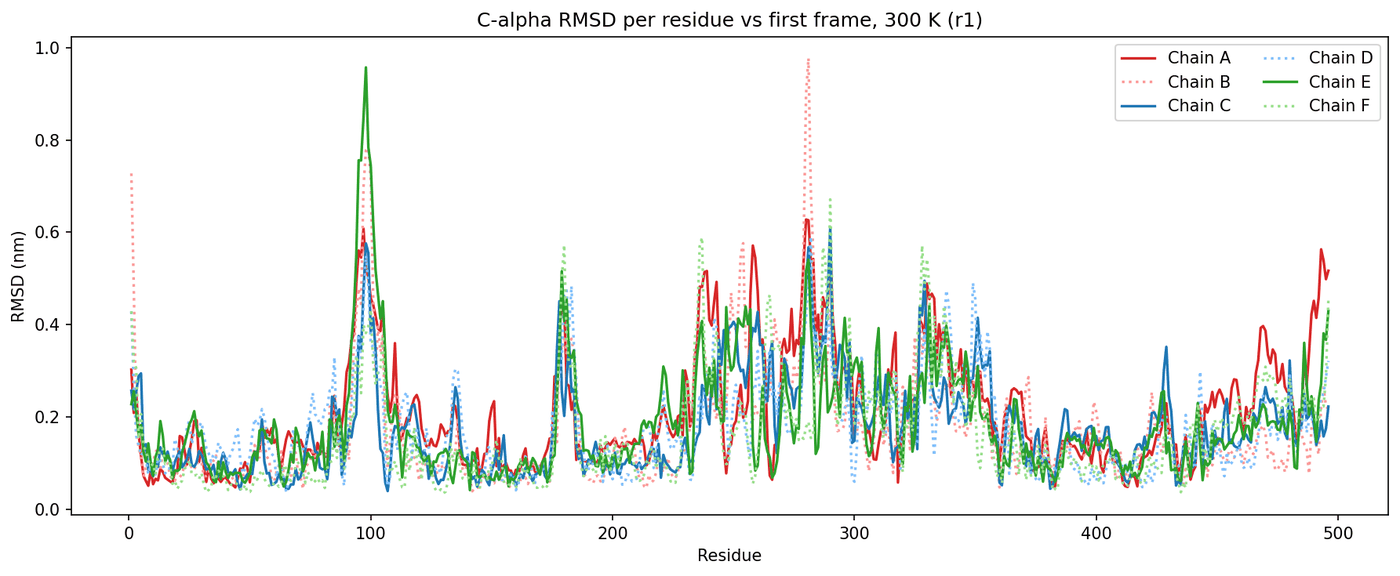

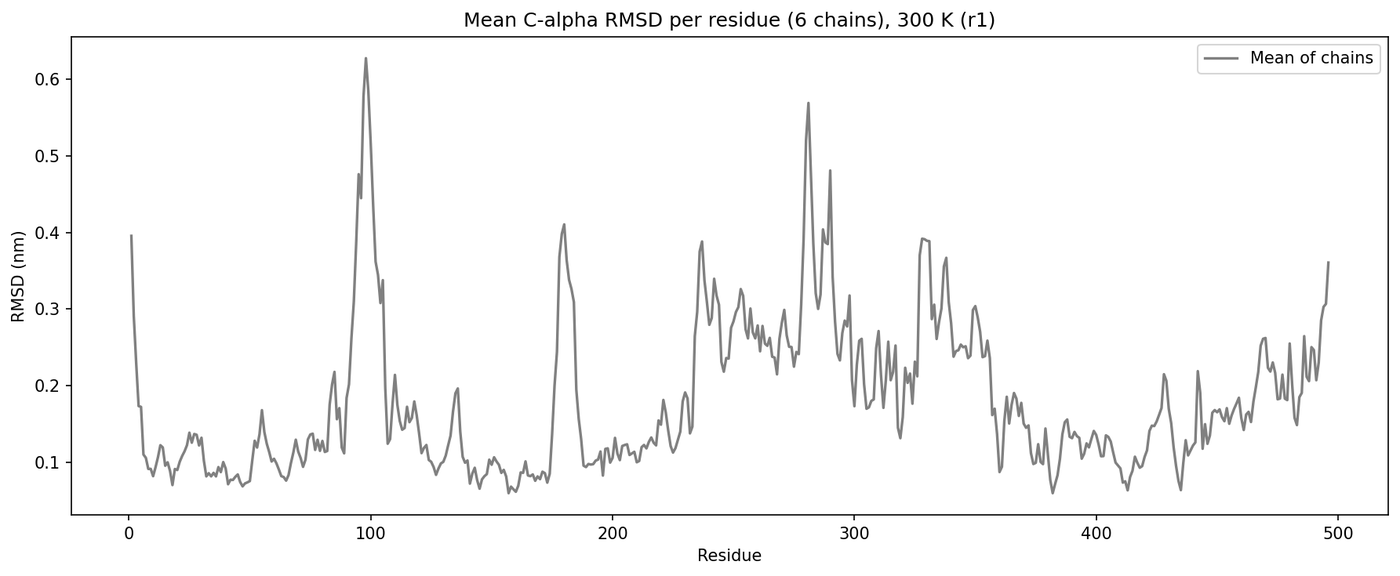

mean H-bonds/frame: 2583.7


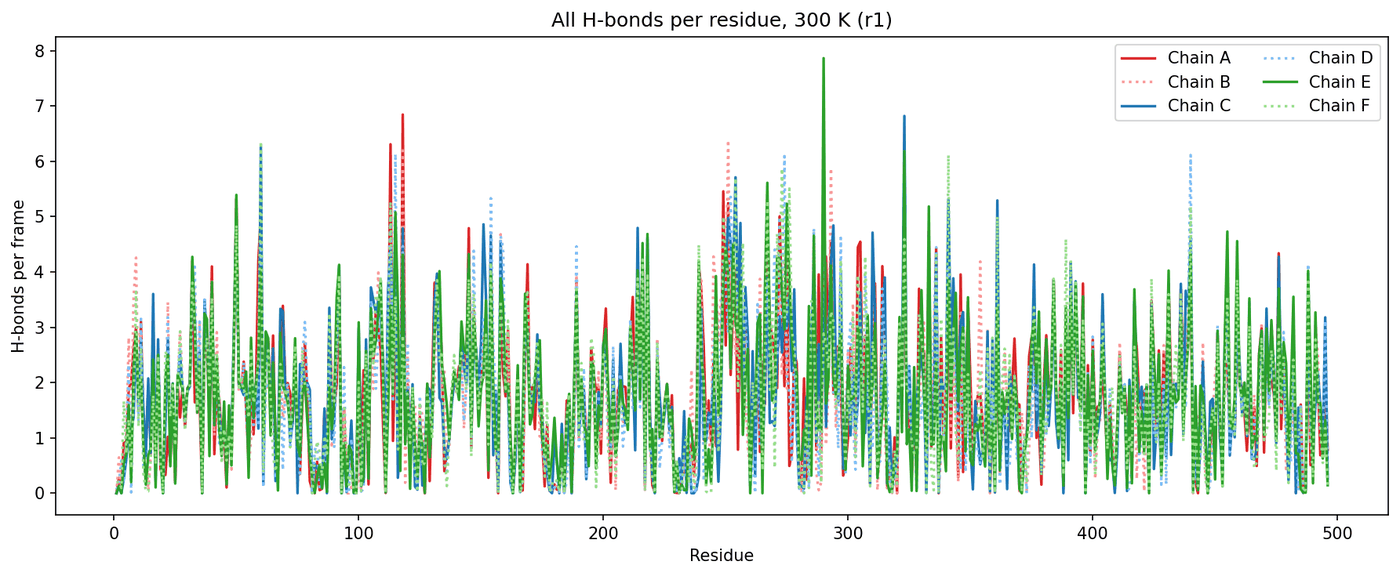

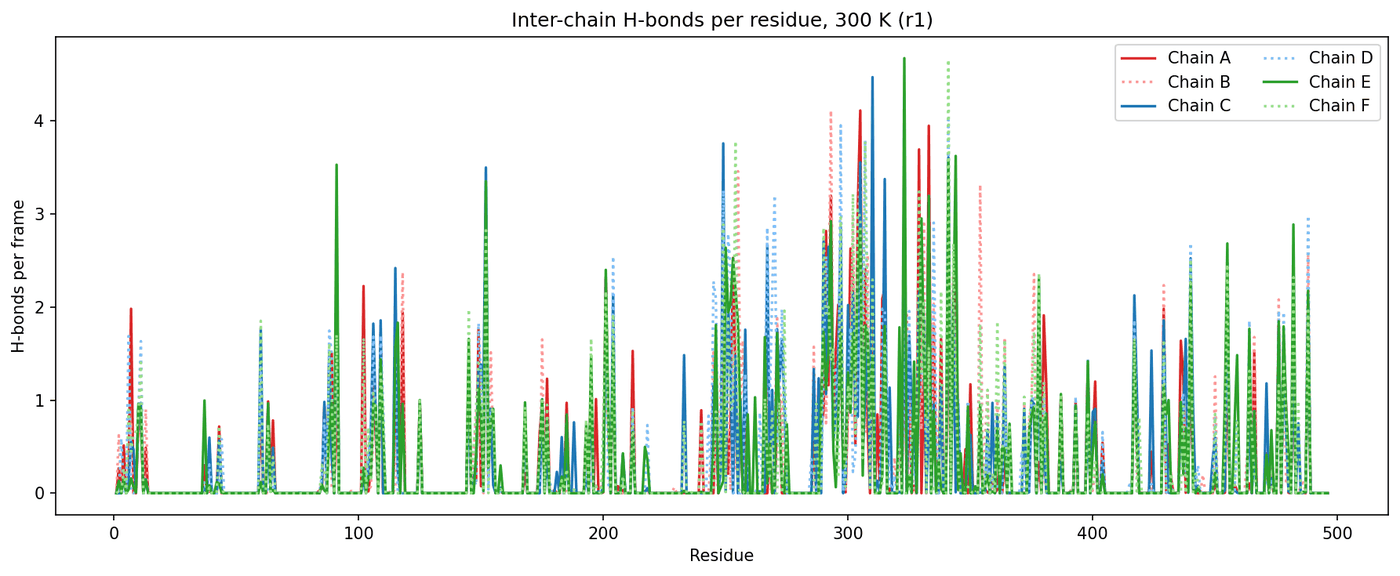

In [ ]:
import numpy as np, MDAnalysis as mda
from scipy.spatial import cKDTree
from MDAnalysis.analysis.align import rotation_matrix
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
NA = u.atoms.n_atoms // 6
cs = {c: slice(i*NA, (i+1)*NA) for i, c in enumerate(CH)}

# per-residue C-alpha RMSD vs first frame (each chain fitted on its own backbone)
resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); n = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); n += 1
    resR[name] = np.sqrt(d2/n)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,NR+1), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", "C-alpha RMSD per residue vs first frame, 300 K (r1)", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), resR[c], s) for c, s in sty.items()])
m = np.mean(list(resR.values()), axis=0)
draw("rmsd_per_residue_mean", "Mean C-alpha RMSD per residue (6 chains), 300 K (r1)", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), m, dict(color="grey", label="Mean of chains"))])

# per-residue H-bonds (same geometry criteria as the other protein run: H...A < 0.25 nm, D-A < 0.35 nm, angle < 30 deg)
nmA = np.array([n.strip() for n in u.atoms.names]); rn = u.atoms.resnames
chain = np.arange(len(nmA)) // NA
ridx = u.atoms.resindices - chain*NR            # residue position within its chain, 0..495
assert ridx.min() == 0 and ridx.max() == NR-1
isH = np.array([n.startswith("H") for n in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
k = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[k], don[k]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((6,NR)); inter = np.zeros((6,NR)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; n = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D or (chain[A]==chain[D] and ridx[A]==ridx[D]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D], Pf[A]-Pf[D]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            n += 1
            for Xa in (D, A):
                tot[chain[Xa], ridx[Xa]] += 1
                if chain[D] != chain[A]: inter[chain[Xa], ridx[Xa]] += 1
    nb.append(n)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(CH): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,NR+1), arr[i]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, 300 K (r1)", "Residue", "H-bonds per frame",
         [(np.arange(1,NR+1), arr[i]/nf, s) for i, s in enumerate(sty.values())])

In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_Protein.dat" > "$OUT/logs/dssp_Protein.log" 2>&1
cp "$OUT/xvgs/dssp_Protein.dat" "$OUT/xvgs/dssp_chA.dat"
head -c 80 "$OUT/xvgs/dssp_Protein.dat"; echo; tail -3 "$OUT/logs/dssp_Protein.log"

~~~~~GGGTT~~~~~~~BPPSEEEEETTEEEEE~~TTSHHHHHHTEEEEEEEE~TTEEEEEEEESS~EEEEEEE~~EEEE

GROMACS reminds you: "Science progresses best when observations force us to alter our preconceptions." (Vera Rubin)



shape: (201, 2981) | chain breaks at columns: [ 496  993 1490 1987 2484]
helix chA mean %: 10.6
helix chB mean %: 11.8
helix chC mean %: 11.4
helix chD mean %: 12.8
helix chE mean %: 11.7
helix chF mean %: 10.6


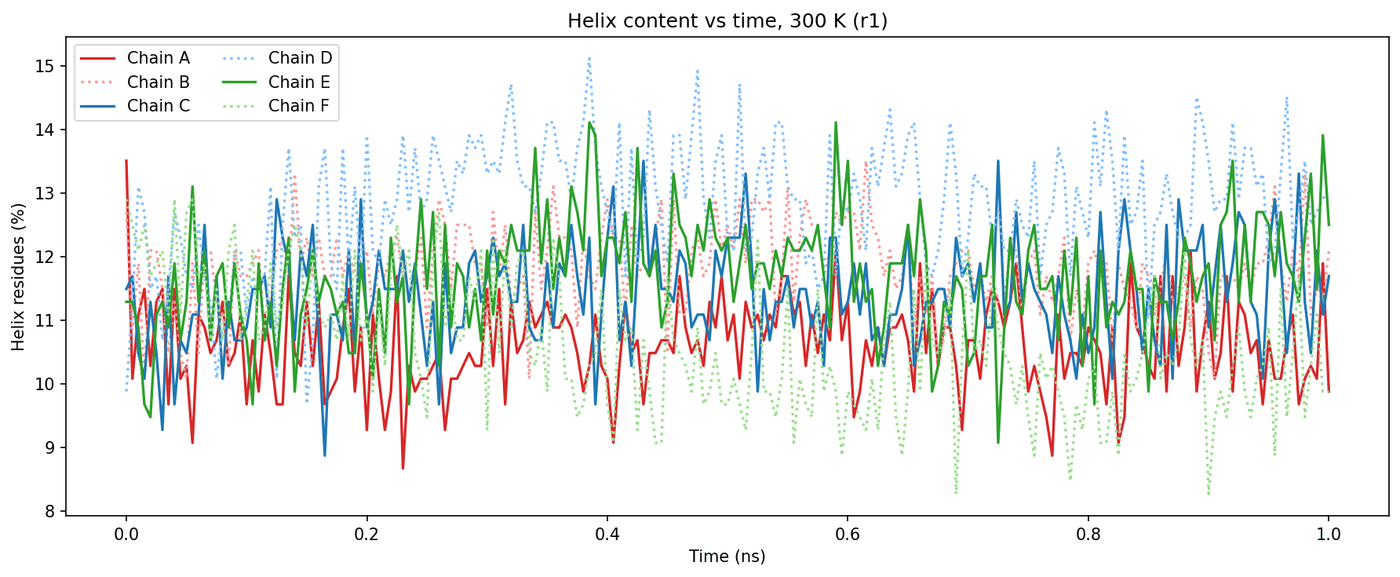

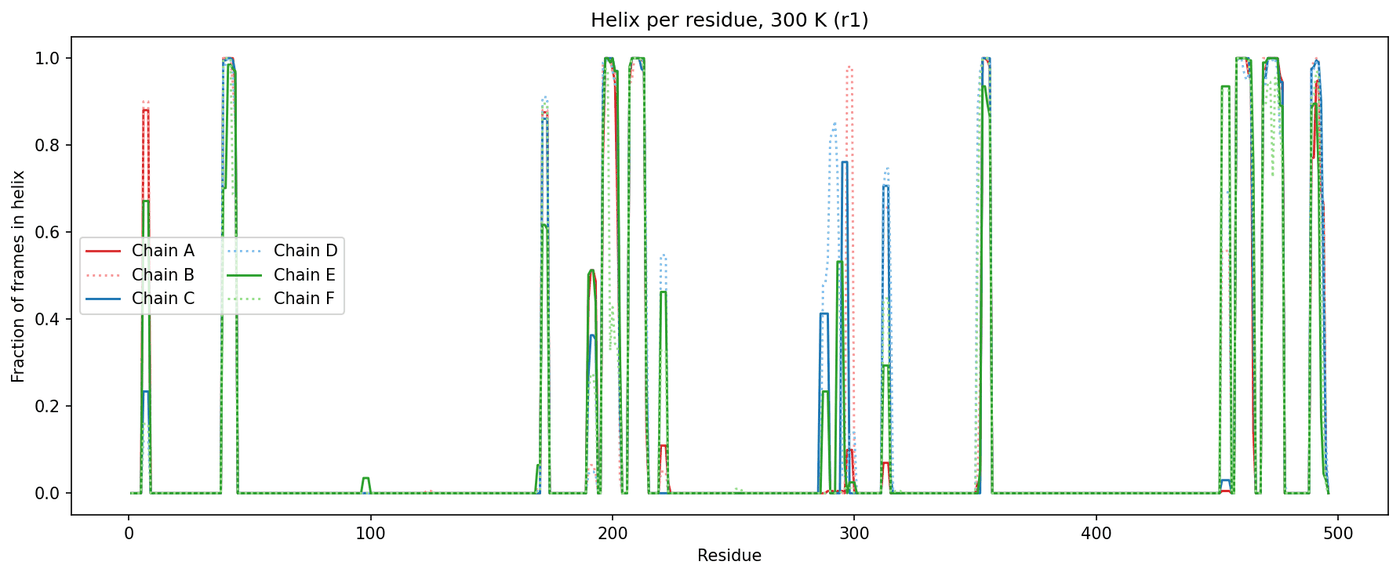

strand chA mean %: 28.3
strand chB mean %: 27.7
strand chC mean %: 26.5
strand chD mean %: 25.4
strand chE mean %: 27.3
strand chF mean %: 27.5


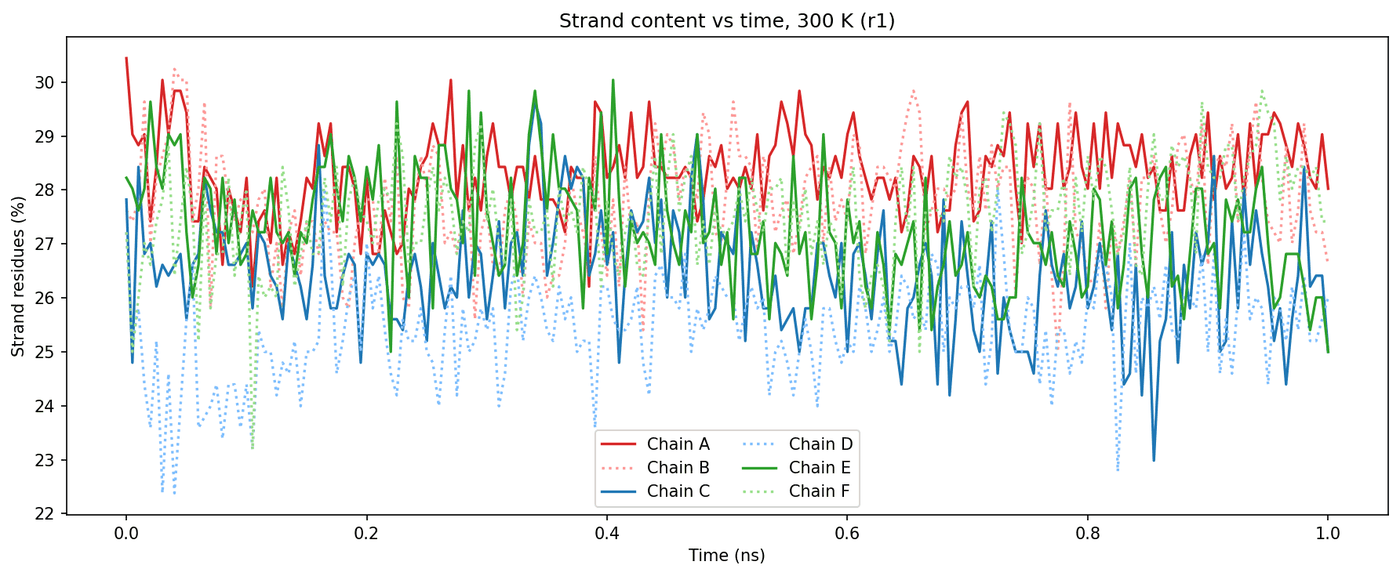

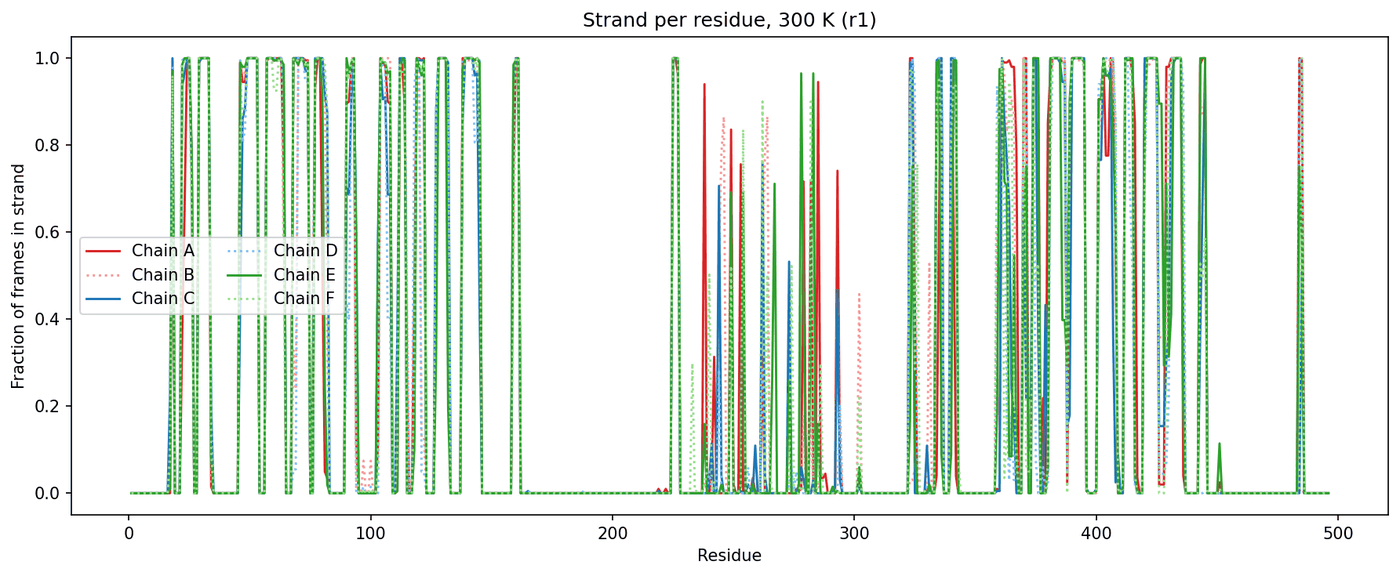

In [ ]:
import numpy as np, matplotlib.pyplot as plt
a = np.array([list(l.rstrip("\n")) for l in open(f"{X}/dssp_Protein.dat") if l.strip()])
brk = np.where((a == "=").all(0))[0]
print("shape:", a.shape, "| chain breaks at columns:", brk)
a = a[:, ~(a == "=").all(0)]
assert a.shape[1] == 6*NR, a.shape
D = {c: a[:, i*NR:(i+1)*NR] for i, c in enumerate(CH)}
t = np.arange(len(a))*0.005          # 201 frames x 5 ps -> ns
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(D[c], list(ss)).mean(1), lw=1.6, **s)
        print(name, c, "mean %:", round(100*np.isin(D[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, 300 K (r1)")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()

    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(D[c], list(ss)).mean(0); ax.plot(np.arange(1,NR+1), f, lw=1.4, **s)
        np.savetxt(f"{X}/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,NR+1), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, 300 K (r1)")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()

In [ ]:
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items():
    ax.plot(t, 100*(1-np.isin(D[c], list("HGIEB")).mean(1)), lw=1.6, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title="Coil/turn content vs time, 300 K (r1)")
ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()

cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(6, 1, figsize=(12,13), dpi=150, sharex=True)
for ax, (c, s) in zip(axs, sty.items()):
    ax.imshow(code(D[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,NR,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
axs[-1].set_xlabel("Residue"); fig.suptitle("DSSP map: red = helix, blue = strand, grey = coil/turn, 300 K (r1)")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

     chain  RMSD_nm  Rg_nm  SASA_nm2  intra_Hbonds  helix_pct  strand_pct
0      chA    0.255  2.698   146.671       375.545     10.654      28.483
1      chB    0.225  2.657   145.251       366.337     11.805      27.904
2      chC    0.211  2.680   140.844       365.812     11.482      26.100
3      chD    0.210  2.687   151.762       342.752     12.923      25.595
4      chE    0.241  2.675   146.025       367.505     11.712      26.830
5      chF    0.202  2.669   144.177       361.287     10.145      27.789
6  hexamer    0.267  3.919   874.763      2707.455        NaN         NaN


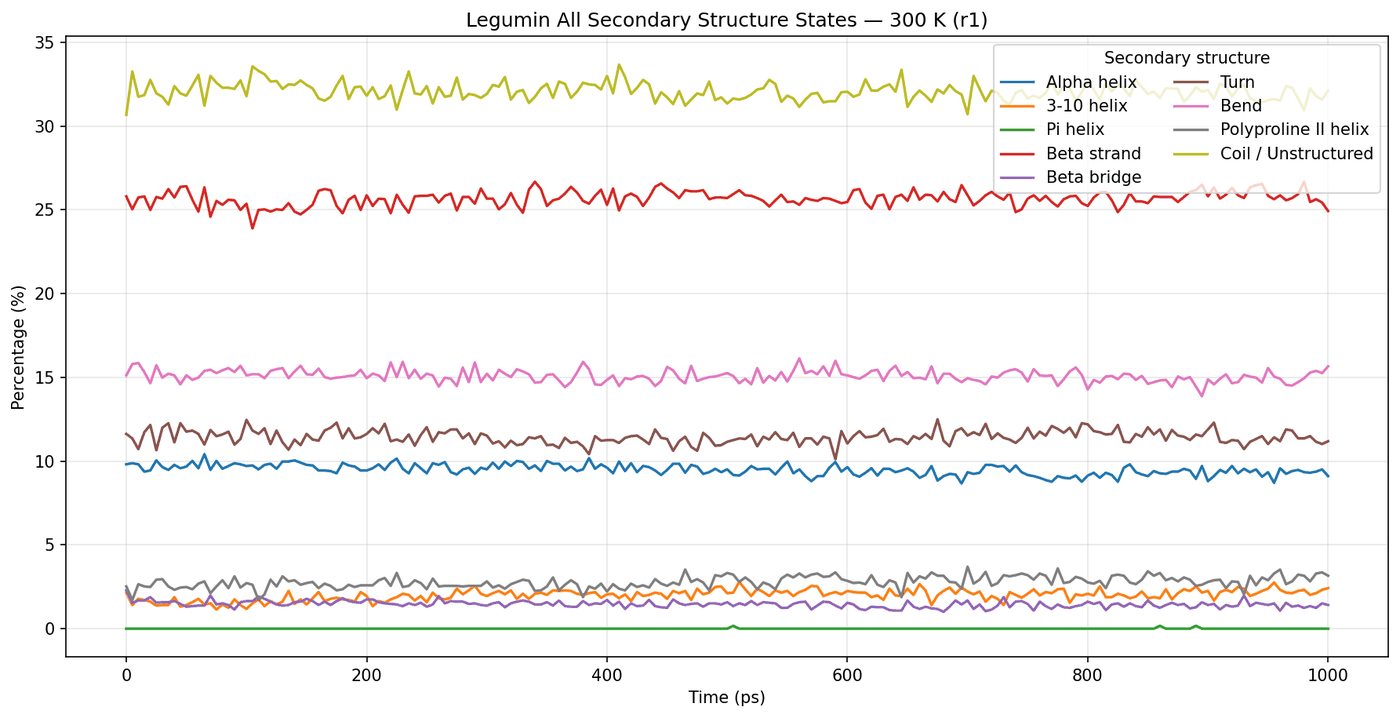

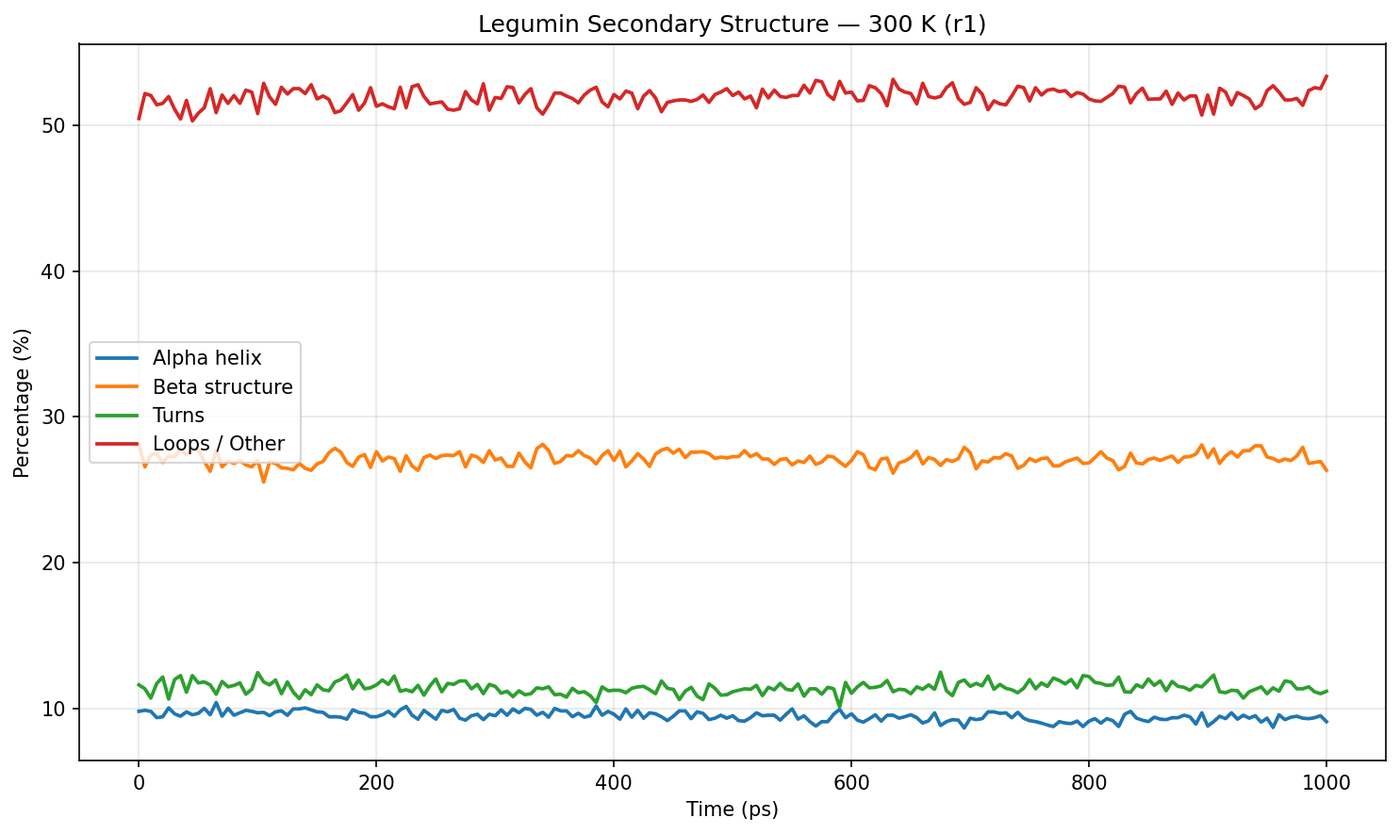

In [ ]:
import pandas as pd
def last(f, col=1): a = np.loadtxt(f, comments=('#','@')); return a[len(a)//2:, col].mean()
h = len(t)//2; rows = []
for c in CH:
    rows.append(dict(chain=c, RMSD_nm=last(f"{X}/rmsd_{c}.xvg"), Rg_nm=last(f"{X}/rg_{c}.xvg"),
      SASA_nm2=last(f"{X}/sasa_{c}.xvg", 2), intra_Hbonds=last(f"{X}/hbnum_{c}.xvg"),
      helix_pct=100*np.isin(D[c][h:], list("HGI")).mean(), strand_pct=100*np.isin(D[c][h:], list("EB")).mean()))
rows.append(dict(chain="hexamer", RMSD_nm=last(f"{X}/rmsd_Protein.xvg"), Rg_nm=last(f"{X}/rg_Protein.xvg"),
                 SASA_nm2=last(f"{X}/sasa_Protein.xvg"), intra_Hbonds=last(f"{X}/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{X}/summary_last0.5ns.csv", index=False); print(df)

STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
P = {n: 100*(a == c).mean(1) for n, c in STATES}; P["Coil / Unstructured"] = 100 - sum(P.values())
tp = np.arange(len(a))*5.0
fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (n, y) in enumerate(P.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.6, label=n)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title="Legumin All Secondary Structure States — 300 K (r1)")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_300K_r1.png"); plt.show()

G = {"Alpha helix": P["Alpha helix"], "Beta structure": P["Beta strand"]+P["Beta bridge"], "Turns": P["Turn"]}
G["Loops / Other"] = 100 - sum(G.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (n, y) in enumerate(G.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.8, label=n)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title="Legumin Secondary Structure — 300 K (r1)")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_300K_r1.png"); plt.show()

In [ ]:
import os, subprocess, sys
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
os.environ.update(P="/content/pm", S="md_300_r2", OUT="/content/pm/analysism/legumin_300_r2")
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "MDAnalysis", "scipy"])
import MDAnalysis; print("MDAnalysis", MDAnalysis.__version__)
os.system('gmx --version | head -1; ls $P/$S.*')

MDAnalysis 2.10.0


0

In [ ]:
%%bash
ls -lh $P/$S.*
echo "S=$S  OUT=$OUT"
gmx check -f "$P/$S.xtc" 2>&1 | grep -iE "Natoms|Last frame|Step|Time"

-rw------- 1 root root 5.0M Oct 11 11:26 /content/pm/md_300_r2.cpt
-rw------- 1 root root 552K Oct 11 10:18 /content/pm/md_300_r2.edr
-rw------- 1 root root  15M Oct 11 11:26 /content/pm/md_300_r2.gro
-rw------- 1 root root  89K Oct 11 11:27 /content/pm/md_300_r2.log
-rw------- 1 root root  403 Oct 11 10:18 /content/pm/md_300_r2.mdp
-rw------- 1 root root  16M Oct 11 10:18 /content/pm/md_300_r2.tpr
-rw------- 1 root root 171M Oct 11 11:27 /content/pm/md_300_r2.xtc
S=md_300_r2  OUT=/content/pm/analysism/legumin_300_r2
Reading frame       0 time    0.000   
Last frame       1000 time 1000.000   
Item        #frames Timestep (ps)
Step          1001    1
Time          1001    1


In [ ]:
import os, sys, json, itertools, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
RUN = "r2"                                   # <- only this changes per run
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
S = f"md_300_{RUN}"; OUT = f"/content/pm/analysism/legumin_300_{RUN}"; T = f"300 K ({RUN})"
os.environ.update(P="/content/pm", S=S, OUT=OUT)
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f"{OUT}/{d}", exist_ok=True)
subprocess.run([sys.executable,"-m","pip","install","-q","MDAnalysis","scipy"])
import MDAnalysis as mda
from MDAnalysis.lib.distances import minimize_vectors
from MDAnalysis.analysis.align import rotation_matrix
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap
def sh(cmd, tail=0):
    r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True)
    o = (r.stdout + r.stderr).strip().split("\n")
    print("\n".join(o[-tail:] if tail else o))

# ---- check files
print("== files"); sh('ls -lh $P/$S.*; gmx check -f "$P/$S.xtc" 2>&1 | grep -iE "Natoms|Last frame|Step"')

# ---- protein tpr, whole, first frame
print("== whole")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1''')

# ---- chain detection from .gro
lines = open(f"{OUT}/frames/first_w.gro").read().split("\n")
n = int(lines[1]); body = lines[2:2+n]
resnum = np.array([int(l[0:5]) for l in body]); nm = [l[10:15].strip() for l in body]
starts = [0] + [i for i in range(1, n) if resnum[i] < resnum[i-1]]; ends = starts[1:] + [n]
nres = [len(set(resnum[s:e])) for s, e in zip(starts, ends)]
print("atoms:", n, "| chains:", len(starts), "| atoms/chain:", [e-s for s,e in zip(starts,ends)], "| res/chain:", nres)
assert len(starts) == 6, "expected 6 chains"
NR = nres[0]; CH = ["chA","chB","chC","chD","chE","chF"]; G = {}; ranges = {}
for k, (s, e) in enumerate(zip(starts, ends)):
    r = range(s+1, e+1); c = CH[k]; ranges[c] = [s, e]
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
r = range(1, n+1)
G["Protein"] = list(r); G["Protein_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G["Protein_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:5d}" for i in idx[k:k+15]) + "\n")
json.dump(dict(ranges=ranges, nres=NR, natoms=n), open(f"{OUT}/frames/chains.json","w"))

# ---- keep 6 chains together
sl = [slice(*ranges[c]) for c in CH]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32); a0 = pos[sl[0]].mean(0)
        for s in sl[1:]:
            d = pos[s].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]; pos[s] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

# ---- fit
print("== fit")
sh(r'''cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|Step"''')

# ---- hexamer integrity check
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
pairs = list(itertools.combinations(range(6), 2)); worst = {p: 0.0 for p in pairs}; lonely = 0
for ts in u.trajectory:
    Pp = u.atoms.positions/10; ch = [Pp[s] for s in sl]
    m = {p: cKDTree(ch[p[0]]).query(ch[p[1]])[0].min() for p in pairs}
    for p in pairs: worst[p] = max(worst[p], m[p])
    for i in range(6):
        if min(m[p] for p in pairs if i in p) > 0.5: lonely += 1
print({"ABCDEF"[a]+"ABCDEF"[b]: round(float(v),2) for (a,b), v in worst.items()})
print("chains with no neighbour within 0.5 nm:", lonely)
assert lonely == 0, "a chain drifted away"

# ---- GROMACS analysis
print("== gmx analysis (slow)")
sh(r'''cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in Protein chA chB chC chD chE chF; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
for p in "chA chB" "chA chC" "chA chD" "chA chE" "chA chF" "chB chC" "chB chD" "chB chE" "chB chF" "chC chD" "chC chE" "chC chF" "chD chE" "chD chF" "chE chF"; do set -- $p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $1" -t "group $2" -num $X/hbinter_$1_$2.xvg -tu ns > $L/hbinter_$1_$2.log 2>&1
done
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done''')

# ---- plots
X = f"{OUT}/xvgs"
cols = ["#d62728","#ff9896","#1f77b4","#7fbfff","#2ca02c","#98df8a"]
sty = {c: dict(color=cols[i], ls="-" if i%2==0 else ":", label="Chain "+c[-1]) for i, c in enumerate(CH)}
xvg = lambda f: np.loadtxt(f, comments=('#','@'))
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.6, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(ncol=2); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
chains = lambda pre, col=1, sc=1: [(xvg(f"{X}/{pre}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{pre}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(pre, col=1, sc=1):
    a = xvg(f"{X}/{pre}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole hexamer"))]
for pre, yl, ttl, sc in (("rmsd","RMSD (nm)","Backbone RMSD",1), ("rg","Rg (nm)","Radius of gyration",1000),
                         ("sasa","SASA (nm²)","SASA",1), ("hbnum","H-bonds","Intra-chain H-bonds",1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, {T}", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole hexamer, {T}", "Time (ns)", yl, whole(pre, 1, sc))
draw("rmsf_per_chain", f"C-alpha RMSF per residue, {T}", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == 6*NR, len(d)
draw("sasa_per_residue", f"SASA per residue, {T}", "Residue", "SASA (nm²)",
     [(np.arange(1,NR+1), d[i*NR:(i+1)*NR,1], s) for i, s in enumerate(sty.values())])
fig, ax = plt.subplots(figsize=(12,6), dpi=150)
for k, (a_, b_) in enumerate(itertools.combinations(CH, 2)):
    h = xvg(f"{X}/hbinter_{a_}_{b_}.xvg"); ax.plot(h[:,0], h[:,1], lw=1.2, color=plt.cm.tab20(k), label=f"{a_[-1]}–{b_[-1]}")
ax.set(xlabel="Time (ns)", ylabel="H-bonds", title=f"Inter-chain H-bonds, {T}"); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/hbonds_inter_chain.png"); plt.show()

# ---- per-residue RMSD and H-bonds
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
NA = u.atoms.n_atoms // 6; cs = {c: slice(i*NA, (i+1)*NA) for i, c in enumerate(CH)}; resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); k = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); k += 1
    resR[name] = np.sqrt(d2/k)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,NR+1), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", f"C-alpha RMSD per residue vs first frame, {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), resR[c], s) for c, s in sty.items()])
draw("rmsd_per_residue_mean", f"Mean C-alpha RMSD per residue (6 chains), {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), np.mean(list(resR.values()), axis=0), dict(color="grey", label="Mean of chains"))])

nmA = np.array([x.strip() for x in u.atoms.names]); rn = u.atoms.resnames
chain = np.arange(len(nmA)) // NA; ridx = u.atoms.resindices - chain*NR
assert ridx.min() == 0 and ridx.max() == NR-1
isH = np.array([x.startswith("H") for x in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
kk = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[kk], don[kk]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((6,NR)); inter = np.zeros((6,NR)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; k = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D_ = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D_ or (chain[A]==chain[D_] and ridx[A]==ridx[D_]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D_], Pf[A]-Pf[D_]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            k += 1
            for Xa in (D_, A):
                tot[chain[Xa], ridx[Xa]] += 1
                if chain[D_] != chain[A]: inter[chain[Xa], ridx[Xa]] += 1
    nb.append(k)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(CH): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,NR+1), arr[i]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, {T}", "Residue", "H-bonds per frame", [(np.arange(1,NR+1), arr[i]/nf, s) for i, s in enumerate(sty.values())])

# ---- DSSP
print("== dssp")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_Protein.dat" > "$OUT/logs/dssp_Protein.log" 2>&1
cp "$OUT/xvgs/dssp_Protein.dat" "$OUT/xvgs/dssp_chA.dat"
head -c 80 "$OUT/xvgs/dssp_Protein.dat"; echo''')
a = np.array([list(l.rstrip("\n")) for l in open(f"{X}/dssp_Protein.dat") if l.strip()])
a = a[:, ~(a == "=").all(0)]; print("dssp shape:", a.shape); assert a.shape[1] == 6*NR, a.shape
Dd = {c: a[:, i*NR:(i+1)*NR] for i, c in enumerate(CH)}; t = np.arange(len(a))*0.005
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(Dd[c], list(ss)).mean(1), lw=1.6, **s)
        print(name, c, "mean %:", round(100*np.isin(Dd[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(Dd[c], list(ss)).mean(0); ax.plot(np.arange(1,NR+1), f, lw=1.4, **s)
        np.savetxt(f"{X}/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,NR+1), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items(): ax.plot(t, 100*(1-np.isin(Dd[c], list("HGIEB")).mean(1)), lw=1.6, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title=f"Coil/turn content vs time, {T}")
ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()
cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(6, 1, figsize=(12,13), dpi=150, sharex=True)
for ax, (c, s) in zip(axs, sty.items()):
    ax.imshow(code(Dd[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,NR,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
axs[-1].set_xlabel("Residue"); fig.suptitle(f"DSSP map: red = helix, blue = strand, grey = coil/turn, {T}")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

# ---- summary + all-states plots
def last(f, col=1): b = xvg(f); return b[len(b)//2:, col].mean()
h = len(t)//2; rows = []
for c in CH:
    rows.append(dict(chain=c, RMSD_nm=last(f"{X}/rmsd_{c}.xvg"), Rg_nm=last(f"{X}/rg_{c}.xvg"),
      SASA_nm2=last(f"{X}/sasa_{c}.xvg", 2), intra_Hbonds=last(f"{X}/hbnum_{c}.xvg"),
      helix_pct=100*np.isin(Dd[c][h:], list("HGI")).mean(), strand_pct=100*np.isin(Dd[c][h:], list("EB")).mean()))
rows.append(dict(chain="hexamer", RMSD_nm=last(f"{X}/rmsd_Protein.xvg"), Rg_nm=last(f"{X}/rg_Protein.xvg"),
                 SASA_nm2=last(f"{X}/sasa_Protein.xvg"), intra_Hbonds=last(f"{X}/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{X}/summary_last0.5ns.csv", index=False); print(df)
STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
Pc = {k_: 100*(a == c_).mean(1) for k_, c_ in STATES}; Pc["Coil / Unstructured"] = 100 - sum(Pc.values())
tp = np.arange(len(a))*5.0
fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (k_, y) in enumerate(Pc.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.6, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Legumin All Secondary Structure States — {T}")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_300K_{RUN}.png"); plt.show()
Gp = {"Alpha helix": Pc["Alpha helix"], "Beta structure": Pc["Beta strand"]+Pc["Beta bridge"], "Turns": Pc["Turn"]}
Gp["Loops / Other"] = 100 - sum(Gp.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (k_, y) in enumerate(Gp.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.8, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Legumin Secondary Structure — {T}")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_300K_{RUN}.png"); plt.show()
print("DONE ->", OUT)

In [ ]:
import os
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
os.system('''cd /content/pm
echo "== files"; ls -lh md_373_r1* npt_373_r1* 2>/dev/null
echo; echo "== md_373_r1.xtc"; gmx check -f md_373_r1.xtc 2>&1 | grep -iE "Natoms|Last frame|Step|Time"
echo; echo "== verified_copy.xtc"; gmx check -f md_373_r1_verified_copy.xtc 2>&1 | grep -iE "Natoms|Last frame|Step|Time"
echo; echo "== same content?"; cmp md_373_r1.xtc md_373_r1_verified_copy.xtc && echo IDENTICAL
echo; echo "== tpr / gro"; head -2 md_373_r1.gro | tail -1
grep -iE "^ *(tinit|dt|nsteps|ref_t|gen_temp|nstxout-compressed)" md_373_r1.mdp
echo; echo "== log tail"; tail -5 md_373_r1.log''')

0

In [ ]:
import os, subprocess
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
cmd = '''cd /content/pm
echo "== files"; ls -lh md_373_r1* npt_373_r1* 2>/dev/null
echo; echo "== md_373_r1.xtc"; gmx check -f md_373_r1.xtc 2>&1 | grep -iE "Natoms|Last frame|Step|Time"
echo; echo "== verified_copy.xtc"; gmx check -f md_373_r1_verified_copy.xtc 2>&1 | grep -iE "Natoms|Last frame|Step|Time"
echo; echo "== same content?"; cmp md_373_r1.xtc md_373_r1_verified_copy.xtc && echo IDENTICAL
echo; echo "== gro atoms"; head -2 md_373_r1.gro | tail -1
echo; echo "== mdp"; grep -iE "^ *(tinit|dt|nsteps|ref_t|gen_temp|nstxout-compressed)" md_373_r1.mdp
echo; echo "== log tail"; tail -5 md_373_r1.log'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True)
print(r.stdout); print(r.stderr[-500:])

== files
-rw------- 1 root root 5.0M Oct 13 16:58 md_373_r1.cpt
-rw------- 1 root root 552K Oct 13 15:49 md_373_r1.edr
-rw------- 1 root root  15M Oct 13 16:58 md_373_r1.gro
-rw------- 1 root root  90K Oct 13 16:58 md_373_r1.log
-rw------- 1 root root  403 Oct 13 15:47 md_373_r1.mdp
-rw------- 1 root root 5.0M Oct 13 16:58 md_373_r1_prev.cpt
-rw------- 1 root root  16M Oct 13 15:48 md_373_r1.tpr
-rw------- 1 root root 172M Oct 13 16:58 md_373_r1_verified_copy.xtc
-rw------- 1 root root 172M Oct 13 15:49 md_373_r1.xtc
-rw------- 1 root root 5.0M Oct 13 15:36 npt_373_r1.cpt
-rw------- 1 root root  481 Oct 12 15:35 npt_373_r1.mdp
-rw------- 1 root root  82K Oct 13 15:24 npt_373_r1.part0002.edr
-rw------- 1 root root  15M Oct 13 15:35 npt_373_r1.part0002.gro
-rw------- 1 root root 108K Oct 13 15:24 npt_373_r1.part0002.log
-rw------- 1 root root  11M Oct 13 15:36 npt_373_r1.part0002.xtc
-rw------- 1 root root 5.0M Oct 13 15:36 npt_373_r1_prev.cpt
-rw------- 1 root root  19M Oct 12 15:35 npt

In [ ]:
import os, sys, json, itertools, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
TEMP, RUN = "373", "r1"                      # <- only this line changes per run
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
S = f"md_{TEMP}_{RUN}"; OUT = f"/content/pm/analysism/legumin_{TEMP}_{RUN}"; T = f"{TEMP} K ({RUN})"
os.environ.update(P="/content/pm", S=S, OUT=OUT)
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f"{OUT}/{d}", exist_ok=True)
subprocess.run([sys.executable,"-m","pip","install","-q","MDAnalysis","scipy"])
import MDAnalysis as mda
from MDAnalysis.lib.distances import minimize_vectors
from MDAnalysis.analysis.align import rotation_matrix
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap
def sh(cmd, tail=0):
    r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True)
    o = (r.stdout + r.stderr).strip().split("\n")
    print("\n".join(o[-tail:] if tail else o))

# ---- check files + temperature
print("== files"); sh('ls -lh $P/$S.*; grep -iE "ref[-_]t|tcoupl|gen[-_]temp" $P/$S.mdp; gmx check -f "$P/$S.xtc" 2>&1 | grep -E "Last frame|^Step"')

# ---- protein tpr, whole, first frame
print("== whole")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1''')

# ---- chain detection from .gro
lines = open(f"{OUT}/frames/first_w.gro").read().split("\n")
n = int(lines[1]); body = lines[2:2+n]
resnum = np.array([int(l[0:5]) for l in body]); nm = [l[10:15].strip() for l in body]
starts = [0] + [i for i in range(1, n) if resnum[i] < resnum[i-1]]; ends = starts[1:] + [n]
nres = [len(set(resnum[s:e])) for s, e in zip(starts, ends)]
print("atoms:", n, "| chains:", len(starts), "| atoms/chain:", [e-s for s,e in zip(starts,ends)], "| res/chain:", nres)
assert len(starts) == 6, "expected 6 chains"
NR = nres[0]; CH = ["chA","chB","chC","chD","chE","chF"]; G = {}; ranges = {}
for k, (s, e) in enumerate(zip(starts, ends)):
    r = range(s+1, e+1); c = CH[k]; ranges[c] = [s, e]
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
r = range(1, n+1)
G["Protein"] = list(r); G["Protein_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G["Protein_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:5d}" for i in idx[k:k+15]) + "\n")
json.dump(dict(ranges=ranges, nres=NR, natoms=n), open(f"{OUT}/frames/chains.json","w"))

# ---- keep 6 chains together
sl = [slice(*ranges[c]) for c in CH]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32); a0 = pos[sl[0]].mean(0)
        for s in sl[1:]:
            d = pos[s].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]; pos[s] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

# ---- fit
print("== fit")
sh(r'''cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|^Step"''')

# ---- hexamer integrity check
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
pairs = list(itertools.combinations(range(6), 2)); worst = {p: 0.0 for p in pairs}; lonely = 0
for ts in u.trajectory:
    Pp = u.atoms.positions/10; ch = [Pp[s] for s in sl]
    m = {p: cKDTree(ch[p[0]]).query(ch[p[1]])[0].min() for p in pairs}
    for p in pairs: worst[p] = max(worst[p], m[p])
    for i in range(6):
        if min(m[p] for p in pairs if i in p) > 0.5: lonely += 1
print({"ABCDEF"[a]+"ABCDEF"[b]: round(float(v),2) for (a,b), v in worst.items()})
print("chains with no neighbour within 0.5 nm:", lonely)
assert lonely == 0, "a chain drifted away"

# ---- GROMACS analysis
print("== gmx analysis (slow)")
sh(r'''cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in Protein chA chB chC chD chE chF; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
for p in "chA chB" "chA chC" "chA chD" "chA chE" "chA chF" "chB chC" "chB chD" "chB chE" "chB chF" "chC chD" "chC chE" "chC chF" "chD chE" "chD chF" "chE chF"; do set -- $p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $1" -t "group $2" -num $X/hbinter_$1_$2.xvg -tu ns > $L/hbinter_$1_$2.log 2>&1
done
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done''')

# ---- plots
X = f"{OUT}/xvgs"
cols = ["#d62728","#ff9896","#1f77b4","#7fbfff","#2ca02c","#98df8a"]
sty = {c: dict(color=cols[i], ls="-" if i%2==0 else ":", label="Chain "+c[-1]) for i, c in enumerate(CH)}
xvg = lambda f: np.loadtxt(f, comments=('#','@'))
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.6, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(ncol=2); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
chains = lambda pre, col=1, sc=1: [(xvg(f"{X}/{pre}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{pre}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(pre, col=1, sc=1):
    a = xvg(f"{X}/{pre}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole hexamer"))]
for pre, yl, ttl, sc in (("rmsd","RMSD (nm)","Backbone RMSD",1), ("rg","Rg (nm)","Radius of gyration",1000),
                         ("sasa","SASA (nm²)","SASA",1), ("hbnum","H-bonds","Intra-chain H-bonds",1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, {T}", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole hexamer, {T}", "Time (ns)", yl, whole(pre, 1, sc))
draw("rmsf_per_chain", f"C-alpha RMSF per residue, {T}", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == 6*NR, len(d)
draw("sasa_per_residue", f"SASA per residue, {T}", "Residue", "SASA (nm²)",
     [(np.arange(1,NR+1), d[i*NR:(i+1)*NR,1], s) for i, s in enumerate(sty.values())])
fig, ax = plt.subplots(figsize=(12,6), dpi=150)
for k, (a_, b_) in enumerate(itertools.combinations(CH, 2)):
    h = xvg(f"{X}/hbinter_{a_}_{b_}.xvg"); ax.plot(h[:,0], h[:,1], lw=1.2, color=plt.cm.tab20(k), label=f"{a_[-1]}–{b_[-1]}")
ax.set(xlabel="Time (ns)", ylabel="H-bonds", title=f"Inter-chain H-bonds, {T}"); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/hbonds_inter_chain.png"); plt.show()

# ---- per-residue RMSD and H-bonds
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
NA = u.atoms.n_atoms // 6; cs = {c: slice(i*NA, (i+1)*NA) for i, c in enumerate(CH)}; resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); k = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); k += 1
    resR[name] = np.sqrt(d2/k)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,NR+1), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", f"C-alpha RMSD per residue vs first frame, {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), resR[c], s) for c, s in sty.items()])
draw("rmsd_per_residue_mean", f"Mean C-alpha RMSD per residue (6 chains), {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), np.mean(list(resR.values()), axis=0), dict(color="grey", label="Mean of chains"))])

nmA = np.array([x.strip() for x in u.atoms.names]); rn = u.atoms.resnames
chain = np.arange(len(nmA)) // NA; ridx = u.atoms.resindices - chain*NR
assert ridx.min() == 0 and ridx.max() == NR-1
isH = np.array([x.startswith("H") for x in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
kk = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[kk], don[kk]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((6,NR)); inter = np.zeros((6,NR)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; k = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D_ = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D_ or (chain[A]==chain[D_] and ridx[A]==ridx[D_]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D_], Pf[A]-Pf[D_]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            k += 1
            for Xa in (D_, A):
                tot[chain[Xa], ridx[Xa]] += 1
                if chain[D_] != chain[A]: inter[chain[Xa], ridx[Xa]] += 1
    nb.append(k)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(CH): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,NR+1), arr[i]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, {T}", "Residue", "H-bonds per frame", [(np.arange(1,NR+1), arr[i]/nf, s) for i, s in enumerate(sty.values())])

# ---- DSSP
print("== dssp")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_Protein.dat" > "$OUT/logs/dssp_Protein.log" 2>&1
cp "$OUT/xvgs/dssp_Protein.dat" "$OUT/xvgs/dssp_chA.dat"
head -c 80 "$OUT/xvgs/dssp_Protein.dat"; echo''')
a = np.array([list(l.rstrip("\n")) for l in open(f"{X}/dssp_Protein.dat") if l.strip()])
a = a[:, ~(a == "=").all(0)]; print("dssp shape:", a.shape); assert a.shape[1] == 6*NR, a.shape
Dd = {c: a[:, i*NR:(i+1)*NR] for i, c in enumerate(CH)}; t = np.arange(len(a))*0.005
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(Dd[c], list(ss)).mean(1), lw=1.6, **s)
        print(name, c, "mean %:", round(100*np.isin(Dd[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(Dd[c], list(ss)).mean(0); ax.plot(np.arange(1,NR+1), f, lw=1.4, **s)
        np.savetxt(f"{X}/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,NR+1), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items(): ax.plot(t, 100*(1-np.isin(Dd[c], list("HGIEB")).mean(1)), lw=1.6, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title=f"Coil/turn content vs time, {T}")
ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()
cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(6, 1, figsize=(12,13), dpi=150, sharex=True)
for ax, (c, s) in zip(axs, sty.items()):
    ax.imshow(code(Dd[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,NR,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
axs[-1].set_xlabel("Residue"); fig.suptitle(f"DSSP map: red = helix, blue = strand, grey = coil/turn, {T}")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

# ---- summary + all-states plots
def last(f, col=1): b = xvg(f); return b[len(b)//2:, col].mean()
h = len(t)//2; rows = []
for c in CH:
    rows.append(dict(chain=c, RMSD_nm=last(f"{X}/rmsd_{c}.xvg"), Rg_nm=last(f"{X}/rg_{c}.xvg"),
      SASA_nm2=last(f"{X}/sasa_{c}.xvg", 2), intra_Hbonds=last(f"{X}/hbnum_{c}.xvg"),
      helix_pct=100*np.isin(Dd[c][h:], list("HGI")).mean(), strand_pct=100*np.isin(Dd[c][h:], list("EB")).mean()))
rows.append(dict(chain="hexamer", RMSD_nm=last(f"{X}/rmsd_Protein.xvg"), Rg_nm=last(f"{X}/rg_Protein.xvg"),
                 SASA_nm2=last(f"{X}/sasa_Protein.xvg"), intra_Hbonds=last(f"{X}/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{X}/summary_last0.5ns.csv", index=False); print(df)
STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
Pc = {k_: 100*(a == c_).mean(1) for k_, c_ in STATES}; Pc["Coil / Unstructured"] = 100 - sum(Pc.values())
tp = np.arange(len(a))*5.0
fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (k_, y) in enumerate(Pc.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.6, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Legumin All Secondary Structure States — {T}")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_{TEMP}K_{RUN}.png"); plt.show()
Gp = {"Alpha helix": Pc["Alpha helix"], "Beta structure": Pc["Beta strand"]+Pc["Beta bridge"], "Turns": Pc["Turn"]}
Gp["Loops / Other"] = 100 - sum(Gp.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (k_, y) in enumerate(Gp.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.8, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Legumin Secondary Structure — {T}")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_{TEMP}K_{RUN}.png"); plt.show()
print("DONE ->", OUT)

In [ ]:
import os, subprocess
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''
echo "== where are the shear files"
find /content/drive/MyDrive -name "md_373_shear_r1*" -not -name "*.cpt*" 2>/dev/null | while read f; do ls -lh "$f"; done
D=$(dirname "$(find /content/drive/MyDrive -name md_373_shear_r1_combined.xtc 2>/dev/null | head -1)")
echo; echo "FOLDER: $D"; cd "$D"
for x in md_373_shear_r1_combined.xtc md_373_shear_r1.part0002.xtc md_373_shear_r1.xtc; do
  [ -f "$x" ] && { echo; echo "== $x"; gmx check -f "$x" 2>&1 | grep -E "Natoms|^Last frame|^Step|^Time"; }
done
echo; echo "== mdp (shear / temperature)"
grep -iE "deform|ref[-_]t|tcoupl|nsteps|^ *dt|nstxout-compressed|pbc" md_373_shear_r1.mdp
echo; echo "== atoms in tpr/gro"; head -2 md_373_shear_r1_final.gro | tail -1
echo; echo "== log tails"; tail -4 md_373_shear_r1.log; echo ---; tail -4 md_373_shear_r1.part0002.log
'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True)
print(r.stdout); print(r.stderr[-500:])

== where are the shear files
-rw------- 1 root root 410 Oct 13 17:25 /content/drive/MyDrive/Plant Protein Extrusion MD/md_373_shear_r1.mdp
-rw------- 1 root root 16M Oct 13 17:28 /content/drive/MyDrive/Plant Protein Extrusion MD/md_373_shear_r1.tpr
total 8.0K
drwx------ 2 root root 4.0K Oct 13 17:31 20261013_173150
drwx------ 2 root root 4.0K Oct 13 17:36 20261013_173650
-rw------- 1 root root 22K Oct 13 17:31 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173150/md_373_shear_r1.log
-rw------- 1 root root 4.0M Oct 13 17:31 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173150/md_373_shear_r1.xtc
-rw------- 1 root root 16K Oct 13 17:31 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173150/md_373_shear_r1.edr
-rw------- 1 root root 13M Oct 13 17:36 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261013_173650/md_373_shear_r1.xtc
-rw------- 1 root root 47

In [ ]:
import os, sys, json, itertools, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
TEMP, RUN = "373", "shear_r1"
TPR_NAME  = "md_373_shear_r1"                 # tpr
TRAJ_NAME = "md_373_shear_r1_combined"        # full trajectory
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
OUT = f"/content/pm/analysism/legumin_{TEMP}_{RUN}"; T = "373 K shear (r1)"
os.environ.update(P="/content/pm", S=TPR_NAME, TRAJ=TRAJ_NAME, OUT=OUT)
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f"{OUT}/{d}", exist_ok=True)
subprocess.run([sys.executable,"-m","pip","install","-q","MDAnalysis","scipy"])
import MDAnalysis as mda
from MDAnalysis.coordinates.XTC import XTCReader
from MDAnalysis.lib.distances import minimize_vectors
from MDAnalysis.analysis.align import rotation_matrix
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap
def sh(cmd, tail=0):
    r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True)
    o = (r.stdout + r.stderr).strip().split("\n")
    print("\n".join(o[-tail:] if tail else o))

# ---- check files, mdp, and trajectory continuity
print("== files"); sh('ls -lh $P/$S.tpr $P/$TRAJ.xtc; grep -iE "ref[-_]t|deform" $P/$S.mdp')
rd = XTCReader(f"{OUT.rsplit('/analysism',1)[0]}/{TRAJ_NAME}.xtc")
times = np.array([ts.time for ts in rd]); dims = np.array([ts.dimensions.copy() for ts in rd])
print("frames:", len(times), "| time", times[0], "->", times[-1], "| natoms:", rd.n_atoms)
assert times[0] == 0 and abs(times[-1]-1000) < 1e-3 and len(times) == 1001 and np.all(np.diff(times) == 1), "trajectory not continuous 0-1000 ps"
print("box a,b,c start:", dims[0,:3].round(2), "end:", dims[-1,:3].round(2))
print("angles start:", dims[0,3:].round(2), "end:", dims[-1,3:].round(2))
gd = 3.644/dims[0,1]; print(f"shear rate {gd:.4f} /ns -> expected rigid rotation {-0.5*gd*180/np.pi:.2f} deg/ns about z")

# ---- protein tpr, whole, first frame
print("== whole")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$TRAJ.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1''')

# ---- chain detection from .gro
lines = open(f"{OUT}/frames/first_w.gro").read().split("\n")
n = int(lines[1]); body = lines[2:2+n]
resnum = np.array([int(l[0:5]) for l in body]); nm = [l[10:15].strip() for l in body]
starts = [0] + [i for i in range(1, n) if resnum[i] < resnum[i-1]]; ends = starts[1:] + [n]
nres = [len(set(resnum[s:e])) for s, e in zip(starts, ends)]
print("atoms:", n, "| chains:", len(starts), "| atoms/chain:", [e-s for s,e in zip(starts,ends)], "| res/chain:", nres)
assert len(starts) == 6, "expected 6 chains"
NR = nres[0]; CH = ["chA","chB","chC","chD","chE","chF"]; G = {}; ranges = {}
for k, (s, e) in enumerate(zip(starts, ends)):
    r = range(s+1, e+1); c = CH[k]; ranges[c] = [s, e]
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
r = range(1, n+1)
G["Protein"] = list(r); G["Protein_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G["Protein_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:5d}" for i in idx[k:k+15]) + "\n")
json.dump(dict(ranges=ranges, nres=NR, natoms=n), open(f"{OUT}/frames/chains.json","w"))

# ---- keep 6 chains together (triclinic-safe)
sl = [slice(*ranges[c]) for c in CH]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32); a0 = pos[sl[0]].mean(0)
        for s in sl[1:]:
            d = pos[s].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]; pos[s] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

# ---- fit
print("== fit")
sh(r'''cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|^Step"''')

# ---- hexamer integrity check
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
pairs = list(itertools.combinations(range(6), 2)); worst = {p: 0.0 for p in pairs}; lonely = 0
for ts in u.trajectory:
    Pp = u.atoms.positions/10; ch = [Pp[s] for s in sl]
    m = {p: cKDTree(ch[p[0]]).query(ch[p[1]])[0].min() for p in pairs}
    for p in pairs: worst[p] = max(worst[p], m[p])
    for i in range(6):
        if min(m[p] for p in pairs if i in p) > 0.5: lonely += 1
print({"ABCDEF"[a]+"ABCDEF"[b]: round(float(v),2) for (a,b), v in worst.items()})
print("chains with no neighbour within 0.5 nm:", lonely)
assert lonely == 0, "a chain drifted away"

# ---- GROMACS analysis
print("== gmx analysis (slow)")
sh(r'''cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in Protein chA chB chC chD chE chF; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
for p in "chA chB" "chA chC" "chA chD" "chA chE" "chA chF" "chB chC" "chB chD" "chB chE" "chB chF" "chC chD" "chC chE" "chC chF" "chD chE" "chD chF" "chE chF"; do set -- $p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $1" -t "group $2" -num $X/hbinter_$1_$2.xvg -tu ns > $L/hbinter_$1_$2.log 2>&1
done
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done''')

# ---- plots
X = f"{OUT}/xvgs"
cols = ["#d62728","#ff9896","#1f77b4","#7fbfff","#2ca02c","#98df8a"]
sty = {c: dict(color=cols[i], ls="-" if i%2==0 else ":", label="Chain "+c[-1]) for i, c in enumerate(CH)}
xvg = lambda f: np.loadtxt(f, comments=('#','@'))
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.6, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(ncol=2); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
chains = lambda pre, col=1, sc=1: [(xvg(f"{X}/{pre}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{pre}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(pre, col=1, sc=1):
    a = xvg(f"{X}/{pre}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole hexamer"))]
for pre, yl, ttl, sc in (("rmsd","RMSD (nm)","Backbone RMSD",1), ("rg","Rg (nm)","Radius of gyration",1000),
                         ("sasa","SASA (nm²)","SASA",1), ("hbnum","H-bonds","Intra-chain H-bonds",1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, {T}", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole hexamer, {T}", "Time (ns)", yl, whole(pre, 1, sc))
draw("rmsf_per_chain", f"C-alpha RMSF per residue, {T}", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == 6*NR, len(d)
draw("sasa_per_residue", f"SASA per residue, {T}", "Residue", "SASA (nm²)",
     [(np.arange(1,NR+1), d[i*NR:(i+1)*NR,1], s) for i, s in enumerate(sty.values())])
fig, ax = plt.subplots(figsize=(12,6), dpi=150)
for k, (a_, b_) in enumerate(itertools.combinations(CH, 2)):
    h = xvg(f"{X}/hbinter_{a_}_{b_}.xvg"); ax.plot(h[:,0], h[:,1], lw=1.2, color=plt.cm.tab20(k), label=f"{a_[-1]}–{b_[-1]}")
ax.set(xlabel="Time (ns)", ylabel="H-bonds", title=f"Inter-chain H-bonds, {T}"); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/hbonds_inter_chain.png"); plt.show()

# ---- per-residue RMSD and H-bonds
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
NA = u.atoms.n_atoms // 6; cs = {c: slice(i*NA, (i+1)*NA) for i, c in enumerate(CH)}; resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); k = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); k += 1
    resR[name] = np.sqrt(d2/k)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,NR+1), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", f"C-alpha RMSD per residue vs first frame, {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), resR[c], s) for c, s in sty.items()])
draw("rmsd_per_residue_mean", f"Mean C-alpha RMSD per residue (6 chains), {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), np.mean(list(resR.values()), axis=0), dict(color="grey", label="Mean of chains"))])

nmA = np.array([x.strip() for x in u.atoms.names]); rn = u.atoms.resnames
chain = np.arange(len(nmA)) // NA; ridx = u.atoms.resindices - chain*NR
assert ridx.min() == 0 and ridx.max() == NR-1
isH = np.array([x.startswith("H") for x in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
kk = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[kk], don[kk]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((6,NR)); inter = np.zeros((6,NR)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; k = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D_ = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D_ or (chain[A]==chain[D_] and ridx[A]==ridx[D_]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D_], Pf[A]-Pf[D_]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            k += 1
            for Xa in (D_, A):
                tot[chain[Xa], ridx[Xa]] += 1
                if chain[D_] != chain[A]: inter[chain[Xa], ridx[Xa]] += 1
    nb.append(k)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(CH): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,NR+1), arr[i]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, {T}", "Residue", "H-bonds per frame", [(np.arange(1,NR+1), arr[i]/nf, s) for i, s in enumerate(sty.values())])

# ---- DSSP
print("== dssp")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_Protein.dat" > "$OUT/logs/dssp_Protein.log" 2>&1
cp "$OUT/xvgs/dssp_Protein.dat" "$OUT/xvgs/dssp_chA.dat"
head -c 80 "$OUT/xvgs/dssp_Protein.dat"; echo''')
a = np.array([list(l.rstrip("\n")) for l in open(f"{X}/dssp_Protein.dat") if l.strip()])
a = a[:, ~(a == "=").all(0)]; print("dssp shape:", a.shape); assert a.shape[1] == 6*NR, a.shape
Dd = {c: a[:, i*NR:(i+1)*NR] for i, c in enumerate(CH)}; t = np.arange(len(a))*0.005
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(Dd[c], list(ss)).mean(1), lw=1.6, **s)
        print(name, c, "mean %:", round(100*np.isin(Dd[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(Dd[c], list(ss)).mean(0); ax.plot(np.arange(1,NR+1), f, lw=1.4, **s)
        np.savetxt(f"{X}/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,NR+1), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items(): ax.plot(t, 100*(1-np.isin(Dd[c], list("HGIEB")).mean(1)), lw=1.6, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title=f"Coil/turn content vs time, {T}")
ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()
cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(6, 1, figsize=(12,13), dpi=150, sharex=True)
for ax, (c, s) in zip(axs, sty.items()):
    ax.imshow(code(Dd[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,NR,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
axs[-1].set_xlabel("Residue"); fig.suptitle(f"DSSP map: red = helix, blue = strand, grey = coil/turn, {T}")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

# ---- summary + all-states plots
def last(f, col=1): b = xvg(f); return b[len(b)//2:, col].mean()
h = len(t)//2; rows = []
for c in CH:
    rows.append(dict(chain=c, RMSD_nm=last(f"{X}/rmsd_{c}.xvg"), Rg_nm=last(f"{X}/rg_{c}.xvg"),
      SASA_nm2=last(f"{X}/sasa_{c}.xvg", 2), intra_Hbonds=last(f"{X}/hbnum_{c}.xvg"),
      helix_pct=100*np.isin(Dd[c][h:], list("HGI")).mean(), strand_pct=100*np.isin(Dd[c][h:], list("EB")).mean()))
rows.append(dict(chain="hexamer", RMSD_nm=last(f"{X}/rmsd_Protein.xvg"), Rg_nm=last(f"{X}/rg_Protein.xvg"),
                 SASA_nm2=last(f"{X}/sasa_Protein.xvg"), intra_Hbonds=last(f"{X}/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{X}/summary_last0.5ns.csv", index=False); print(df)
STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
Pc = {k_: 100*(a == c_).mean(1) for k_, c_ in STATES}; Pc["Coil / Unstructured"] = 100 - sum(Pc.values())
tp = np.arange(len(a))*5.0
fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (k_, y) in enumerate(Pc.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.6, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Legumin All Secondary Structure States — {T}")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_{TEMP}K_{RUN}.png"); plt.show()
Gp = {"Alpha helix": Pc["Alpha helix"], "Beta structure": Pc["Beta strand"]+Pc["Beta bridge"], "Turns": Pc["Turn"]}
Gp["Loops / Other"] = 100 - sum(Gp.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (k_, y) in enumerate(Gp.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.8, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Legumin Secondary Structure — {T}")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_{TEMP}K_{RUN}.png"); plt.show()
print("DONE ->", OUT)

In [ ]:
import os, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
BASE = "/content/drive/MyDrive/Plant Protein Extrusion MD/analysism"
RUNS = {"300 K r1":"legumin_300_r1","300 K r2":"legumin_300_r2",
        "373 K r1":"legumin_373_r1","373 K shear":"legumin_373_shear_r1"}
COL = {"300 K r1":"#1f77b4","300 K r2":"#7fbfff","373 K r1":"#d62728","373 K shear":"#2ca02c"}
LS  = {"300 K r1":"-","300 K r2":"--","373 K r1":"-","373 K shear":"--"}
CMP = f"{BASE}/comparison_legumin"
for d in ("graphs","csv"): os.makedirs(f"{CMP}/{d}", exist_ok=True)
NR = 496; CH = ["chA","chB","chC","chD","chE","chF"]
PAIRS = list(itertools.combinations(CH, 2)); PN = [f"{a[-1]}-{b[-1]}" for a,b in PAIRS]
STAT = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),
        ("Beta bridge","B"),("Turn","T"),("Bend","S"),("PPII helix","P")]
xvg = lambda f: np.loadtxt(f, comments=('#','@'))
ok = os.path.exists
def load_dssp(p):
    a = np.array([list(l.rstrip("\n")) for l in open(p) if l.strip()])
    return a[:, ~(a == "=").all(0)]

# ---------------- load everything ----------------
rows, resrows, comp = [], [], {}
def add(run, m, e, t, y): rows.extend((run, m, e, float(a), float(b)) for a, b in zip(t, y))
spec = {"RMSD (nm)":("rmsd",1,1.0), "Rg (nm)":("rg",1,1000.0),
        "SASA (nm2)":("sasa",2,1.0), "H-bonds (hexamer)":("hbnum",1,1.0)}
RESPAT = {"RMSF (nm)":"rmsf_{c}", "RMSD per residue (nm)":"rmsd_perres_{c}",
          "H-bonds per residue":"hbperres_{c}", "Inter-chain H-bonds per residue":"hbperres_inter_{c}",
          "Helix fraction":"dssp_helix_perres_{c}", "Strand fraction":"dssp_strand_perres_{c}"}
for run, fd in RUNS.items():
    X = f"{BASE}/{fd}/xvgs"
    if not os.path.isdir(X): print("MISSING run folder:", run); continue
    for m, (pre, col, sc) in spec.items():
        for e in CH + ["Protein"]:
            f = f"{X}/{pre}_{e}.xvg"
            if ok(f): a = xvg(f); add(run, m, e, a[:,0]/sc, a[:,col])
            else: print("missing", run, f"{pre}_{e}.xvg")
    for (a_, b_), n in zip(PAIRS, PN):
        f = f"{X}/hbinter_{a_}_{b_}.xvg"
        if ok(f): a = xvg(f); add(run, "Inter H-bonds", n, a[:,0], a[:,1])
    f = f"{X}/dssp_chA.dat"                      # whole-hexamer DSSP (copied in the run script)
    if ok(f):
        a = load_dssp(f); n = len(a); t = np.linspace(0, 1, n)   # frames span 1 ns
        assert a.shape[1] == 6*NR, (run, a.shape)
        ents = {"Protein": a, **{c: a[:, i*NR:(i+1)*NR] for i, c in enumerate(CH)}}
        for e, mm in ents.items():
            hel = 100*np.isin(mm, list("HGI")).mean(1); stn = 100*np.isin(mm, list("EB")).mean(1)
            add(run, "Helix (%)", e, t, hel); add(run, "Strand (%)", e, t, stn)
            add(run, "Coil/turn (%)", e, t, 100-hel-stn)
        comp[run] = {nm: 100*(a[n//2:] == ch).mean() for nm, ch in STAT}
        comp[run]["Coil/other"] = 100 - sum(comp[run].values())
    for c in CH:
        for m, pat in RESPAT.items():
            f = f"{X}/{pat.format(c=c)}.xvg"
            if ok(f):
                v = xvg(f)[:,1]
                if len(v) == NR: resrows.extend((run, m, c, i+1, float(x)) for i, x in enumerate(v))
    f = f"{X}/sasa_perres_Protein.xvg"
    if ok(f):
        d = xvg(f)
        if len(d) == 6*NR:
            for i, c in enumerate(CH):
                resrows.extend((run, "SASA per residue (nm2)", c, j+1, float(x)) for j, x in enumerate(d[i*NR:(i+1)*NR, 1]))

ts  = pd.DataFrame(rows, columns=["run","metric","entity","time_ns","value"])
res = pd.DataFrame(resrows, columns=["run","metric","chain","residue","value"])
ts.to_csv(f"{CMP}/csv/timeseries_long.csv", index=False)
res.to_csv(f"{CMP}/csv/residue_metrics_long.csv", index=False)
pd.DataFrame(comp).T.round(2).to_csv(f"{CMP}/csv/dssp_composition_last_half.csv")

# ---------------- summaries ----------------
def stats(t, y):
    h = t >= t.max()/2
    return dict(mean_full=y.mean(), sd_full=y.std(ddof=1), mean_last_half=y[h].mean(), sd_last_half=y[h].std(ddof=1))
pc = [dict(run=r, metric=m, entity=e, **stats(d.sort_values("time_ns").time_ns.values, d.sort_values("time_ns").value.values))
      for (r, m, e), d in ts.groupby(["run","metric","entity"])]
pd.DataFrame(pc).round(4).to_csv(f"{CMP}/csv/summary_per_chain_and_interface.csv", index=False)

MET = [("RMSD (nm)",["Protein"],"mean","Backbone RMSD, whole hexamer (nm)"),
       ("Rg (nm)",["Protein"],"mean","Radius of gyration, whole hexamer (nm)"),
       ("SASA (nm2)",["Protein"],"mean","SASA, whole hexamer (nm²)"),
       ("H-bonds (hexamer)",["Protein"],"mean","H-bonds within chains (hexamer)"),
       ("Inter H-bonds",PN,"sum","Inter-chain H-bonds (sum of 15 pairs)"),
       ("Helix (%)",["Protein"],"mean","Helix (%)"),
       ("Strand (%)",["Protein"],"mean","Strand (%)"),
       ("Coil/turn (%)",["Protein"],"mean","Coil/turn (%)")]
def curve(run, m, ents, agg):
    d = ts[(ts.run==run) & (ts.metric==m) & (ts.entity.isin(ents))]
    if d.empty: return None
    pr = [e for e in ents if (d.entity==e).any()]
    t0 = d[d.entity==pr[0]].sort_values("time_ns").time_ns.values
    Y = np.array([np.interp(t0, *[d[d.entity==e].sort_values("time_ns")[k].values for k in ("time_ns","value")]) for e in pr])
    return t0, (Y.sum(0) if agg=="sum" else Y.mean(0))
agg_rows = []
for run in RUNS:
    for m, ents, agg, yl in MET:
        c = curve(run, m, ents, agg)
        if c: agg_rows.append(dict(run=run, metric=m, **stats(*c)))
S = pd.DataFrame(agg_rows); S.round(4).to_csv(f"{CMP}/csv/summary_all_runs.csv", index=False)
table = S.pivot(index="run", columns="metric", values="mean_last_half").reindex(list(RUNS))
table = table[[m[0] for m in MET if m[0] in table.columns]]
base = table.loc[["300 K r1","300 K r2"]].mean()
th = table.loc["373 K r1"] - base; sh_ = table.loc["373 K shear"] - table.loc["373 K r1"]
rep = (table.loc["300 K r1"] - table.loc["300 K r2"]).abs()
DD = pd.DataFrame({"mean_300K_r1_r2":base, "val_373K_r1":table.loc["373 K r1"], "val_373K_shear":table.loc["373 K shear"],
                   "thermal_delta(373r1-300)":th, "thermal_pct":100*th/base,
                   "shear_delta(shear-373r1)":sh_, "shear_pct":100*sh_/table.loc["373 K r1"],
                   "replicate_gap(300r1-r2)":rep})
DD["thermal_exceeds_replicate_gap"] = th.abs() > rep
DD["shear_exceeds_replicate_gap"] = sh_.abs() > rep
DD.round(4).to_csv(f"{CMP}/csv/condition_deltas.csv")

# ---------------- graphs: time series ----------------
def ts_ax(ax, m, ents, agg, yl):
    for run in RUNS:
        c = curve(run, m, ents, agg)
        if c: ax.plot(c[0], c[1], color=COL[run], ls=LS[run], lw=1.7, label=run)
    ax.set(xlabel="Time (ns)", ylabel=yl, title=yl); ax.grid(alpha=.3); ax.legend(fontsize=8)
fig, axs = plt.subplots(4, 2, figsize=(14, 17))
for ax, (m, ents, agg, yl) in zip(axs.ravel(), MET): ts_ax(ax, m, ents, agg, yl)
fig.suptitle("Legumin hexamer: all runs", y=1.0); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/00_overview_timeseries.png", dpi=150); plt.show()
for i, (m, ents, agg, yl) in enumerate(MET, 1):
    f2, a2 = plt.subplots(figsize=(10, 5), dpi=150); ts_ax(a2, m, ents, agg, yl); f2.tight_layout()
    f2.savefig(f"{CMP}/graphs/ts_{m.split(' (')[0].replace(' ','_').replace('/','_')}.png"); plt.close(f2)

# ---------------- graphs: bars ----------------
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, (m, ents, agg, yl) in zip(axs.ravel(), MET):
    d = S[S.metric==m].set_index("run").reindex(list(RUNS)).dropna()
    ax.bar(d.index, d.mean_last_half, yerr=d.sd_last_half, color=[COL[r] for r in d.index], capsize=4)
    ax.set_title(m, fontsize=10); ax.tick_params(axis="x", rotation=30); ax.grid(axis="y", alpha=.3)
fig.suptitle("Last-half mean ± SD (whole hexamer)"); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/01_bar_summary.png", dpi=150); plt.show()

P = pd.DataFrame(pc)
fig, axs = plt.subplots(2, 3, figsize=(18, 8)); w = 0.2
for ax, m in zip(axs.ravel(), ["RMSD (nm)","Rg (nm)","SASA (nm2)","H-bonds (hexamer)","Helix (%)","Strand (%)"]):
    for k, run in enumerate(RUNS):
        d = P[(P.run==run)&(P.metric==m)&(P.entity.isin(CH))].set_index("entity").reindex(CH)
        ax.bar(np.arange(6)+k*w, d.mean_last_half, w, yerr=d.sd_last_half, color=COL[run], label=run, capsize=2)
    ax.set_xticks(np.arange(6)+1.5*w); ax.set_xticklabels([f"Chain {c[-1]}" for c in CH]); ax.set_title(m); ax.grid(axis="y", alpha=.3)
axs[0,0].legend(fontsize=8); fig.suptitle("Per-chain last-half mean ± SD"); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/02_per_chain_bars.png", dpi=150); plt.show()

# heatmap of % change vs 300 K baseline
pct = 100*(table - base)/base
fig, ax = plt.subplots(figsize=(12, 3.8)); v = np.nanpercentile(np.abs(pct.values), 95)
im = ax.imshow(pct.values, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(pct.shape[1])); ax.set_xticklabels(pct.columns, rotation=30, ha="right")
ax.set_yticks(range(pct.shape[0])); ax.set_yticklabels(pct.index)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]): ax.text(j, i, f"{pct.values[i,j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="% change vs mean of 300 K r1/r2"); ax.set_title("Change relative to 300 K baseline (%)")
fig.tight_layout(); fig.savefig(f"{CMP}/graphs/03_pct_change_heatmap.png", dpi=150); plt.show()

# DSSP composition
if comp:
    C = pd.DataFrame(comp).T.reindex([r for r in RUNS if r in comp])
    ax = C.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab20"); ax.set_ylabel("% of residues (last half)")
    ax.set_title("DSSP composition, whole hexamer"); ax.legend(ncol=2, fontsize=8, bbox_to_anchor=(1.01, 1))
    plt.xticks(rotation=20); plt.tight_layout(); plt.savefig(f"{CMP}/graphs/04_dssp_composition.png", dpi=150); plt.show()

# ---------------- graphs: per residue ----------------
rm = res.groupby(["run","metric","residue"]).value.mean()
def rcurve(run, m):
    try: s = rm.loc[(run, m)]; return s.index.values, s.values
    except KeyError: return None
RM = list(RESPAT) + ["SASA per residue (nm2)"]
fig, axs = plt.subplots(4, 2, figsize=(15, 17))
for ax, m in zip(axs.ravel(), RM):
    for run in RUNS:
        c = rcurve(run, m)
        if c: ax.plot(*c, color=COL[run], ls=LS[run], lw=1.3, label=run)
    ax.set(xlabel="Residue", ylabel=m, title=m + " (mean of 6 chains)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs.ravel()[-1].axis("off"); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/05_residue_overlays.png", dpi=150); plt.show()

DM = ["RMSF (nm)","SASA per residue (nm2)","Helix fraction","Strand fraction","H-bonds per residue"]
fig, axs = plt.subplots(len(DM), 2, figsize=(15, 3.2*len(DM))); top = []
for i, m in enumerate(DM):
    a300 = [rcurve(r, m) for r in ("300 K r1","300 K r2")]; a300 = [c[1] for c in a300 if c]
    r373, rsh = rcurve("373 K r1", m), rcurve("373 K shear", m)
    if not (a300 and r373 and rsh): continue
    resid = r373[0]; b = np.mean(a300, axis=0)
    for j, (name, dl) in enumerate((("Thermal: 373 K r1 − 300 K mean", r373[1]-b), ("Shear: 373 K shear − 373 K r1", rsh[1]-r373[1]))):
        ax = axs[i, j]; ax.fill_between(resid, dl, 0, where=dl>=0, color="#d62728", alpha=.6)
        ax.fill_between(resid, dl, 0, where=dl<0, color="#1f77b4", alpha=.6)
        ax.axhline(0, color="k", lw=.6); ax.set(xlabel="Residue", ylabel=f"Δ {m}", title=name); ax.grid(alpha=.3)
        for k in np.argsort(-np.abs(dl))[:10]: top.append(dict(contrast=name, metric=m, residue=int(resid[k]), delta=float(dl[k])))
fig.tight_layout(); fig.savefig(f"{CMP}/graphs/06_residue_deltas.png", dpi=150); plt.show()
pd.DataFrame(top).round(4).to_csv(f"{CMP}/csv/top10_residue_changes.csv", index=False)

# ---------------- report ----------------
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("\nLast-half means, whole hexamer:\n", table.round(3))
print("\nDeltas vs replicate gap:\n", DD.round(3))
print("\nSaved to:", CMP)

done 373 K shear


/usr/local/lib/python3.13/dist-packages/MDAnalysis/coordinates/XDR.py:261: UserWarning: Reload offsets from trajectory
 ctime or size or n_atoms did not match
  warnings.warn(


done 373 K r1


/usr/local/lib/python3.13/dist-packages/MDAnalysis/coordinates/XDR.py:261: UserWarning: Reload offsets from trajectory
 ctime or size or n_atoms did not match
  warnings.warn(


done 300 K r1


/usr/local/lib/python3.13/dist-packages/MDAnalysis/coordinates/XDR.py:261: UserWarning: Reload offsets from trajectory
 ctime or size or n_atoms did not match
  warnings.warn(


done 300 K r2


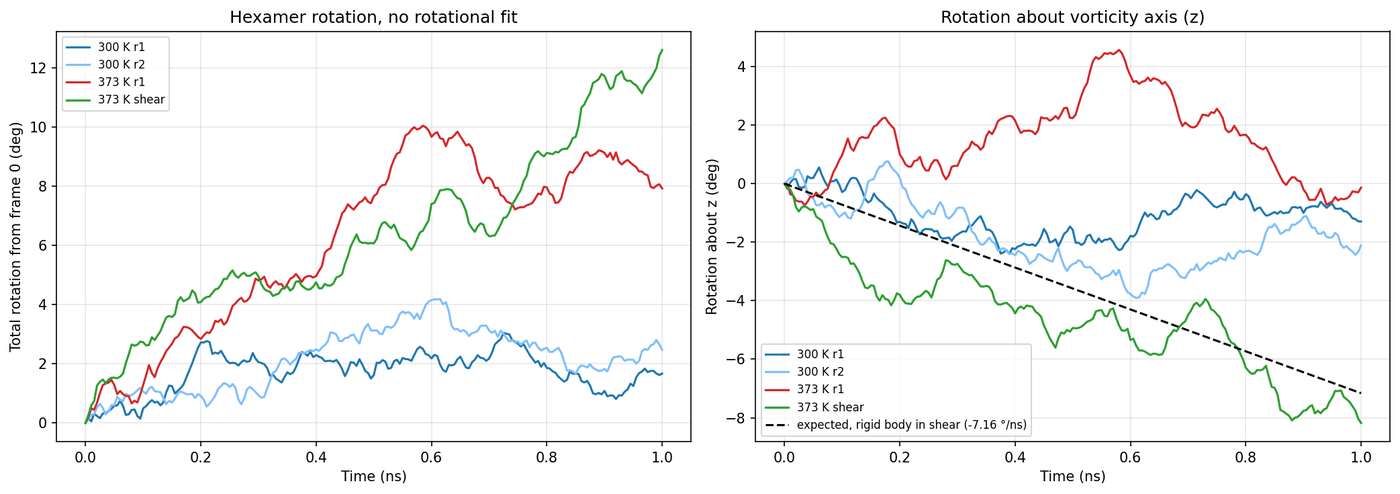

expected rigid rotation about z: -7.16 deg/ns
             run  angle_deg  rot_x  rot_y  rot_z
200  373 K shear       12.6   -4.8   -8.3   -8.2
401     373 K r1        7.9   -5.5    5.7   -0.1
602     300 K r1        1.7    1.0    0.3   -1.3
803     300 K r2        2.5   -1.2    0.5   -2.1


In [ ]:
import os, glob, json, subprocess, numpy as np, pandas as pd, MDAnalysis as mda, matplotlib.pyplot as plt
from MDAnalysis.lib.distances import minimize_vectors
from MDAnalysis.analysis.align import rotation_matrix
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
BASE = "/content/drive/MyDrive/Plant Protein Extrusion MD"
CMP = f"{BASE}/analysism/comparison_legumin"
for d in ("csv","graphs"): os.makedirs(f"{CMP}/{d}", exist_ok=True)
RUNS = {"373 K shear":(BASE,"md_373_shear_r1_combined","legumin_373_shear_r1"),
        "373 K r1":(BASE,"md_373_r1","legumin_373_r1"),
        "300 K r1":(BASE,"md_300_r1","legumin_300_r1"),
        "300 K r2":(BASE,"md_300_r2","legumin_300_r2")}
rows = []; bshear = None
for run, (P, S, name) in RUNS.items():
    F = f"{BASE}/analysism/{name}/frames"
    ranges = json.load(open(f"{F}/chains.json"))["ranges"]; sl = [slice(*ranges[c]) for c in ("chA","chB","chC","chD","chE","chF")]
    subprocess.run(["bash","-c",f'printf "Protein\\n" | gmx trjconv -s "{F}/protein.tpr" -f "{P}/{S}.xtc" -o /tmp/w.xtc -pbc whole > /tmp/w.log 2>&1'])
    u = mda.Universe(f"{F}/first_cl.gro", "/tmp/w.xtc"); ca = u.select_atoms("name CA").indices
    ref = None
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32)
        if run == "373 K shear" and bshear is None: bshear = float(box[1])
        a0 = pos[sl[0]].mean(0)
        for s in sl[1:]:
            d = pos[s].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]
            pos[s] -= (d - dm)
        x = pos[ca]; x = x - x.mean(0)
        if ref is None: ref = x.copy()
        R, _ = rotation_matrix(x, ref); Rt = R.T
        th = np.arccos(np.clip((np.trace(Rt)-1)/2, -1, 1))
        ax = np.array([Rt[2,1]-Rt[1,2], Rt[0,2]-Rt[2,0], Rt[1,0]-Rt[0,1]])
        n = np.linalg.norm(ax); ax = ax/n if n > 1e-12 else np.zeros(3)
        rv = np.degrees(th)*ax
        rows.append(dict(run=run, time_ns=ts.time/1000, angle_deg=np.degrees(th), rot_x=rv[0], rot_y=rv[1], rot_z=rv[2]))
    os.remove("/tmp/w.xtc"); print("done", run)
df = pd.DataFrame(rows); df.round(3).to_csv(f"{CMP}/csv/rotation_no_fit.csv", index=False)

COL = {"300 K r1":"#1f77b4","300 K r2":"#7fbfff","373 K r1":"#d62728","373 K shear":"#2ca02c"}
rate = -0.5*(3.644/(bshear/10))*180/np.pi            # deg/ns about z, from the real box
fig, axs = plt.subplots(1, 2, figsize=(14,5), dpi=150)
for run, d in df.groupby("run"):
    axs[0].plot(d.time_ns, d.angle_deg, color=COL[run], label=run)
    axs[1].plot(d.time_ns, d.rot_z, color=COL[run], label=run)
tt = np.linspace(0, 1, 50); axs[1].plot(tt, rate*tt, "k--", label=f"expected, rigid body in shear ({rate:.2f} °/ns)")
axs[0].set(xlabel="Time (ns)", ylabel="Total rotation from frame 0 (deg)", title="Hexamer rotation, no rotational fit")
axs[1].set(xlabel="Time (ns)", ylabel="Rotation about z (deg)", title="Rotation about vorticity axis (z)")
for a in axs: a.grid(alpha=.3); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{CMP}/graphs/07_rotation_no_fit.png"); plt.show()
print("expected rigid rotation about z:", round(rate,2), "deg/ns")
print(df.groupby("run").tail(1)[["run","angle_deg","rot_x","rot_y","rot_z"]].round(1))

In [ ]:
import subprocess, os
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = '''cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
printf "Pres-XY\\n0\\n" | gmx energy -f md_373_shear_r1_combined.edr -o /tmp/presxy.xvg -b 500 2>&1 | tail -6'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

Statistics over 250001 steps [ 500.0000 through 1000.0000 ps ], 1 data sets
All statistics are over 2501 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Pres-XY                    -1.77653          1    73.8806   0.514453  (bar)
 


In [ ]:
import os, subprocess
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
echo "== setup files"; ls *.mdp *.ndx *.top *.itp 2>/dev/null; ls -d */ 2>/dev/null
echo; echo "== nvt/em/other mdp"; ls | grep -iE "nvt|^em|minim|ions"
for f in npt_373_r1.mdp md_373_r1.mdp md_373_shear_r1.mdp; do echo; echo "===== $f"; grep -vE "^ *;|^ *$" "$f"; done
echo; echo "== nvt mdp (if present)"; for f in nvt*.mdp; do [ -f "$f" ] && { echo "===== $f"; grep -vE "^ *;|^ *$" "$f"; }; done
echo; echo "== log header seeds"; grep -iE "gen[-_]seed|ld[-_]seed|continuation" md_373_r1.mdp npt_373_r1.mdp'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout); print(r.stderr[-300:])

== setup files
em2.mdp
em2_processed.top
em2_resolved.mdp
em3.mdp
em3_resolved.mdp
em.mdp
ions.mdp
md_300_r1.mdp
md300_r1.mdp
md_300_r2.mdp
md_373_r1.mdp
md_373_shear_r1.mdp
mdout.mdp
npt_300_r1.mdp
npt_300_r2.mdp
npt_373_r1.mdp
nvt_300_r1.mdp
nvt_300_r2.mdp
nvt_373_r1.mdp
posre_Protein_chain_A.itp
posre_Protein_chain_B.itp
posre_Protein_chain_C.itp
posre_Protein_chain_D.itp
posre_Protein_chain_E.itp
posre_Protein_chain_F.itp
topol_Protein_chain_A.itp
topol_Protein_chain_B.itp
topol_Protein_chain_C.itp
topol_Protein_chain_D.itp
topol_Protein_chain_E.itp
topol_Protein_chain_F.itp
topol.top
analysis/
analysism/
backups/
old_npt_300_r2_partial/
simulations/
snapshots/
structures/

== nvt/em/other mdp
em2_check.tpr
em2.edr
em2.gro
em2.log
em2.mdp
em2_processed.top
em2_resolved.mdp
em2.tpr
em2.trr
em3.edr
em3.gro
em3.log
em3.mdp
em3_potential.xvg
em3_resolved.mdp
em3.tpr
em3.trr
em.edr
em.gro
em.log
em.mdp
em.tpr
em.trr
ions.mdp
ions.tpr
#ions.tpr.1#
nvt_300_r1.cpt
nvt_300_r1.edr
#nvt_300_r

In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
printf "em.gro atoms: "; head -2 em.gro | tail -1
echo "== molecules in topol.top"; sed -n '/molecules/,$p' topol.top
echo; echo "== grompp"
gmx grompp -f nvt_373_r2.mdp -c em.gro -r em.gro -p topol.top -o nvt_373_r2.tpr -maxwarn 0 2>&1 | grep -iE "warning|error|fatal|total charge|writing" | head -10
ls -lh nvt_373_r1.tpr nvt_373_r2.tpr
echo; echo "== r1 vs r2 tpr"
gmx check -s1 nvt_373_r1.tpr -s2 nvt_373_r2.tpr 2>&1 | grep -vE "^ *$" | head -30'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

em.gro atoms: 217446
== molecules in topol.top
[ molecules ]
; Compound        #mols
Protein_chain_A     1
Protein_chain_B     1
Protein_chain_C     1
Protein_chain_D     1
Protein_chain_E     1
Protein_chain_F     1
SOL         56682
NA               231
CL               195

== grompp
-rw------- 1 root root 19M Oct 12 15:26 nvt_373_r1.tpr
-rw------- 1 root root 19M Oct 17 11:44 nvt_373_r2.tpr

== r1 vs r2 tpr
                :-) GROMACS - gmx check, 2026.3-conda_forge (-:
Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -s1 nvt_373_r1.tpr -s2 nvt_373_r2.tpr
Note: When comparing run input files, default tolerances are reduced.
Reading file nvt_373_r1.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file nvt_373_r2.tpr, VERSION 2026.3-conda_forge (single precision)
comparing inputrec
inputrec->ld_seed (2145005535 - 1731612525)
comparing mtop 

In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
echo "== 1. mdp diff r1 vs r2 (should be gen-seed only)"; diff nvt_373_r1.mdp nvt_373_r2.mdp
echo; echo "== 2. tpr comparison, full (t_resinfo lines hidden)"
gmx check -s1 nvt_373_r1.tpr -s2 nvt_373_r2.tpr 2>&1 | grep -vE "t_resinfo|^ *$" | tail -25
echo; echo "== 3. any existing nvt_373_r2 files besides the tpr (mdrun would append to them)"; ls -lh nvt_373_r2* 2>&1
echo; echo "== 4. how r1 NVT was launched"; grep -A3 -m1 "Command line" nvt_373_r1.log; grep -iE "GPU|nb |pme " nvt_373_r1.log | head -6
echo; echo "== 5. how r1 NPT was started"; grep -A3 -m1 "Command line" npt_373_r1.log 2>/dev/null; ls npt_373_r1*.log
echo; echo "== 6. free Drive space"; df -h /content/drive | tail -1'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== 1. mdp diff r1 vs r2 (should be gen-seed only)
20c20
< gen-seed = 111
---
> gen-seed = 222

== 2. tpr comparison, full (t_resinfo lines hidden)
v[217421] (-1.06935e-01 -1.02081e+00 -5.77442e-01) - (-2.62415e-03  3.73898e-01 -2.35579e-01)
v[217422] (-4.33453e-01  7.92871e-02 -1.10690e-01) - ( 4.07797e-01 -2.69204e-01  2.11602e-01)
v[217423] ( 6.06276e-03  4.52160e-01 -4.77279e-01) - (-2.43050e-01 -2.27485e-01  2.90822e-01)
v[217424] ( 8.18684e-01  3.27849e-01 -5.82081e-01) - ( 6.60657e-03 -1.59668e-01  7.73236e-02)
v[217425] ( 1.00585e-01  5.66767e-02  3.02949e-02) - ( 3.71500e-01 -1.92502e-01 -1.86575e-01)
v[217426] ( 9.08188e-02 -2.71972e-01 -8.36996e-02) - ( 1.22861e-01  2.39811e-01 -1.59322e-01)
v[217427] (-2.38929e-01 -2.44973e-01 -1.33157e-01) - ( 9.70675e-02 -1.97625e-01  1.43095e-01)
v[217428] (-6.65071e-01 -2.84696e-01 -3.10592e-01) - ( 7.24023e-03  7.98802e-02 -3.24835e-02)
v[217429] (-3.29163e-01  2.27023e-01 -1.87674e-01) - (-5.08133e-02 -6.16152e-01  2.59658e-01)
v[21743

In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
gmx check -s1 nvt_373_r1.tpr -s2 nvt_373_r2.tpr > /tmp/chk.txt 2>&1
echo "x lines differing: $(grep -cE '^x\[' /tmp/chk.txt)"
echo "v lines differing: $(grep -cE '^v\[' /tmp/chk.txt)"
echo; echo "== other differences (expect only ld_seed)"
grep -vE "^v\[|^x\[|t_resinfo|^ *$|^comparing|Reading|GROMACS|Executable|Data prefix|Working dir|Command line|gmx check|Note:" /tmp/chk.txt'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

x lines differing: 0
v lines differing: 217446

== other differences (expect only ld_seed)
inputrec->ld_seed (2145005535 - 1731612525)
86e-01  1.64315e-01) - ( 3.30659e-01 -2.84804e-01  5.74925e-01)
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
r = subprocess.run(["bash","-c",'cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && gmx mdrun -deffnm nvt_373_r2 -cpt 5 -ntmpi 1 -ntomp 2 -pin off 2>&1 | tail -5'], capture_output=True, text=True); print(r.stdout)

                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       20.895        1.149        8.270           26.294 

GROMACS reminds you: "At school I had a teacher that didn't like me and I didn't like him. At the end of the year he decided to fail me. The ironic thing is that the topic was chemistry. I have the distinction of being the only Chemistry Laurate who failed the topic in high school." (Thomas Lindahl)




In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
echo "== NVT r2 files"; ls -lh nvt_373_r2.*
echo; echo "== finished normally?"; tail -3 nvt_373_r2.log | head -2; grep -c "Finished mdrun" nvt_373_r2.log
echo; echo "== NVT r2 temperature (avg over run)"
printf "Temperature\n0\n" | gmx energy -f nvt_373_r2.edr -o /tmp/t_r2.xvg 2>&1 | grep -E "Temperature|Statistics"
echo; echo "== same for r1 (comparison)"
printf "Temperature\n0\n" | gmx energy -f nvt_373_r1.edr -o /tmp/t_r1.xvg 2>&1 | grep -E "Temperature"
echo; echo "== NPT r1 mdp vs what r2 will use"; ls npt_373_r2* 2>&1 | head -3
echo; echo "== NPT r1 launch line"; grep -A2 -m1 "Command line" npt_373_r1.part0002.log'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== NVT r2 files
-rw------- 1 root root 5.0M Oct 17 11:56 nvt_373_r2.cpt
-rw------- 1 root root  58K Oct 17 11:56 nvt_373_r2.edr
-rw------- 1 root root  15M Oct 17 11:56 nvt_373_r2.gro
-rw------- 1 root root  93K Oct 17 11:56 nvt_373_r2.log
-rw------- 1 root root  408 Oct 17 11:41 nvt_373_r2.mdp
-rw------- 1 root root  19M Oct 17 11:44 nvt_373_r2.tpr
-rw------- 1 root root 8.6M Oct 17 11:56 nvt_373_r2.xtc

== finished normally?
Performance:       20.895        1.149        8.270           26.294 
Finished mdrun on rank 0 Sat Oct 17 11:56:55 2026
1

== NVT r2 temperature (avg over run)
 13  Kinetic-En.     14  Total-Energy    15  Conserved-En.   16  Temperature   
Statistics over 50001 steps [ 0.0000 through 100.0000 ps ], 1 data sets
Temperature                 372.862       0.28    3.99867    1.43577  (K)

== same for r1 (comparison)
 13  Kinetic-En.     14  Total-Energy    15  Conserved-En.   16  Temperature   
Temperature                 372.695       0.29    3.97117    1.58223  (K)


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
cp npt_373_r1.mdp npt_373_r2.mdp
echo "== mdp diff r1 vs r2 (expect none)"; diff npt_373_r1.mdp npt_373_r2.mdp && echo IDENTICAL
echo; echo "== grompp"
gmx grompp -f npt_373_r2.mdp -c nvt_373_r2.gro -r nvt_373_r2.gro -t nvt_373_r2.cpt -p topol.top -o npt_373_r2.tpr -maxwarn 0 > /tmp/g.txt 2>&1
grep -iE "warning|error|fatal|note" /tmp/g.txt | head -10; tail -3 /tmp/g.txt
ls -lh npt_373_r1.tpr npt_373_r2.tpr
echo; echo "== inputrec/topology differences vs r1 (x, v, resinfo hidden)"
gmx check -s1 npt_373_r1.tpr -s2 npt_373_r2.tpr 2>&1 | grep -vE "^v\[|^x\[|t_resinfo|^ *$|^comparing|Reading|GROMACS|Executable|Data prefix|Working dir|Command line|gmx check|Note:|^ *[0-9.e+-]+ +[0-9.e+-]+ +[0-9.e+-]+\)"
echo; echo "== atoms"; gmx check -s npt_373_r2.tpr 2>&1 | grep -iE "natoms"'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== mdp diff r1 vs r2 (expect none)
IDENTICAL

== grompp
NOTE 1 [file npt_373_r2.mdp]:
There was 1 NOTE
Note that mdrun will redetermine rlist based on the actual pair-list setup
Estimate for the relative computational load of the PME mesh part: 0.28

This run will generate roughly 71 Mb of data
-rw------- 1 root root 19M Oct 12 15:35 npt_373_r1.tpr
-rw------- 1 root root 19M Oct 17 12:00 npt_373_r2.tpr

== inputrec/topology differences vs r1 (x, v, resinfo hidden)
inputrec->posresCom[    0] ( 5.00049e-01  5.00018e-01  4.99935e-01) - ( 5.00013e-01  5.00023e-01  4.99996e-01)
inputrec->posresComB[    0] ( 5.00049e-01  5.00018e-01  4.99935e-01) - ( 5.00013e-01  5.00023e-01  4.99996e-01)
inputrec->ld_seed (243069935 - -4849700)

== atoms
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
r = subprocess.run(["bash","-c",'cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && gmx mdrun -deffnm npt_373_r2 -cpt 5 -ntmpi 1 -ntomp 2 -pin off 2>&1 | tail -5'], capture_output=True, text=True); print(r.stdout)

                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       19.580        1.226        8.825           24.639 

GROMACS reminds you: "She's a Good Sheila Bruce" (Monty Python)




In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
echo "== NPT r2 files"; ls -lh npt_373_r2.*
echo; echo "== finished normally? (expect 1)"; grep -c "Finished mdrun" npt_373_r2.log
echo; echo "== averages"
printf "Temperature\nPressure\nDensity\n0\n" | gmx energy -f npt_373_r2.edr -o /tmp/npt_r2.xvg 2>&1 | grep -E "^(Temperature|Pressure|Density)"
echo; echo "== r1 NPT edr files (for comparison)"; ls npt_373_r1*.edr'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== NPT r2 files
-rw------- 1 root root 5.0M Oct 17 12:49 npt_373_r2.cpt
-rw------- 1 root root 324K Oct 17 12:49 npt_373_r2.edr
-rw------- 1 root root  15M Oct 17 12:49 npt_373_r2.gro
-rw------- 1 root root 353K Oct 17 12:49 npt_373_r2.log
-rw------- 1 root root  481 Oct 17 12:00 npt_373_r2.mdp
-rw------- 1 root root  19M Oct 17 12:00 npt_373_r2.tpr
-rw------- 1 root root  40M Oct 17 12:49 npt_373_r2.xtc

== finished normally? (expect 1)
1

== averages
Temperature                 372.985      0.047   0.900719   0.063157  (K)
Pressure                    2.82916        3.5    132.354   -4.05921  (bar)
Density                     1041.42       0.11    1.31391  -0.652396  (kg/m^3)

== r1 NPT edr files (for comparison)
npt_373_r1.part0002.edr
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
echo "== shear r1 mdp"; cat md_373_shear_r1.mdp
echo; echo "== shear mdp vs thermal mdp (what the shear adds)"; diff md_373_r1.mdp md_373_shear_r1.mdp
echo; echo "== shear r1 launch line (original)"; grep -A2 -m1 "Command line" md_373_shear_r1.log
echo; echo "== shear r1 restart line (part0002)"; grep -A2 -m1 "Command line" md_373_shear_r1.part0002.log
echo; echo "== did shear r1 start from the same structure as thermal r1?"
gmx check -s1 md_373_r1.tpr -s2 md_373_shear_r1.tpr 2>&1 | grep -cE "^x\["
echo; echo "== any r2 shear files (expect none)"; ls md_373_shear_r2* 2>&1'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== shear r1 mdp
integrator = md
dt = 0.002
nsteps = 500000
continuation = yes
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = System
tau-t = 0.1
ref-t = 373
pcoupl = no
deform = 0 0 0 0.003644 0 0
gen-vel = no
ld-seed = 111
nstenergy = 500
nstlog = 5000
nstxout-compressed = 500
compressed-x-grps = Protein

== shear mdp vs thermal mdp (what the shear adds)
2a3,4
> nsteps = 500000
> continuation = yes
11,15c13,15
< tc-grps = Protein Non-Protein
< tau-t = 0.1 0.1
< ref-t = 373 373
< nsteps = 500000
< continuation = yes
---
> tc-grps = System
> tau-t = 0.1
> ref-t = 373
16a17
> deform = 0 0 0 0.003644 0 0

== shear r1 launch line (original)
Command line:
  gmx mdrun -deffnm md_373_shear_r1 -cpt 5 -ntmpi 1 -ntomp 2 -pin off


== shear r1 restart line (part0002)
Command line:
  gmx mdrun -s md_373_shear_r1.tpr -deffnm md_373_shear_r1 -cpi md_373_shear_r1.cpt -noappend -cpt 5

In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
sed 's/^ld-seed = 111/ld-seed = 222/' md_373_shear_r1.mdp > md_373_shear_r2.mdp
echo "== mdp diff r1 vs r2 (expect ld-seed only)"; diff md_373_shear_r1.mdp md_373_shear_r2.mdp
echo; echo "== grompp"
gmx grompp -f md_373_shear_r2.mdp -c npt_373_r2.gro -t npt_373_r2.cpt -p topol.top -o md_373_shear_r2.tpr -maxwarn 0 > /tmp/g.txt 2>&1
grep -iE "warning|error|fatal|note" /tmp/g.txt | head -10; tail -3 /tmp/g.txt
ls -lh md_373_shear_r1.tpr md_373_shear_r2.tpr
echo; echo "== inputrec differences vs r1 (x, v, resinfo hidden)"
gmx check -s1 md_373_shear_r1.tpr -s2 md_373_shear_r2.tpr 2>&1 | grep -vE "^v\[|^x\[|t_resinfo|^ *$|^comparing|Reading|GROMACS|Executable|Data prefix|Working dir|Command line|gmx check|Note:|^ *[0-9.e+-]+ +[0-9.e+-]+ +[0-9.e+-]+\)"
echo; echo "== did r1 shear and r1 thermal share velocities? (v lines differing, 0 means same NPT start)"
gmx check -s1 md_373_r1.tpr -s2 md_373_shear_r1.tpr 2>&1 | grep -cE "^v\["
echo; echo "== r2 shear files (expect mdp and tpr only)"; ls md_373_shear_r2*'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== mdp diff r1 vs r2 (expect ld-seed only)
19c19
< ld-seed = 111
---
> ld-seed = 222

== grompp
Note that mdrun will redetermine rlist based on the actual pair-list setup
Estimate for the relative computational load of the PME mesh part: 0.29

This run will generate roughly 242 Mb of data
-rw------- 1 root root 16M Oct 13 17:28 md_373_shear_r1.tpr
-rw------- 1 root root 16M Oct 18 08:16 md_373_shear_r2.tpr

== inputrec differences vs r1 (x, v, resinfo hidden)
inputrec->ld_seed (111 - 222)
box[    0] ( 1.45765e+01  0.00000e+00  0.00000e+00) - ( 1.45765e+01  0.00000e+00  0.00000e+00)
box[    1] ( 0.00000e+00  1.45765e+01  0.00000e+00) - ( 0.00000e+00  1.45765e+01  0.00000e+00)
box[    2] ( 7.28823e+00  7.28823e+00  1.03071e+01) - ( 7.28825e+00  7.28825e+00  1.03071e+01)
6] ( 4.19232e-01 -1.42593e-01  2.40061e-01) - (-6.03637e-01 -3.48740e-01  2.88720e-01)

== did r1 shear and r1 thermal share velocities? (v lines differing, 0 means same NPT start)
0

== r2 shear files (expect mdp and tpr

In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
r = subprocess.run(["bash","-c",'cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && gmx mdrun -deffnm md_373_shear_r2 -cpt 5 -ntmpi 1 -ntomp 2 -pin off 2>&1 | tail -5'], capture_output=True, text=True); print(r.stdout)

                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       16.480        1.456       10.485           20.738 

GROMACS reminds you: "I don't believe in astrology; I'm a Sagittarian and we're skeptical." (Arthur C. Clarke)




In [ ]:
import os, subprocess
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || { echo "FOLDER NOT FOUND - wrong Drive account?"; exit 1; }
echo "== shear r2 files"; ls -lh --time-style=+%H:%M md_373_shear_r2*
echo; echo "== finished normally? (expect 1 per log)"
for f in md_373_shear_r2.log md_373_shear_r2.part0002.log; do [ -f $f ] && echo "$f: $(grep -c 'Finished mdrun' $f)"; done
echo; echo "== xtc first / last frame"
for f in md_373_shear_r2.xtc md_373_shear_r2.part0002.xtc md_373_shear_r2_combined.xtc; do [ -f $f ] && { echo $f; gmx check -f $f 2>&1 | grep -E "Reading frame +0 |Last frame|^Step"; }; done
echo; echo "== checkpoint time"; gmx check -f md_373_shear_r2.cpt 2>&1 | grep -E "Last frame"
echo; echo "== energies"
for f in md_373_shear_r2.edr md_373_shear_r2.part0002.edr; do [ -f $f ] && { echo $f; printf "Temperature\n0\n" | gmx energy -f $f -o /tmp/t.xvg 2>&1 | grep -E "Statistics|^Temperature"; }; done
echo; echo "== final box (6th number = tilt, expect about 3.644)"
for f in md_373_shear_r2.part0002.gro md_373_shear_r2.gro; do [ -f $f ] && { echo $f; tail -1 $f; }; done
echo; echo "== backup folder"; ls backups 2>&1 | head'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

Mounted at /content/drive
== shear r2 files
-rw------- 1 root root 5.0M 09:46 md_373_shear_r2.cpt
-rw------- 1 root root 646K 08:18 md_373_shear_r2.edr
-rw------- 1 root root  15M 09:45 md_373_shear_r2.gro
-rw------- 1 root root  90K 09:46 md_373_shear_r2.log
-rw------- 1 root root  410 08:16 md_373_shear_r2.mdp
-rw------- 1 root root 5.0M 09:46 md_373_shear_r2_prev.cpt
-rw------- 1 root root  16M 08:16 md_373_shear_r2.tpr
-rw------- 1 root root 172M 08:18 md_373_shear_r2.xtc

== finished normally? (expect 1 per log)
md_373_shear_r2.log: 1

== xtc first / last frame
md_373_shear_r2.xtc

== checkpoint time

== energies
md_373_shear_r2.edr

== final box (6th number = tilt, expect about 3.644)
md_373_shear_r2.gro
  14.57650  14.57650  10.30714   0.00000   0.00000   3.64400   0.00000   7.28825   7.28825

== backup folder
md_373_shear_r1
md_373_shear_r2_backup
npt_373_r2_auto
 


In [ ]:
import os, sys, json, itertools, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
TEMP, RUN = "373", "shear_r2"
TPR_NAME  = "md_373_shear_r2"                 # tpr
TRAJ_NAME = "md_373_shear_r2"                 # ran in one part, no combine needed
NCH = 6; DEFORM = 3.644                        # hexamer; nm/ns tilt from the mdp
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
if os.system("gmx --version > /dev/null 2>&1") != 0: raise SystemExit("GROMACS not found - run your GROMACS setup cell first, then run this cell again")
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
OUT = f"/content/pm/analysism/legumin_{TEMP}_{RUN}"; T = "373 K shear (r2)"
os.environ.update(P="/content/pm", S=TPR_NAME, TRAJ=TRAJ_NAME, OUT=OUT)
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f"{OUT}/{d}", exist_ok=True)
subprocess.run([sys.executable,"-m","pip","install","-q","MDAnalysis","scipy"])
import MDAnalysis as mda
from MDAnalysis.coordinates.XTC import XTCReader
from MDAnalysis.lib.distances import minimize_vectors
from MDAnalysis.analysis.align import rotation_matrix
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap
def sh(cmd, tail=0):
    r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True)
    o = (r.stdout + r.stderr).strip().split("\n")
    print("\n".join(o[-tail:] if tail else o))

# ---- check files, mdp, and trajectory continuity
print("== files"); sh('ls -lh $P/$S.tpr $P/$TRAJ.xtc; grep -iE "ref[-_]t|deform" $P/$S.mdp')
rd = XTCReader(f"{OUT.rsplit('/analysism',1)[0]}/{TRAJ_NAME}.xtc")
times = np.array([ts.time for ts in rd]); dims = np.array([ts.dimensions.copy() for ts in rd])
print("frames:", len(times), "| time", times[0], "->", times[-1], "| natoms:", rd.n_atoms)
assert times[0] == 0 and abs(times[-1]-1000) < 1e-3 and len(times) == 1001 and np.all(np.diff(times) == 1), "trajectory not continuous 0-1000 ps"
print("box a,b,c start:", dims[0,:3].round(2), "end:", dims[-1,:3].round(2))
print("angles start:", dims[0,3:].round(2), "end:", dims[-1,3:].round(2))
gd = DEFORM/(dims[0,1]/10); print(f"shear rate {gd:.4f} /ns -> expected rigid rotation {-0.5*gd*180/np.pi:.2f} deg/ns about z")

# ---- protein tpr, whole, first frame
print("== whole")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$TRAJ.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1''')

# ---- chain detection from .gro
lines = open(f"{OUT}/frames/first_w.gro").read().split("\n")
n = int(lines[1]); body = lines[2:2+n]
resnum = np.array([int(l[0:5]) for l in body]); nm = [l[10:15].strip() for l in body]
starts = [0] + [i for i in range(1, n) if resnum[i] < resnum[i-1]]; ends = starts[1:] + [n]
nres = [len(set(resnum[s:e])) for s, e in zip(starts, ends)]
print("atoms:", n, "| chains:", len(starts), "| atoms/chain:", [e-s for s,e in zip(starts,ends)], "| res/chain:", nres)
assert len(starts) == NCH, f"expected {NCH} chains - send me the line above"
assert len(set(e-s for s,e in zip(starts,ends))) == 1, "chains differ in size - send me the line above"
NR = nres[0]; CH = ["ch"+"ABCDEF"[i] for i in range(NCH)]; G = {}; ranges = {}
for k, (s, e) in enumerate(zip(starts, ends)):
    r = range(s+1, e+1); c = CH[k]; ranges[c] = [s, e]
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
r = range(1, n+1)
G["Protein"] = list(r); G["Protein_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G["Protein_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:5d}" for i in idx[k:k+15]) + "\n")
json.dump(dict(ranges=ranges, nres=NR, natoms=n), open(f"{OUT}/frames/chains.json","w"))

# ---- keep chains together (triclinic-safe)
sl = [slice(*ranges[c]) for c in CH]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32); a0 = pos[sl[0]].mean(0)
        for s in sl[1:]:
            d = pos[s].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]; pos[s] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

# ---- fit
print("== fit")
sh(r'''cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|^Step"''')

# ---- hexamer integrity check
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
pairs = list(itertools.combinations(range(NCH), 2)); worst = {p: 0.0 for p in pairs}; lonely = 0
for ts in u.trajectory:
    Pp = u.atoms.positions/10; ch = [Pp[s] for s in sl]
    m = {p: cKDTree(ch[p[0]]).query(ch[p[1]])[0].min() for p in pairs}
    for p in pairs: worst[p] = max(worst[p], m[p])
    for i in range(NCH):
        if min(m[p] for p in pairs if i in p) > 0.5: lonely += 1
print({"ABCDEF"[a]+"ABCDEF"[b]: round(float(v),2) for (a,b), v in worst.items()})
print("chains with no neighbour within 0.5 nm:", lonely)
assert lonely == 0, "a chain drifted away"

# ---- GROMACS analysis
print("== gmx analysis (slow)")
PAIRSTR = " ".join(f'"{a} {b}"' for a, b in itertools.combinations(CH, 2))
os.environ.update(CHS=" ".join(["Protein"]+CH), PAIRSTR=PAIRSTR)
sh(r'''cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in $CHS; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
eval "for p in $PAIRSTR; do set -- \$p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r \"group \$1\" -t \"group \$2\" -num $X/hbinter_\$1_\$2.xvg -tu ns > $L/hbinter_\$1_\$2.log 2>&1
done"
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done''')

# ---- plots
X = f"{OUT}/xvgs"
cols = ["#d62728","#1f77b4","#2ca02c","#ff9896","#7fbfff","#98df8a"]
sty = {c: dict(color=cols[i], ls="-" if i%2==0 else ":", label="Chain "+c[-1]) for i, c in enumerate(CH)}
xvg = lambda f: np.loadtxt(f, comments=('#','@'))
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.6, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(ncol=2); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
chains = lambda pre, col=1, sc=1: [(xvg(f"{X}/{pre}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{pre}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(pre, col=1, sc=1):
    a = xvg(f"{X}/{pre}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole hexamer"))]
for pre, yl, ttl, sc in (("rmsd","RMSD (nm)","Backbone RMSD",1), ("rg","Rg (nm)","Radius of gyration",1000),
                         ("sasa","SASA (nm²)","SASA",1), ("hbnum","H-bonds","Intra-chain H-bonds",1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, {T}", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole hexamer, {T}", "Time (ns)", yl, whole(pre, 1, sc))
draw("rmsf_per_chain", f"C-alpha RMSF per residue, {T}", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == NCH*NR, len(d)
draw("sasa_per_residue", f"SASA per residue, {T}", "Residue", "SASA (nm²)",
     [(np.arange(1,NR+1), d[i*NR:(i+1)*NR,1], s) for i, s in enumerate(sty.values())])
fig, ax = plt.subplots(figsize=(12,6), dpi=150)
for k, (a_, b_) in enumerate(itertools.combinations(CH, 2)):
    h = xvg(f"{X}/hbinter_{a_}_{b_}.xvg"); ax.plot(h[:,0], h[:,1], lw=1.2, color=plt.cm.tab10(k), label=f"{a_[-1]}–{b_[-1]}")
ax.set(xlabel="Time (ns)", ylabel="H-bonds", title=f"Inter-chain H-bonds, {T}"); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/hbonds_inter_chain.png"); plt.show()

# ---- per-residue RMSD and H-bonds
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
NA = u.atoms.n_atoms // NCH; cs = {c: slice(i*NA, (i+1)*NA) for i, c in enumerate(CH)}; resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); k = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); k += 1
    resR[name] = np.sqrt(d2/k)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,NR+1), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", f"C-alpha RMSD per residue vs first frame, {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), resR[c], s) for c, s in sty.items()])
draw("rmsd_per_residue_mean", f"Mean C-alpha RMSD per residue ({NCH} chains), {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), np.mean(list(resR.values()), axis=0), dict(color="grey", label="Mean of chains"))])

nmA = np.array([x.strip() for x in u.atoms.names]); rn = u.atoms.resnames
chain = np.arange(len(nmA)) // NA; ridx = u.atoms.resindices - chain*NR
assert ridx.min() == 0 and ridx.max() == NR-1
isH = np.array([x.startswith("H") for x in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
kk = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[kk], don[kk]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((NCH,NR)); inter = np.zeros((NCH,NR)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; k = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D_ = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D_ or (chain[A]==chain[D_] and ridx[A]==ridx[D_]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D_], Pf[A]-Pf[D_]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            k += 1
            for Xa in (D_, A):
                tot[chain[Xa], ridx[Xa]] += 1
                if chain[D_] != chain[A]: inter[chain[Xa], ridx[Xa]] += 1
    nb.append(k)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(CH): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,NR+1), arr[i]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, {T}", "Residue", "H-bonds per frame", [(np.arange(1,NR+1), arr[i]/nf, s) for i, s in enumerate(sty.values())])

# ---- DSSP
print("== dssp")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_Protein.dat" > "$OUT/logs/dssp_Protein.log" 2>&1
cp "$OUT/xvgs/dssp_Protein.dat" "$OUT/xvgs/dssp_chA.dat"
head -c 80 "$OUT/xvgs/dssp_Protein.dat"; echo''')
a = np.array([list(l.rstrip("\n")) for l in open(f"{X}/dssp_Protein.dat") if l.strip()])
a = a[:, ~(a == "=").all(0)]; print("dssp shape:", a.shape); assert a.shape[1] == NCH*NR, a.shape
Dd = {c: a[:, i*NR:(i+1)*NR] for i, c in enumerate(CH)}; t = np.arange(len(a))*0.005
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(Dd[c], list(ss)).mean(1), lw=1.6, **s)
        print(name, c, "mean %:", round(100*np.isin(Dd[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(Dd[c], list(ss)).mean(0); ax.plot(np.arange(1,NR+1), f, lw=1.4, **s)
        np.savetxt(f"{X}/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,NR+1), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items(): ax.plot(t, 100*(1-np.isin(Dd[c], list("HGIEB")).mean(1)), lw=1.6, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title=f"Coil/turn content vs time, {T}")
ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()
cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(NCH, 1, figsize=(12,2.2*NCH+1), dpi=150, sharex=True)
for ax, (c, s) in zip(np.atleast_1d(axs), sty.items()):
    ax.imshow(code(Dd[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,NR,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
np.atleast_1d(axs)[-1].set_xlabel("Residue"); fig.suptitle(f"DSSP map: red = helix, blue = strand, grey = coil/turn, {T}")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

# ---- summary + all-states plots
def last(f, col=1): b = xvg(f); return b[len(b)//2:, col].mean()
h = len(t)//2; rows = []
for c in CH:
    rows.append(dict(chain=c, RMSD_nm=last(f"{X}/rmsd_{c}.xvg"), Rg_nm=last(f"{X}/rg_{c}.xvg"),
      SASA_nm2=last(f"{X}/sasa_{c}.xvg", 2), intra_Hbonds=last(f"{X}/hbnum_{c}.xvg"),
      helix_pct=100*np.isin(Dd[c][h:], list("HGI")).mean(), strand_pct=100*np.isin(Dd[c][h:], list("EB")).mean()))
rows.append(dict(chain="hexamer", RMSD_nm=last(f"{X}/rmsd_Protein.xvg"), Rg_nm=last(f"{X}/rg_Protein.xvg"),
                 SASA_nm2=last(f"{X}/sasa_Protein.xvg"), intra_Hbonds=last(f"{X}/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{X}/summary_last0.5ns.csv", index=False); print(df)
STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
Pc = {k_: 100*(a == c_).mean(1) for k_, c_ in STATES}; Pc["Coil / Unstructured"] = 100 - sum(Pc.values())
tp = np.arange(len(a))*5.0
fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (k_, y) in enumerate(Pc.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.6, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Legumin All Secondary Structure States — {T}")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_{TEMP}K_{RUN}.png"); plt.show()
Gp = {"Alpha helix": Pc["Alpha helix"], "Beta structure": Pc["Beta strand"]+Pc["Beta bridge"], "Turns": Pc["Turn"]}
Gp["Loops / Other"] = 100 - sum(Gp.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (k_, y) in enumerate(Gp.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.8, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Legumin Secondary Structure — {T}")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_{TEMP}K_{RUN}.png"); plt.show()
print("DONE ->", OUT)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import os, subprocess
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD/analysism" || exit 1
D=legumin_373_shear_r2
echo "== graphs ($(ls $D/graphs/*.png 2>/dev/null | wc -l), expect 23)"
echo; echo "== xvg files that are empty or missing (expect nothing)"
for c in Protein chA chB chC chD chE chF; do for p in rmsd rmsf rg sasa hbnum; do [ -s $D/xvgs/${p}_$c.xvg ] || echo "MISSING/EMPTY: ${p}_$c"; done; done
for a in chA chB chC chD chE chF; do for b in chA chB chC chD chE chF; do [[ "$a" < "$b" ]] && { [ -s $D/xvgs/hbinter_${a}_${b}.xvg ] || echo "MISSING/EMPTY: hbinter_${a}_${b}"; }; done; done
for f in sasa_perres_Protein.xvg dssp_Protein.dat summary_last0.5ns.csv; do [ -s $D/xvgs/$f ] || echo "MISSING/EMPTY: $f"; done
echo; echo "== errors in gmx logs (expect nothing)"; grep -liE "fatal error|segmentation|not found|invalid" $D/logs/*.log
echo; echo "== analysis folders"; ls -d */
for d in $(ls -d */ | tr -d / | grep -E "^legumin_373"); do
  echo; echo "== $d"; cat $d/xvgs/summary_last0.5ns.csv 2>/dev/null || echo "(no summary)"
done'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== graphs (23, expect 23)

== xvg files that are empty or missing (expect nothing)

== errors in gmx logs (expect nothing)

== analysis folders
comparison_legumin/
legumin_300_r1/
legumin_300_r2/
legumin_373_r1/
legumin_373_shear_r1/
legumin_373_shear_r2/

== legumin_373_r1
chain,RMSD_nm,Rg_nm,SASA_nm2,intra_Hbonds,helix_pct,strand_pct
chA,0.273,2.707,151.535,363.257,10.352,28.152
chB,0.276,2.684,149.685,345.139,10.985,25.773
chC,0.24,2.693,151.247,361.317,10.192,29.242
chD,0.254,2.699,151.244,353.347,10.586,26.717
chE,0.261,2.692,147.36,346.149,12.678,28.615
chF,0.284,2.687,145.6,358.752,10.773,26.535
hexamer,0.317,3.951,896.705,2629.891,,

== legumin_373_shear_r1
chain,RMSD_nm,Rg_nm,SASA_nm2,intra_Hbonds,helix_pct,strand_pct
chA,0.28,2.732,150.913,355.693,10.168,26.286
chB,0.291,2.697,151.387,347.554,11.177,27.99
chC,0.273,2.729,154.166,344.752,11.133,27.423
chD,0.258,2.716,150.59,355.97,12.442,26.485
chE,0.248,2.699,151.627,361.317,10.943,28.399
chF,0.235,2.685,146.212,350.644,9.915

In [ ]:
import os, subprocess
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD/analysism" || exit 1
for d in legumin_300_r1 legumin_300_r2; do echo "== $d"; grep -E "^(chain|hexamer)" $d/xvgs/summary_last0.5ns.csv; done'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== legumin_300_r1
chain,RMSD_nm,Rg_nm,SASA_nm2,intra_Hbonds,helix_pct,strand_pct
hexamer,0.267,3.919,874.763,2707.455,,
== legumin_300_r2
chain,RMSD_nm,Rg_nm,SASA_nm2,intra_Hbonds,helix_pct,strand_pct
hexamer,0.27,3.93,891.514,2730.614,,
 


In [ ]:
import os, subprocess
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD/analysism" || exit 1
for d in legumin_300_r1 legumin_300_r2; do echo "== $d"; grep -E "^(chain|hexamer)" $d/xvgs/summary_last0.5ns.csv; done'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== legumin_300_r1
== legumin_300_r2
 grep: legumin_300_r1/xvgs/summary_last0.5ns.csv: No such file or directory
grep: legumin_300_r2/xvgs/summary_last0.5ns.csv: No such file or directory



In [ ]:
import os, subprocess
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''command -v gmx >/dev/null || { echo "STOP: GROMACS NOT FOUND - run your GROMACS setup cell first"; exit 1; }
cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || { echo "STOP: folder not found - wrong Drive account?"; exit 1; }
ls npt_373_r2.gro npt_373_r2.cpt md_373_r1.mdp md_373_r1.tpr || { echo "STOP: a needed input file is missing"; exit 1; }
if ls md_373_r2.* >/dev/null 2>&1; then echo "STOP: md_373_r2 files already exist:"; ls md_373_r2.*; exit 0; fi
echo; echo "== r1 thermal mdp (key lines)"; grep -iE "^ *(define|nsteps|continuation|gen[-_]vel|pcoupl|tc-grps|ref-t|ld-seed)" md_373_r1.mdp
echo; echo "== r1 thermal launch line"; grep -A1 -m1 "Command line" md_373_r1.log
sed 's/^ld-seed = 111/ld-seed = 222/' md_373_r1.mdp > md_373_r2.mdp
grep -q "^ld-seed = 222" md_373_r2.mdp || { echo "STOP: no 'ld-seed = 111' line found to change"; rm -f md_373_r2.mdp; exit 0; }
R=""; grep -qiE "^ *define" md_373_r1.mdp && R="-r npt_373_r2.gro"
echo; echo "== restraint reference flag used: '$R'"
echo; echo "== mdp diff r1 vs r2 (expect ld-seed only)"; diff md_373_r1.mdp md_373_r2.mdp
echo; echo "== grompp"
gmx grompp -f md_373_r2.mdp -c npt_373_r2.gro $R -t npt_373_r2.cpt -p topol.top -o md_373_r2.tpr -maxwarn 0 > /tmp/g.txt 2>&1
grep -iE "warning|error|fatal|note" /tmp/g.txt | head -10; tail -3 /tmp/g.txt
ls -lh md_373_r1.tpr md_373_r2.tpr
echo; echo "== inputrec differences vs r1 (x, v, resinfo hidden)"
gmx check -s1 md_373_r1.tpr -s2 md_373_r2.tpr 2>&1 | grep -vE "^v\[|^x\[|t_resinfo|^ *$|^comparing|Reading|GROMACS|Executable|Data prefix|Working dir|Command line|gmx check|Note:|^ *[0-9.e+-]+ +[0-9.e+-]+ +[0-9.e+-]+\)"
echo; echo "== r2 thermal files (expect mdp and tpr only)"; ls md_373_r2.*'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

md_373_r1.mdp
md_373_r1.tpr
npt_373_r2.cpt
npt_373_r2.gro
STOP: md_373_r2 files already exist:
md_373_r2.mdp
md_373_r2.tpr
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''command -v gmx >/dev/null || { echo "STOP: GROMACS NOT FOUND - run your GROMACS setup cell first"; exit 1; }
cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
echo "== files"; ls -l --time-style=+%d-%b_%H:%M md_373_r2.mdp md_373_r2.tpr npt_373_r2.gro npt_373_r2.cpt
echo; echo "== mdp diff r1 vs r2 (expect ld-seed 111 vs 222 only)"; diff md_373_r1.mdp md_373_r2.mdp && echo IDENTICAL
echo; echo "== tpr settings"; gmx dump -s md_373_r2.tpr 2>/dev/null | head -900 | grep -E "nsteps|ld-seed|continuation|gen-vel|natoms" | head -8
echo; echo "== other md_373_r2 outputs (expect none)"; ls md_373_r2.* | grep -vE "\.(mdp|tpr)$"; echo done'''
p = subprocess.Popen(["bash","-c",cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in p.stdout: print(line, end="")

== files
-rw------- 1 root root      403 18-Oct_08:15 md_373_r2.mdp
-rw------- 1 root root 16645796 18-Oct_08:15 md_373_r2.tpr
-rw------- 1 root root  5220916 17-Oct_12:49 npt_373_r2.cpt
-rw------- 1 root root 15003889 17-Oct_12:49 npt_373_r2.gro

== mdp diff r1 vs r2 (expect ld-seed 111 vs 222 only)
18c18
< ld-seed = 111
---
> ld-seed = 222

== tpr settings
   nsteps                         = 500000
   ld-seed                        = 222
   continuation                   = true
   natoms = 217446

== other md_373_r2 outputs (expect none)
done


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''command -v gmx >/dev/null || { echo "STOP: GROMACS NOT FOUND - run your GROMACS setup cell first"; exit 1; }
cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || { echo "STOP: folder not found - wrong Drive account?"; exit 1; }
if ls md_373_r2.* | grep -qvE "\.(mdp|tpr)$"; then echo "STOP: md_373_r2 output files already exist:"; ls md_373_r2.*; exit 0; fi
gmx mdrun -deffnm md_373_r2 -cpt 5 -ntmpi 1 -ntomp 2 -pin off 2>&1 | tail -5'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       24.333        0.986        7.102           30.620 

GROMACS reminds you: "User-friendly, adj.: Programmer-hostile." (New Hacker's Dictionary)

 


In [ ]:
import os, sys, json, itertools, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
TEMP, RUN = "373", "r2"
TPR_NAME  = "md_373_r2"                       # thermal r2 tpr
TRAJ_NAME = "md_373_r2"                       # ran in one part
NCH = 6; DEFORM = 0.0                          # hexamer; thermal run, no shear
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
if os.system("gmx --version > /dev/null 2>&1") != 0: raise SystemExit("GROMACS not found - run your GROMACS setup cell first, then run this cell again")
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
PM = "/content/drive/MyDrive/Plant Protein Extrusion MD"
if os.path.exists(f"{PM}/md_373_r2.part0002.xtc"): raise SystemExit("md_373_r2 was restarted (part0002 files exist) - combine the parts first; send me the file list")
if not os.path.exists(f"{PM}/md_373_r2.log") or "Finished mdrun" not in open(f"{PM}/md_373_r2.log").read(): raise SystemExit("md_373_r2.log is missing or has no Finished mdrun line - the run did not finish")
OUT = f"/content/pm/analysism/legumin_{TEMP}_{RUN}"; T = "373 K thermal (r2)"
os.environ.update(P="/content/pm", S=TPR_NAME, TRAJ=TRAJ_NAME, OUT=OUT)
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f"{OUT}/{d}", exist_ok=True)
subprocess.run([sys.executable,"-m","pip","install","-q","MDAnalysis","scipy"])
import MDAnalysis as mda
from MDAnalysis.coordinates.XTC import XTCReader
from MDAnalysis.lib.distances import minimize_vectors
from MDAnalysis.analysis.align import rotation_matrix
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap
def sh(cmd, tail=0):
    r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True)
    o = (r.stdout + r.stderr).strip().split("\n")
    print("\n".join(o[-tail:] if tail else o))

# ---- check files, mdp, and trajectory continuity
print("== files"); sh('ls -lh $P/$S.tpr $P/$TRAJ.xtc; grep -iE "ref[-_]t|deform" $P/$S.mdp')
rd = XTCReader(f"{OUT.rsplit('/analysism',1)[0]}/{TRAJ_NAME}.xtc")
times = np.array([ts.time for ts in rd]); dims = np.array([ts.dimensions.copy() for ts in rd])
print("frames:", len(times), "| time", times[0], "->", times[-1], "| natoms:", rd.n_atoms)
assert rd.n_atoms < 100000, "xtc is not protein-only (whole system) - send me this number"
assert times[0] == 0 and abs(times[-1]-1000) < 1e-3 and len(times) == 1001 and np.all(np.diff(times) == 1), "trajectory not continuous 0-1000 ps"
print("box a,b,c start:", dims[0,:3].round(2), "end:", dims[-1,:3].round(2))
print("angles start:", dims[0,3:].round(2), "end:", dims[-1,3:].round(2))
if DEFORM:
    gd = DEFORM/(dims[0,1]/10); print(f"shear rate {gd:.4f} /ns -> expected rigid rotation {-0.5*gd*180/np.pi:.2f} deg/ns about z")
else: print("thermal run: box angles should stay 60/60/90")

# ---- protein tpr, whole, first frame
print("== whole")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$TRAJ.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1''')

# ---- chain detection from .gro
lines = open(f"{OUT}/frames/first_w.gro").read().split("\n")
n = int(lines[1]); body = lines[2:2+n]
resnum = np.array([int(l[0:5]) for l in body]); nm = [l[10:15].strip() for l in body]
starts = [0] + [i for i in range(1, n) if resnum[i] < resnum[i-1]]; ends = starts[1:] + [n]
nres = [len(set(resnum[s:e])) for s, e in zip(starts, ends)]
print("atoms:", n, "| chains:", len(starts), "| atoms/chain:", [e-s for s,e in zip(starts,ends)], "| res/chain:", nres)
assert len(starts) == NCH, f"expected {NCH} chains - send me the line above"
assert len(set(e-s for s,e in zip(starts,ends))) == 1, "chains differ in size - send me the line above"
NR = nres[0]; CH = ["ch"+"ABCDEF"[i] for i in range(NCH)]; G = {}; ranges = {}
for k, (s, e) in enumerate(zip(starts, ends)):
    r = range(s+1, e+1); c = CH[k]; ranges[c] = [s, e]
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
r = range(1, n+1)
G["Protein"] = list(r); G["Protein_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G["Protein_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:5d}" for i in idx[k:k+15]) + "\n")
json.dump(dict(ranges=ranges, nres=NR, natoms=n), open(f"{OUT}/frames/chains.json","w"))

# ---- keep chains together (triclinic-safe)
sl = [slice(*ranges[c]) for c in CH]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32); a0 = pos[sl[0]].mean(0)
        for s in sl[1:]:
            d = pos[s].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]; pos[s] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

# ---- fit
print("== fit")
sh(r'''cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|^Step"''')

# ---- hexamer integrity check
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
pairs = list(itertools.combinations(range(NCH), 2)); worst = {p: 0.0 for p in pairs}; lonely = 0
for ts in u.trajectory:
    Pp = u.atoms.positions/10; ch = [Pp[s] for s in sl]
    m = {p: cKDTree(ch[p[0]]).query(ch[p[1]])[0].min() for p in pairs}
    for p in pairs: worst[p] = max(worst[p], m[p])
    for i in range(NCH):
        if min(m[p] for p in pairs if i in p) > 0.5: lonely += 1
print({"ABCDEF"[a]+"ABCDEF"[b]: round(float(v),2) for (a,b), v in worst.items()})
print("chains with no neighbour within 0.5 nm:", lonely)
assert lonely == 0, "a chain drifted away"

# ---- GROMACS analysis
print("== gmx analysis (slow)")
PAIRSTR = " ".join(f'"{a} {b}"' for a, b in itertools.combinations(CH, 2))
os.environ.update(CHS=" ".join(["Protein"]+CH), PAIRSTR=PAIRSTR)
sh(r'''cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in $CHS; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
eval "for p in $PAIRSTR; do set -- \$p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r \"group \$1\" -t \"group \$2\" -num $X/hbinter_\$1_\$2.xvg -tu ns > $L/hbinter_\$1_\$2.log 2>&1
done"
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done''')

# ---- plots
X = f"{OUT}/xvgs"
cols = ["#d62728","#1f77b4","#2ca02c","#ff9896","#7fbfff","#98df8a"]
sty = {c: dict(color=cols[i], ls="-" if i%2==0 else ":", label="Chain "+c[-1]) for i, c in enumerate(CH)}
xvg = lambda f: np.loadtxt(f, comments=('#','@'))
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.6, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(ncol=2); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
chains = lambda pre, col=1, sc=1: [(xvg(f"{X}/{pre}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{pre}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(pre, col=1, sc=1):
    a = xvg(f"{X}/{pre}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole hexamer"))]
for pre, yl, ttl, sc in (("rmsd","RMSD (nm)","Backbone RMSD",1), ("rg","Rg (nm)","Radius of gyration",1000),
                         ("sasa","SASA (nm²)","SASA",1), ("hbnum","H-bonds","Intra-chain H-bonds",1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, {T}", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole hexamer, {T}", "Time (ns)", yl, whole(pre, 1, sc))
draw("rmsf_per_chain", f"C-alpha RMSF per residue, {T}", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == NCH*NR, len(d)
draw("sasa_per_residue", f"SASA per residue, {T}", "Residue", "SASA (nm²)",
     [(np.arange(1,NR+1), d[i*NR:(i+1)*NR,1], s) for i, s in enumerate(sty.values())])
fig, ax = plt.subplots(figsize=(12,6), dpi=150)
for k, (a_, b_) in enumerate(itertools.combinations(CH, 2)):
    h = xvg(f"{X}/hbinter_{a_}_{b_}.xvg"); ax.plot(h[:,0], h[:,1], lw=1.2, color=plt.cm.tab10(k), label=f"{a_[-1]}–{b_[-1]}")
ax.set(xlabel="Time (ns)", ylabel="H-bonds", title=f"Inter-chain H-bonds, {T}"); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/hbonds_inter_chain.png"); plt.show()

# ---- per-residue RMSD and H-bonds
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
NA = u.atoms.n_atoms // NCH; cs = {c: slice(i*NA, (i+1)*NA) for i, c in enumerate(CH)}; resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); k = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); k += 1
    resR[name] = np.sqrt(d2/k)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,NR+1), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", f"C-alpha RMSD per residue vs first frame, {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), resR[c], s) for c, s in sty.items()])
draw("rmsd_per_residue_mean", f"Mean C-alpha RMSD per residue ({NCH} chains), {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), np.mean(list(resR.values()), axis=0), dict(color="grey", label="Mean of chains"))])

nmA = np.array([x.strip() for x in u.atoms.names]); rn = u.atoms.resnames
chain = np.arange(len(nmA)) // NA; ridx = u.atoms.resindices - chain*NR
assert ridx.min() == 0 and ridx.max() == NR-1
isH = np.array([x.startswith("H") for x in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
kk = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[kk], don[kk]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((NCH,NR)); inter = np.zeros((NCH,NR)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; k = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D_ = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D_ or (chain[A]==chain[D_] and ridx[A]==ridx[D_]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D_], Pf[A]-Pf[D_]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            k += 1
            for Xa in (D_, A):
                tot[chain[Xa], ridx[Xa]] += 1
                if chain[D_] != chain[A]: inter[chain[Xa], ridx[Xa]] += 1
    nb.append(k)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(CH): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,NR+1), arr[i]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, {T}", "Residue", "H-bonds per frame", [(np.arange(1,NR+1), arr[i]/nf, s) for i, s in enumerate(sty.values())])

# ---- DSSP
print("== dssp")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_Protein.dat" > "$OUT/logs/dssp_Protein.log" 2>&1
cp "$OUT/xvgs/dssp_Protein.dat" "$OUT/xvgs/dssp_chA.dat"
head -c 80 "$OUT/xvgs/dssp_Protein.dat"; echo''')
a = np.array([list(l.rstrip("\n")) for l in open(f"{X}/dssp_Protein.dat") if l.strip()])
a = a[:, ~(a == "=").all(0)]; print("dssp shape:", a.shape); assert a.shape[1] == NCH*NR, a.shape
Dd = {c: a[:, i*NR:(i+1)*NR] for i, c in enumerate(CH)}; t = np.arange(len(a))*0.005
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(Dd[c], list(ss)).mean(1), lw=1.6, **s)
        print(name, c, "mean %:", round(100*np.isin(Dd[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(Dd[c], list(ss)).mean(0); ax.plot(np.arange(1,NR+1), f, lw=1.4, **s)
        np.savetxt(f"{X}/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,NR+1), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items(): ax.plot(t, 100*(1-np.isin(Dd[c], list("HGIEB")).mean(1)), lw=1.6, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title=f"Coil/turn content vs time, {T}")
ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()
cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(NCH, 1, figsize=(12,2.2*NCH+1), dpi=150, sharex=True)
for ax, (c, s) in zip(np.atleast_1d(axs), sty.items()):
    ax.imshow(code(Dd[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,NR,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
np.atleast_1d(axs)[-1].set_xlabel("Residue"); fig.suptitle(f"DSSP map: red = helix, blue = strand, grey = coil/turn, {T}")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

# ---- summary + all-states plots
def last(f, col=1): b = xvg(f); return b[len(b)//2:, col].mean()
h = len(t)//2; rows = []
for c in CH:
    rows.append(dict(chain=c, RMSD_nm=last(f"{X}/rmsd_{c}.xvg"), Rg_nm=last(f"{X}/rg_{c}.xvg"),
      SASA_nm2=last(f"{X}/sasa_{c}.xvg", 2), intra_Hbonds=last(f"{X}/hbnum_{c}.xvg"),
      helix_pct=100*np.isin(Dd[c][h:], list("HGI")).mean(), strand_pct=100*np.isin(Dd[c][h:], list("EB")).mean()))
rows.append(dict(chain="hexamer", RMSD_nm=last(f"{X}/rmsd_Protein.xvg"), Rg_nm=last(f"{X}/rg_Protein.xvg"),
                 SASA_nm2=last(f"{X}/sasa_Protein.xvg"), intra_Hbonds=last(f"{X}/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{X}/summary_last0.5ns.csv", index=False); print(df)
STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
Pc = {k_: 100*(a == c_).mean(1) for k_, c_ in STATES}; Pc["Coil / Unstructured"] = 100 - sum(Pc.values())
tp = np.arange(len(a))*5.0
fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (k_, y) in enumerate(Pc.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.6, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Legumin All Secondary Structure States — {T}")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_{TEMP}K_{RUN}.png"); plt.show()
Gp = {"Alpha helix": Pc["Alpha helix"], "Beta structure": Pc["Beta strand"]+Pc["Beta bridge"], "Turns": Pc["Turn"]}
Gp["Loops / Other"] = 100 - sum(Gp.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (k_, y) in enumerate(Gp.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.8, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Legumin Secondary Structure — {T}")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_{TEMP}K_{RUN}.png"); plt.show()
print("DONE ->", OUT)

In [ ]:
import os, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
BASE = "/content/drive/MyDrive/Plant Protein Extrusion MD/analysism"
RUNS = {"300 K r1":"legumin_300_r1", "300 K r2":"legumin_300_r2",
        "373 K r1":"legumin_373_r1", "373 K r2":"legumin_373_r2",
        "373 K shear r1":"legumin_373_shear_r1", "373 K shear r2":"legumin_373_shear_r2"}
COL = {"300 K r1":"#1f77b4", "300 K r2":"#7fbfff", "373 K r1":"#d62728", "373 K r2":"#ff9896",
       "373 K shear r1":"#2ca02c", "373 K shear r2":"#98df8a"}
LS  = {r: ("-" if r.endswith("r1") else "--") for r in RUNS}
COND = {"300 K thermal":("300 K r1","300 K r2"), "373 K thermal":("373 K r1","373 K r2"),
        "373 K shear":("373 K shear r1","373 K shear r2")}
CMP = f"{BASE}/comparison_legumin_with_r2"
for d in ("graphs","csv"): os.makedirs(f"{CMP}/{d}", exist_ok=True)
NR = 496; NCH = 6; CH = ["chA","chB","chC","chD","chE","chF"]
PAIRS = list(itertools.combinations(CH, 2)); PN = [f"{a[-1]}-{b[-1]}" for a, b in PAIRS]
STAT = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),
        ("Beta bridge","B"),("Turn","T"),("Bend","S"),("PPII helix","P")]
xvg = lambda f: np.loadtxt(f, comments=('#','@'))
ok = os.path.exists
def load_dssp(p):
    a = np.array([list(l.rstrip("\n")) for l in open(p) if l.strip()])
    return a[:, ~(a == "=").all(0)]
miss = [r for r, fd in RUNS.items() if not os.path.isdir(f"{BASE}/{fd}/xvgs")]
if miss: raise SystemExit(f"MISSING run folder(s): {miss} - send me the 'ls analysism' output")

# ---------------- load everything ----------------
rows, resrows, comp = [], [], {}
def add(run, m, e, t, y): rows.extend((run, m, e, float(a), float(b)) for a, b in zip(t, y))
spec = {"RMSD (nm)":("rmsd",1,1.0), "Rg (nm)":("rg",1,1000.0),
        "SASA (nm2)":("sasa",2,1.0), "H-bonds (hexamer)":("hbnum",1,1.0)}
RESPAT = {"RMSF (nm)":"rmsf_{c}", "RMSD per residue (nm)":"rmsd_perres_{c}",
          "H-bonds per residue":"hbperres_{c}", "Inter-chain H-bonds per residue":"hbperres_inter_{c}",
          "Helix fraction":"dssp_helix_perres_{c}", "Strand fraction":"dssp_strand_perres_{c}"}
for run, fd in RUNS.items():
    X = f"{BASE}/{fd}/xvgs"
    for m, (pre, col, sc) in spec.items():
        for e in CH + ["Protein"]:
            f = f"{X}/{pre}_{e}.xvg"
            if ok(f): a = xvg(f); add(run, m, e, a[:,0]/sc, a[:,col])
            else: print("missing", run, f"{pre}_{e}.xvg")
    for (a_, b_), n in zip(PAIRS, PN):
        f = f"{X}/hbinter_{a_}_{b_}.xvg"
        if ok(f): a = xvg(f); add(run, "Inter H-bonds", n, a[:,0], a[:,1])
        else: print("missing", run, f"hbinter_{a_}_{b_}.xvg")
    f = next((p for p in (f"{X}/dssp_chA.dat", f"{X}/dssp_Protein.dat") if ok(p)), None)
    if f:
        a = load_dssp(f)
        if a.shape[1] != NCH*NR: print("DSSP shape mismatch, skipped:", run, a.shape)
        else:
            n = len(a); t = np.linspace(0, 1, n)
            ents = {"Protein": a, **{c: a[:, i*NR:(i+1)*NR] for i, c in enumerate(CH)}}
            for e, mm in ents.items():
                hel = 100*np.isin(mm, list("HGI")).mean(1); stn = 100*np.isin(mm, list("EB")).mean(1)
                add(run, "Helix (%)", e, t, hel); add(run, "Strand (%)", e, t, stn)
                add(run, "Coil/turn (%)", e, t, 100-hel-stn)
            comp[run] = {nm: 100*(a[n//2:] == ch).mean() for nm, ch in STAT}
            comp[run]["Coil/other"] = 100 - sum(comp[run].values())
    else: print("missing DSSP file", run)
    for c in CH:
        for m, pat in RESPAT.items():
            f = f"{X}/{pat.format(c=c)}.xvg"
            if ok(f):
                v = xvg(f)[:,1]
                if len(v) == NR: resrows.extend((run, m, c, i+1, float(x)) for i, x in enumerate(v))
    f = f"{X}/sasa_perres_Protein.xvg"
    if ok(f):
        d = xvg(f)
        if len(d) == NCH*NR:
            for i, c in enumerate(CH):
                resrows.extend((run, "SASA per residue (nm2)", c, j+1, float(x)) for j, x in enumerate(d[i*NR:(i+1)*NR, 1]))
ts  = pd.DataFrame(rows, columns=["run","metric","entity","time_ns","value"])
res = pd.DataFrame(resrows, columns=["run","metric","chain","residue","value"])
ts.to_csv(f"{CMP}/csv/timeseries_long.csv", index=False)
res.to_csv(f"{CMP}/csv/residue_metrics_long.csv", index=False)
pd.DataFrame(comp).T.round(2).to_csv(f"{CMP}/csv/dssp_composition_last_half.csv")

# ---------------- summaries ----------------
def stats(t, y):
    h = t >= t.max()/2
    return dict(mean_full=y.mean(), sd_full=y.std(ddof=1), mean_last_half=y[h].mean(), sd_last_half=y[h].std(ddof=1))
pc = [dict(run=r, metric=m, entity=e, **stats(d.sort_values("time_ns").time_ns.values, d.sort_values("time_ns").value.values))
      for (r, m, e), d in ts.groupby(["run","metric","entity"])]
pd.DataFrame(pc).round(4).to_csv(f"{CMP}/csv/summary_per_chain_and_interface.csv", index=False)
MET = [("RMSD (nm)",["Protein"],"mean","Backbone RMSD, whole hexamer (nm)"),
       ("Rg (nm)",["Protein"],"mean","Radius of gyration, whole hexamer (nm)"),
       ("SASA (nm2)",["Protein"],"mean","SASA, whole hexamer (nm²)"),
       ("H-bonds (hexamer)",["Protein"],"mean","H-bonds within the hexamer"),
       ("Inter H-bonds",PN,"sum","Inter-chain H-bonds (sum of 15 pairs)"),
       ("Helix (%)",["Protein"],"mean","Helix (%)"),
       ("Strand (%)",["Protein"],"mean","Strand (%)"),
       ("Coil/turn (%)",["Protein"],"mean","Coil/turn (%)")]
def curve(run, m, ents, agg):
    d = ts[(ts.run==run) & (ts.metric==m) & (ts.entity.isin(ents))]
    if d.empty: return None
    pr = [e for e in ents if (d.entity==e).any()]
    t0 = d[d.entity==pr[0]].sort_values("time_ns").time_ns.values
    Y = np.array([np.interp(t0, *[d[d.entity==e].sort_values("time_ns")[k].values for k in ("time_ns","value")]) for e in pr])
    return t0, (Y.sum(0) if agg=="sum" else Y.mean(0))
agg_rows = []
for run in RUNS:
    for m, ents, agg, yl in MET:
        c = curve(run, m, ents, agg)
        if c: agg_rows.append(dict(run=run, metric=m, **stats(*c)))
S = pd.DataFrame(agg_rows); S.round(4).to_csv(f"{CMP}/csv/summary_all_runs.csv", index=False)
table = S.pivot(index="run", columns="metric", values="mean_last_half").reindex(list(RUNS))
table = table[[m[0] for m in MET if m[0] in table.columns]]
table.round(4).to_csv(f"{CMP}/csv/last_half_means_by_run.csv")

# ---------------- conditions: replicate spread vs effect ----------------
crow = []
for m in table.columns:
    g = {c: (table.loc[a, m], table.loc[b, m]) for c, (a, b) in COND.items()}
    mean = {c: float(np.mean(v)) for c, v in g.items()}; gap = {c: abs(v[0]-v[1]) for c, v in g.items()}
    for name, hi, lo in (("thermal: 373 K - 300 K", "373 K thermal", "300 K thermal"),
                         ("shear: 373 K shear - 373 K thermal", "373 K shear", "373 K thermal")):
        dlt = mean[hi] - mean[lo]
        sep = bool(min(g[hi]) > max(g[lo]) or max(g[hi]) < min(g[lo]))
        crow.append(dict(metric=m, contrast=name, baseline=mean[lo], value=mean[hi], delta=dlt,
                         pct=100*dlt/mean[lo], gap_baseline=gap[lo], gap_value=gap[hi],
                         bigger_than_both_gaps=abs(dlt) > max(gap[lo], gap[hi]), replicates_separated=sep))
CT = pd.DataFrame(crow); CT.round(4).to_csv(f"{CMP}/csv/condition_contrasts.csv", index=False)

# ---------------- graphs: time series ----------------
def ts_ax(ax, m, ents, agg, yl):
    for run in RUNS:
        c = curve(run, m, ents, agg)
        if c: ax.plot(c[0], c[1], color=COL[run], ls=LS[run], lw=1.5, label=run)
    ax.set(xlabel="Time (ns)", ylabel=yl, title=yl); ax.grid(alpha=.3); ax.legend(fontsize=7)
fig, axs = plt.subplots(4, 2, figsize=(14, 17))
for ax, (m, ents, agg, yl) in zip(axs.ravel(), MET): ts_ax(ax, m, ents, agg, yl)
fig.suptitle("Legumin hexamer: all runs", y=1.0); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/00_overview_timeseries.png", dpi=150); plt.show()
for i, (m, ents, agg, yl) in enumerate(MET, 1):
    f2, a2 = plt.subplots(figsize=(10, 5), dpi=150); ts_ax(a2, m, ents, agg, yl); f2.tight_layout()
    f2.savefig(f"{CMP}/graphs/ts_{m.split(' (')[0].replace(' ','_').replace('/','_')}.png"); plt.close(f2)

# ---------------- graphs: bars ----------------
fig, axs = plt.subplots(2, 4, figsize=(18, 7))
for ax, (m, ents, agg, yl) in zip(axs.ravel(), MET):
    d = S[S.metric==m].set_index("run").reindex(list(RUNS)).dropna()
    ax.bar(d.index, d.mean_last_half, yerr=d.sd_last_half, color=[COL[r] for r in d.index], capsize=3)
    ax.set_title(m, fontsize=10); ax.tick_params(axis="x", rotation=40); ax.grid(axis="y", alpha=.3)
fig.suptitle("Last-half mean ± SD over time (whole hexamer)"); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/01_bar_summary.png", dpi=150); plt.show()
P = pd.DataFrame(pc)
fig, axs = plt.subplots(2, 3, figsize=(18, 8)); w = 0.13
for ax, m in zip(axs.ravel(), ["RMSD (nm)","Rg (nm)","SASA (nm2)","H-bonds (hexamer)","Helix (%)","Strand (%)"]):
    for k, run in enumerate(RUNS):
        d = P[(P.run==run)&(P.metric==m)&(P.entity.isin(CH))].set_index("entity").reindex(CH)
        ax.bar(np.arange(NCH)+k*w, d.mean_last_half, w, yerr=d.sd_last_half, color=COL[run], label=run, capsize=2)
    ax.set_xticks(np.arange(NCH)+2.5*w); ax.set_xticklabels([f"Chain {c[-1]}" for c in CH]); ax.set_title(m); ax.grid(axis="y", alpha=.3)
axs[0,0].legend(fontsize=7); fig.suptitle("Per-chain last-half mean ± SD"); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/02_per_chain_bars.png", dpi=150); plt.show()

# heatmap of % change vs 300 K baseline
base = table.loc[["300 K r1","300 K r2"]].mean(); pct = 100*(table - base)/base
fig, ax = plt.subplots(figsize=(12, 4.4)); v = np.nanpercentile(np.abs(pct.values), 95)
im = ax.imshow(pct.values, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(pct.shape[1])); ax.set_xticklabels(pct.columns, rotation=30, ha="right")
ax.set_yticks(range(pct.shape[0])); ax.set_yticklabels(pct.index)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]): ax.text(j, i, f"{pct.values[i,j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="% change vs mean of 300 K r1/r2"); ax.set_title("Change relative to the 300 K baseline (%)")
fig.tight_layout(); fig.savefig(f"{CMP}/graphs/03_pct_change_heatmap.png", dpi=150); plt.show()

# DSSP composition
if comp:
    C = pd.DataFrame(comp).T.reindex([r for r in RUNS if r in comp])
    ax = C.plot(kind="bar", stacked=True, figsize=(11, 5), colormap="tab20"); ax.set_ylabel("% of residues (last half)")
    ax.set_title("DSSP composition, whole hexamer"); ax.legend(ncol=2, fontsize=8, bbox_to_anchor=(1.01, 1))
    plt.xticks(rotation=25); plt.tight_layout(); plt.savefig(f"{CMP}/graphs/04_dssp_composition.png", dpi=150); plt.show()

# replicate dot plot: the two replicates of each condition side by side
fig, axs = plt.subplots(2, 4, figsize=(17, 8)); cn = list(COND)
for ax, m in zip(axs.ravel(), table.columns):
    for k, (c, (a_, b_)) in enumerate(COND.items()):
        ya, yb = table.loc[a_, m], table.loc[b_, m]
        ax.plot([k, k], [ya, yb], color="grey", lw=1)
        ax.scatter([k], [ya], color=COL[a_], s=60, zorder=3, label="r1" if k == 0 else None, edgecolor="k")
        ax.scatter([k], [yb], color=COL[b_], s=60, zorder=3, marker="s", label="r2" if k == 0 else None, edgecolor="k")
    ax.set_xticks(range(3)); ax.set_xticklabels([c.replace(" ", "\n", 1) for c in cn], fontsize=8)
    ax.set_xlim(-.5, 2.5); ax.set_title(m, fontsize=10); ax.grid(axis="y", alpha=.3)
axs[0,0].legend(fontsize=8)
fig.suptitle("Replicates per condition (last-half mean, whole hexamer): a real effect separates the pairs"); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/08_replicate_dotplot.png", dpi=150); plt.show()

# ---------------- graphs: per residue ----------------
rm = res.groupby(["run","metric","residue"]).value.mean()
def rcurve(run, m):
    try: s = rm.loc[(run, m)]; return s.index.values, s.values
    except KeyError: return None
def rmean(runs, m):
    cs = [rcurve(r, m) for r in runs]; cs = [c for c in cs if c]
    return (cs[0][0], np.mean([c[1] for c in cs], axis=0)) if cs else None
RM = list(RESPAT) + ["SASA per residue (nm2)"]
fig, axs = plt.subplots(4, 2, figsize=(15, 17))
for ax, m in zip(axs.ravel(), RM):
    for run in RUNS:
        c = rcurve(run, m)
        if c: ax.plot(*c, color=COL[run], ls=LS[run], lw=1.2, label=run)
    ax.set(xlabel="Residue", ylabel=m, title=m + " (mean of 6 chains)"); ax.grid(alpha=.3); ax.legend(fontsize=7)
axs.ravel()[-1].axis("off"); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/05_residue_overlays.png", dpi=150); plt.show()
DM = ["RMSF (nm)","SASA per residue (nm2)","Helix fraction","Strand fraction","H-bonds per residue"]
fig, axs = plt.subplots(len(DM), 2, figsize=(15, 3.2*len(DM))); top = []
for i, m in enumerate(DM):
    a300, a373, ash = rmean(COND["300 K thermal"], m), rmean(COND["373 K thermal"], m), rmean(COND["373 K shear"], m)
    if not (a300 and a373 and ash): continue
    resid = a373[0]
    for j, (name, dl) in enumerate((("Thermal: 373 K mean - 300 K mean", a373[1]-a300[1]), ("Shear: 373 K shear mean - 373 K thermal mean", ash[1]-a373[1]))):
        ax = axs[i, j]; ax.fill_between(resid, dl, 0, where=dl>=0, color="#d62728", alpha=.6)
        ax.fill_between(resid, dl, 0, where=dl<0, color="#1f77b4", alpha=.6)
        ax.axhline(0, color="k", lw=.6); ax.set(xlabel="Residue", ylabel=f"Δ {m}", title=name); ax.grid(alpha=.3)
        for k in np.argsort(-np.abs(dl))[:10]: top.append(dict(contrast=name, metric=m, residue=int(resid[k]), delta=float(dl[k])))
fig.tight_layout(); fig.savefig(f"{CMP}/graphs/06_residue_deltas.png", dpi=150); plt.show()
pd.DataFrame(top).round(4).to_csv(f"{CMP}/csv/top10_residue_changes.csv", index=False)

# ---------------- report ----------------
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("\nLast-half means, whole hexamer:\n", table.round(3))
sh = CT[CT.contrast.str.startswith("shear")].set_index("metric")[["baseline","value","delta","pct","gap_baseline","gap_value","bigger_than_both_gaps","replicates_separated"]]
th = CT[CT.contrast.str.startswith("thermal")].set_index("metric")[["baseline","value","delta","pct","gap_baseline","gap_value","bigger_than_both_gaps","replicates_separated"]]
print("\nShear effect (373 K shear vs 373 K thermal), against replicate gaps:\n", sh.round(3))
print("\nThermal effect (373 K vs 300 K), against replicate gaps:\n", th.round(3))
print("\nSaved to:", CMP)